# Mini-projet Séries Temporelles : production photovoltaïque et éclairement solaire
## France, Tunisie, Espagne - données PVGIS issues des liens du rapport SolarVision

**Thématique : option B (environnement et énergie).** Notebook Python complet (sections 1 à 6 de
l'énoncé, extensions comprises). Le socle classique (sections 1 à 3 et l'évaluation) est aussi
codé en R dans `mini_projet_R.Rmd`.

**Pourquoi cette série :** le rapport SolarVision estime la production d'une toiture à Tunis avec une
irradiation supposée de 1 800 kWh/m²/an « à remplacer par la valeur PVGIS » ; nous partons du lien
PVGIS de ce rapport pour passer d'un ordre de grandeur annuel à une prévision journalière.

**Question de modélisation :** peut-on prévoir à 7 jours la production journalière d'une installation
photovoltaïque à Tunis, et que gagne-t-on à connaître la météo à venir (nébulosité, pluie, aérosols) ?
Les huit autres villes (France, Tunisie, Espagne) servent de comparaison et à entraîner un modèle global.

**Packages requis** (versions utilisées, voir `requirements.txt`) : python 3.14, numpy 2.3.5,
pandas 2.3.3, matplotlib 3.10.8, scipy 1.17.0, statsmodels 0.15.0, pmdarima 2.1.1, arch 8.0.0,
scikit-learn 1.8.0, xgboost 3.1.3, torch 2.12.1 (CPU), prophet 1.5.0, requests 2.32.5, pypdf 6.10.2,
pyarrow 22.0.0.

**Reproductibilité :** graine fixée à 42, calcul sur CPU. Si `data/datasets/` est vide, la première
cellule de données lance la collecte (`python/collecte_donnees.py`, environ 20 minutes de
téléchargement). Durée d'exécution du notebook ensuite : environ 30 minutes.

In [1]:
# Imports et réglages globaux : la graine rend identiques, d'une exécution à l'autre, les réseaux
# de neurones et tous les tirages aléatoires.
import json
import os
import random
import sys
import time
import warnings
from pathlib import Path

import matplotlib
if "get_ipython" not in globals():
    matplotlib.use("Agg")  # exécution en script : pas de fenêtre graphique
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, coint, kpss
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.api import VAR
from statsmodels.tsa.vector_ar.vecm import VECM, coint_johansen

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

RACINE = Path.cwd()
DATA, JEUX, FIG, RES = RACINE / "data", RACINE / "data" / "datasets", RACINE / "figures", RACINE / "resultats"
for d in (FIG, RES):
    d.mkdir(exist_ok=True)
# Couleurs par pays, réutilisées dans toutes les figures comparatives : trois premiers emplacements d'une
# palette catégorielle validée pour les daltonismes (le rouge reste réservé aux alertes).
COULEUR_PAYS = {"France": "#2a78d6", "Tunisie": "#eb6834", "Espagne": "#1baf7a"}


def montrer(fig, nom):
    """Enregistre la figure pour le rapport puis l'affiche dans le notebook."""
    fig.tight_layout()
    fig.savefig(FIG / f"{nom}.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

## 1. Importation et préparation des données

### 1.1 Des liens du rapport SolarVision aux jeux de données

Le script `python/collecte_donnees.py` lit les hyperliens du PDF du rapport SolarVision, visite chacun
d'eux et interroge le seul qui donne accès à des séries temporelles : l'API de **PVGIS** (Commission
européenne, JRC). Il complète PVGIS par deux sources de variables exogènes (Open-Meteo/ERA5 et NASA
POWER) et par les productions solaires nationales mesurées par RTE (France) et REE (Espagne).

| Source | Contenu utilisé | Fréquence |
|---|---|---|
| PVGIS 5.3 (lien du rapport) | puissance d'1 kWc, éclairement incliné et horizontal, hauteur du soleil, température, vent | horaire |
| Open-Meteo (ERA5) | nébulosité, ensoleillement, pluie, humidité, point de rosée, pression, rafales, ET0, rayonnement ERA5 | journalière |
| NASA POWER | rayonnement par ciel clair, indice de clarté, aérosols, UV, albédo, rayonnement photosynthétique | journalière |
| RTE éCO2mix, REE | production solaire nationale mesurée (France, Espagne) | 30 min / journalière |

**Période :** 2005-2023 pour PVGIS (couverture de la base satellitaire SARAH3), soit 6 939 jours par ville.

In [2]:
# Collecte : si les jeux de données n'existent pas encore, on les télécharge et on les construit
# (le script met chaque réponse d'API en cache dans data/brut/, une relance est donc rapide).
sys.path.insert(0, str(RACINE / "python"))
from collecte_donnees import SITES, assurer_donnees  # noqa: E402

assurer_donnees()
catalogue = json.loads((DATA / "catalogue_datasets.json").read_text(encoding="utf-8"))
tab_cat = pd.DataFrame([{"jeu de données": c["fichier"].split("/")[-1], "thème": c["theme"], "pays": c["pays"],
                         "lignes": c["lignes"], "colonnes": c["colonnes"],
                         "manquants (%)": c["valeurs_manquantes_pct"]} for c in catalogue])
print(f"{len(tab_cat)} jeux de données :\n", tab_cat.to_string(index=False))
liens = json.loads((RACINE / "sources" / "liens_rapport_solarvision.json").read_text(encoding="utf-8"))
print("\nLiens du rapport SolarVision par catégorie :",
      pd.Series([l["categorie"] for l in liens]).value_counts().to_dict())

Jeux de données déjà présents : C:\Users\LENOVO\Desktop\s1\Projet\solarvision_series_temporelles\data\datasets


14 jeux de données :
                         jeu de données                         thème                     pays  lignes  colonnes  manquants (%)
      fr_photovoltaique_journalier.csv                photovoltaïque                   France   20817        43          0.008
         fr_eclairement_journalier.csv                   éclairement                   France   20817        44          0.003
      tn_photovoltaique_journalier.csv                photovoltaïque                  Tunisie   20817        43          0.008
         tn_eclairement_journalier.csv                   éclairement                  Tunisie   20817        44          0.003
      es_photovoltaique_journalier.csv                photovoltaïque                  Espagne   20817        43          0.008
         es_eclairement_journalier.csv                   éclairement                  Espagne   20817        44          0.003
         panel_9_villes_journalier.csv photovoltaïque et éclairement France, Tunisie, Esp

In [3]:
# Table de modélisation : le panel des 9 villes, indexé par date avec une fréquence journalière
# déclarée (objet série temporelle natif de pandas).
panel = pd.read_csv(JEUX / "panel_9_villes_journalier.csv", parse_dates=["date"])
SITE = "tunis"
CIBLE = "pv_kwh_kwc"
df = panel[panel["site"] == SITE].set_index("date").asfreq("D")
variables = [c for c in df.columns if c not in ("site", "ville", "pays", "code_pays", "latitude", "longitude")]
print("Dimensions (Tunis) :", df.shape, "| période :", df.index.min().date(), "->", df.index.max().date(),
      "| fréquence :", df.index.freqstr, "| variables :", len(variables))
manq = df[variables].isna().sum()
print("Valeurs manquantes par variable (non nulles seulement) :", manq[manq > 0].to_dict())
print("Heures de rayonnement reconstruites par PVGIS :", int(df["heures_reconstruites"].sum()),
      "sur", len(df) * 24)
df[[CIBLE, "ghi_kwh_m2", "nebulosite_pct", "t2m_moy_c", "aerosols_aod"]].head()

Dimensions (Tunis) : (6939, 64) | période : 2005-01-01 -> 2023-12-31 | fréquence : D | variables : 58
Valeurs manquantes par variable (non nulles seulement) : {'pv_veille': 1, 'pv_j7': 7, 'pv_moy7_passe': 7, 'pv_ecart_type7_passe': 7, 'ghi_veille': 1, 'ghi_moy7_passe': 7, 'nebulosite_veille': 1}
Heures de rayonnement reconstruites par PVGIS : 0 sur 166536


,pv_kwh_kwc,ghi_kwh_m2,nebulosite_pct,t2m_moy_c,aerosols_aod
date,,,,,
2005-01-01,3.2791,2.4469,42,10.5975,0.28
2005-01-02,2.4917,2.1307,60,12.5904,0.11
2005-01-03,1.4945,1.3700,40,12.9475,0.15
2005-01-04,3.5896,2.6316,25,11.5013,0.06
2005-01-05,3.4482,2.5776,39,10.2246,0.12


In [4]:
# Lien avec le rapport SolarVision : il suppose G = 1 800 kWh/m²/an à Tunis, un rendement de 20 %
# et un ratio de performance de 0,8, soit 28 800 kWh/an pour 100 m² utiles. On recalcule avec PVGIS.
synth = pd.read_csv(DATA / "reference" / "pvgis_synthese_9_villes.csv", index_col="site")
G_RAPPORT, ETA, PR = 1800, 0.20, 0.80
for site in synth.index:
    synth.loc[site, "ghi_annuel_kwh_m2"] = panel[panel["site"] == site].groupby(
        panel.loc[panel["site"] == site, "date"].dt.year)["ghi_kwh_m2"].sum().mean()
synth["production_100m2_kwh_an"] = synth["productible_kwh_kwc_an"] * 100 * ETA     # 100 m² x 0,2 kWc/m²
print(synth[["ville", "pays", "pente_optimale_deg", "ghi_annuel_kwh_m2", "irradiation_plan_kwh_m2_an",
             "productible_kwh_kwc_an", "production_100m2_kwh_an"]].round(0).to_string())
t = synth.loc["tunis"]
print(f"\nRapport SolarVision (Tunis, 100 m²) : {100 * G_RAPPORT * ETA * PR:,.0f} kWh/an avec G = {G_RAPPORT}")
print(f"PVGIS (Tunis, 100 m² = 20 kWc) : {t['production_100m2_kwh_an']:,.0f} kWh/an ; irradiation horizontale "
      f"{t['ghi_annuel_kwh_m2']:,.0f} kWh/m²/an, sur le plan optimal ({t['pente_optimale_deg']:.0f}°) "
      f"{t['irradiation_plan_kwh_m2_an']:,.0f} kWh/m²/an")
print(f"Surface nécessaire pour 45 000 kWh/an : rapport {45000 / (G_RAPPORT * ETA * PR):.0f} m² ; "
      f"PVGIS {45000 / (t['productible_kwh_kwc_an'] * ETA):.0f} m²")

               ville     pays  pente_optimale_deg  ghi_annuel_kwh_m2  irradiation_plan_kwh_m2_an  productible_kwh_kwc_an  production_100m2_kwh_an
site                                                                                                                                             
paris          Paris   France                  38             1211.0                      1415.0                  1131.0                  22619.0
lyon            Lyon   France                  37             1392.0                      1632.0                  1289.0                  25787.0
marseille  Marseille   France                  39             1692.0                      2033.0                  1627.0                  32547.0
tunis          Tunis  Tunisie                  33             1815.0                      2045.0                  1585.0                  31694.0
sfax            Sfax  Tunisie                  33             1925.0                      2177.0                  1700.0    

**Lecture.**
- **Jeux de données :** 14 fichiers, dont les 6 demandés (photovoltaïque et éclairement pour chacun des trois pays, 3 villes par pays). Le panel complet compte 62 451 lignes et 58 variables par ville et par jour ; hors variables retardées (7 premiers jours), aucune valeur ne manque.
- **Liens du rapport :** sur 21 liens distincts, un seul (PVGIS) donne des séries temporelles. Les 14 articles ont fourni leur résumé au corpus de l'assistant ; les 5 jeux d'images ont seulement été décrits, car ce ne sont pas des séries temporelles.
- **Le chiffre du rapport SolarVision était juste, mais pour le plan horizontal.** PVGIS donne 1 815 kWh/m²/an d'irradiation horizontale à Tunis, très proche des 1 800 supposés. Mais des modules inclinés à la pente optimale (33°) reçoivent 2 045 kWh/m²/an (+13 %), et les pertes calculées par PVGIS (22,5 %, soit un ratio de performance de 0,78) sont proches du 0,8 supposé. D'où 31 694 kWh/an pour 100 m² au lieu de 28 800 (+10 %), et 142 m² au lieu de 156 m² pour couvrir 45 000 kWh/an.
- **Hiérarchie des sites :** Tozeur (1 785 kWh/kWc/an), Sfax (1 700) et Séville (1 672) en tête, Paris (1 131) en dernier. Tunis (1 585), ville côtière plus nuageuse en hiver que le sud tunisien, se situe au niveau de Madrid (1 620) et de Marseille (1 627).

In [5]:
# Découpage chronologique 90 % / 10 % (jamais aléatoire : on n'apprend pas sur le futur).
# Horizon de prévision H = 7 jours, dans la fourchette de 5 à 10 pas demandée.
n = len(df)
n_train = int(n * 0.9)
H = 7
train, test = df.iloc[:n_train], df.iloc[n_train:]
y_all = df[CIBLE].to_numpy()
y_train = y_all[:n_train]
print(f"Apprentissage : {len(train)} jours, {train.index[0].date()} -> {train.index[-1].date()}")
print(f"Test          : {len(test)} jours, {test.index[0].date()} -> {test.index[-1].date()}")

Apprentissage : 6245 jours, 2005-01-01 -> 2022-02-05
Test          : 694 jours, 2022-02-06 -> 2023-12-31


## 2. Analyse exploratoire
### 2.1 Visualisation

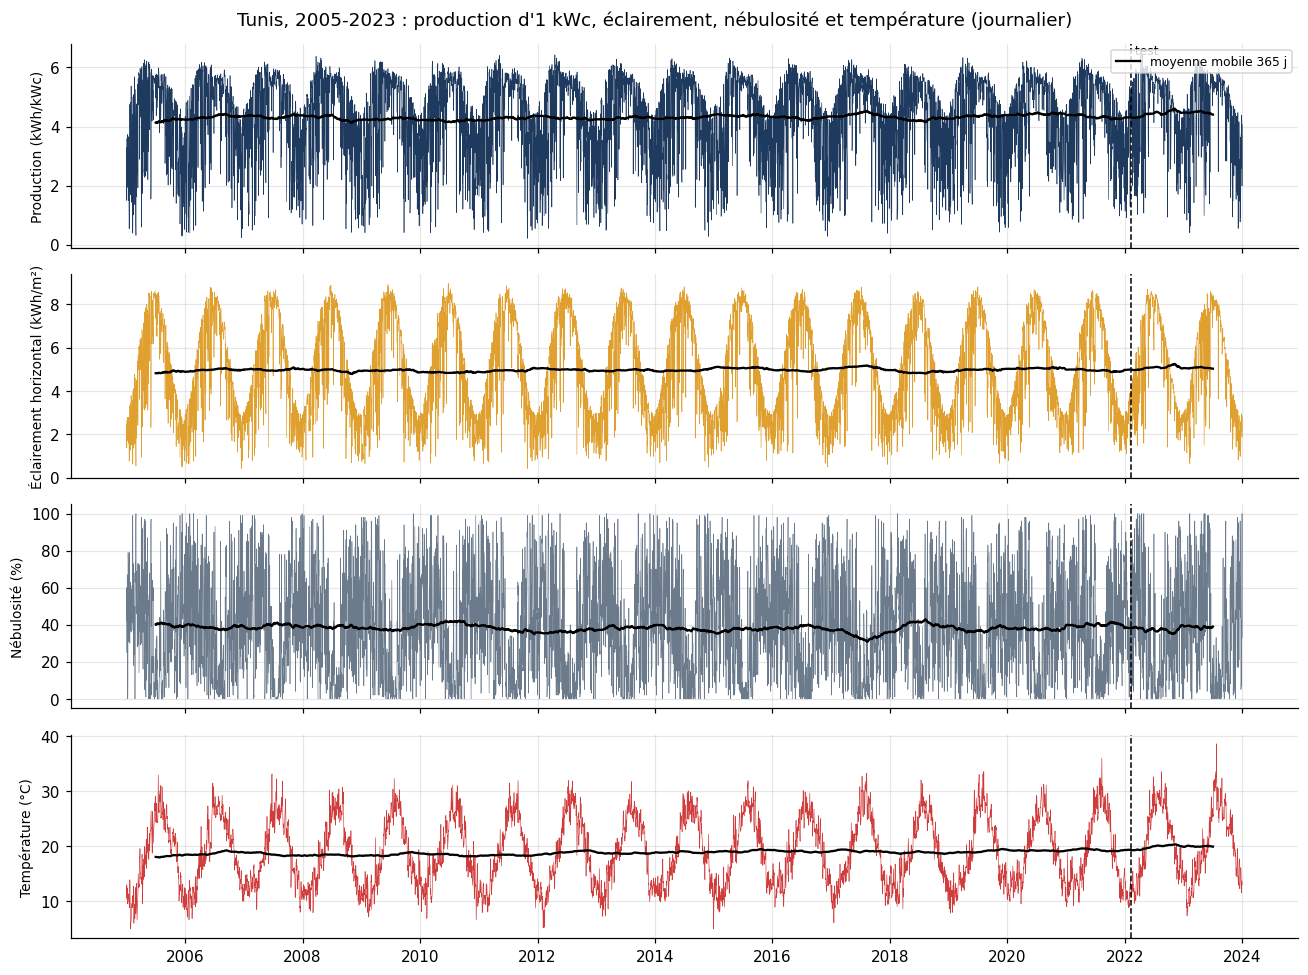

                  moyenne  écart-type  variance    min      max  skewness  kurtosis (excès)
pv_kwh_kwc          4.295       1.402     1.965  0.211    6.427    -0.815            -0.277
ghi_kwh_m2          4.947       2.258     5.098  0.419    8.970     0.068            -1.322
nebulosite_pct     38.295      27.333   747.107  0.000  100.000     0.356            -0.887
t2m_moy_c          18.712       6.062    36.743  4.908   36.027     0.158            -1.103
precipitation_mm    1.159       3.556    12.648  0.000   78.900     6.815            78.351
aerosols_aod        0.245       0.195     0.038  0.030    2.830     3.348            20.031

Production moyenne par mois (kWh/kWc/j) : {1: 3.2, 2: 3.67, 3: 4.23, 4: 4.73, 5: 4.99, 6: 5.21, 7: 5.43, 8: 5.22, 9: 4.45, 10: 3.98, 11: 3.4, 12: 3.06}
Écart-type par mois                     : {1: 1.25, 2: 1.35, 3: 1.53, 4: 1.41, 5: 1.25, 6: 0.85, 7: 0.41, 8: 0.69, 9: 1.1, 10: 1.18, 11: 1.17, 12: 1.15}
Production annuelle (kWh/kWc) : {2005: 1508, 2006:

In [6]:
# Vue d'ensemble de la série multidimensionnelle de Tunis : production, éclairement horizontal,
# nébulosité et température n'ont pas la même échelle, on les trace sur des axes séparés.
fig, ax = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
for a, (col, lib, c) in zip(ax, [(CIBLE, "Production (kWh/kWc)", "#1f3a5f"),
                                 ("ghi_kwh_m2", "Éclairement horizontal (kWh/m²)", "#e0a030"),
                                 ("nebulosite_pct", "Nébulosité (%)", "#6b7b8c"),
                                 ("t2m_moy_c", "Température (°C)", "#d03b3b")]):
    a.plot(df.index, df[col], lw=0.4, color=c)
    a.plot(df.index, df[col].rolling(365, center=True).mean(), color="k", lw=1.5, label="moyenne mobile 365 j")
    a.set_ylabel(lib, fontsize=9)
    a.axvline(test.index[0], color="k", ls="--", lw=1)
ax[0].legend(loc="upper right", fontsize=8)
ax[0].text(test.index[0], ax[0].get_ylim()[1] * 0.95, " test", fontsize=8)
fig.suptitle("Tunis, 2005-2023 : production d'1 kWc, éclairement, nébulosité et température (journalier)")
montrer(fig, "01_series_tunis")

COLS_STAT = [CIBLE, "ghi_kwh_m2", "nebulosite_pct", "t2m_moy_c", "precipitation_mm", "aerosols_aod"]
stats_desc = pd.DataFrame({"moyenne": train[COLS_STAT].mean(), "écart-type": train[COLS_STAT].std(),
                           "variance": train[COLS_STAT].var(), "min": train[COLS_STAT].min(),
                           "max": train[COLS_STAT].max(), "skewness": train[COLS_STAT].skew(),
                           "kurtosis (excès)": train[COLS_STAT].kurt()}).round(3)
stats_desc.to_csv(RES / "py_stats_descriptives.csv")
print(stats_desc.to_string())
mois_moy = train.groupby(train.index.month)[CIBLE].agg(["mean", "std"])
print("\nProduction moyenne par mois (kWh/kWc/j) :", mois_moy["mean"].round(2).to_dict())
print("Écart-type par mois                     :", mois_moy["std"].round(2).to_dict())
print("Production annuelle (kWh/kWc) :", df.groupby(df.index.year)[CIBLE].sum().round(0).astype(int).to_dict())

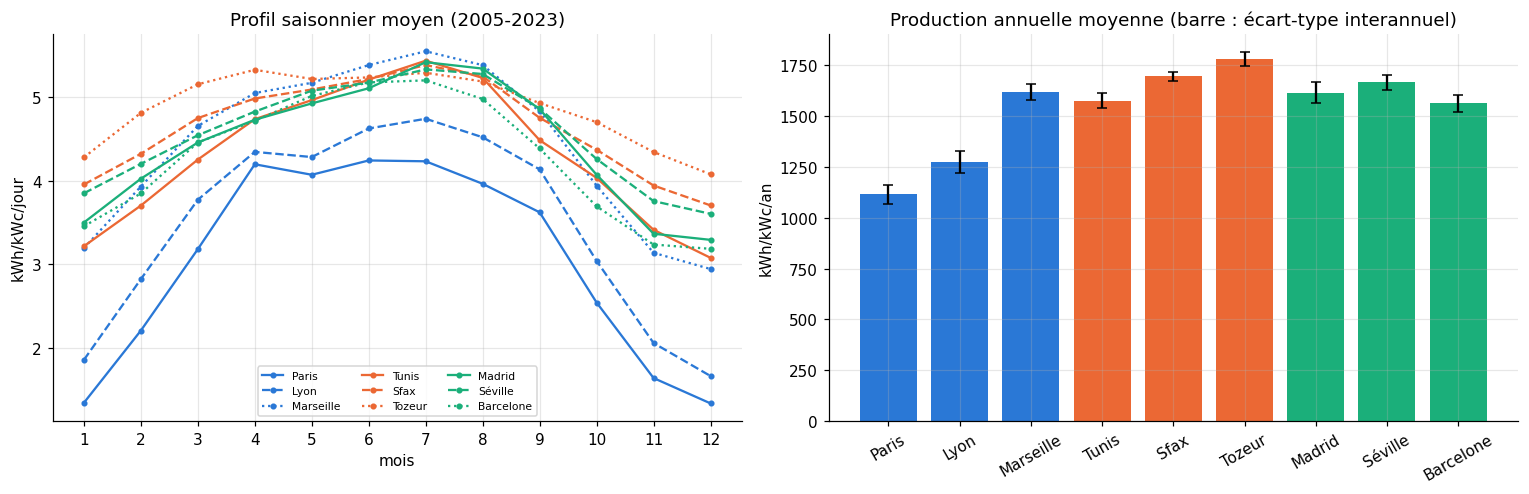

Production annuelle moyenne (kWh/kWc) : {'paris': 1114, 'lyon': 1275, 'marseille': 1618, 'tunis': 1575, 'sfax': 1695, 'tozeur': 1780, 'madrid': 1615, 'seville': 1666, 'barcelone': 1562}
Écart-type interannuel (kWh/kWc)      : {'paris': 49, 'lyon': 55, 'marseille': 39, 'tunis': 37, 'sfax': 24, 'tozeur': 34, 'madrid': 50, 'seville': 38, 'barcelone': 41}


In [7]:
# Comparaison des 9 villes : profil saisonnier moyen et production annuelle. Les échelles sont
# directement comparables puisque toutes les séries sont exprimées pour 1 kWc.
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
styles = ["-", "--", ":"]
for pays, couleur in COULEUR_PAYS.items():
    sites_p = [s for s, v in SITES.items() if v["pays"] == pays]
    for st, s in zip(styles, sites_p):
        d = panel[panel["site"] == s]
        prof = d.groupby(d["date"].dt.month)[CIBLE].mean()
        ax[0].plot(prof.index, prof.to_numpy(), ls=st, color=couleur, marker="o", ms=3, label=SITES[s]["ville"])
ax[0].set_xticks(range(1, 13)); ax[0].set_xlabel("mois"); ax[0].set_ylabel("kWh/kWc/jour")
ax[0].set_title("Profil saisonnier moyen (2005-2023)"); ax[0].legend(fontsize=7, ncol=3)
annuel = panel.groupby(["site", panel["date"].dt.year])[CIBLE].sum().groupby("site").agg(["mean", "std"])
annuel = annuel.loc[list(SITES)]
ax[1].bar([SITES[s]["ville"] for s in annuel.index], annuel["mean"], yerr=annuel["std"], capsize=3,
          color=[COULEUR_PAYS[SITES[s]["pays"]] for s in annuel.index])
ax[1].set_ylabel("kWh/kWc/an"); ax[1].set_title("Production annuelle moyenne (barre : écart-type interannuel)")
ax[1].tick_params(axis="x", labelrotation=30)
montrer(fig, "02_comparaison_villes")
print("Production annuelle moyenne (kWh/kWc) :", annuel["mean"].round(0).astype(int).to_dict())
print("Écart-type interannuel (kWh/kWc)      :", annuel["std"].round(0).astype(int).to_dict())

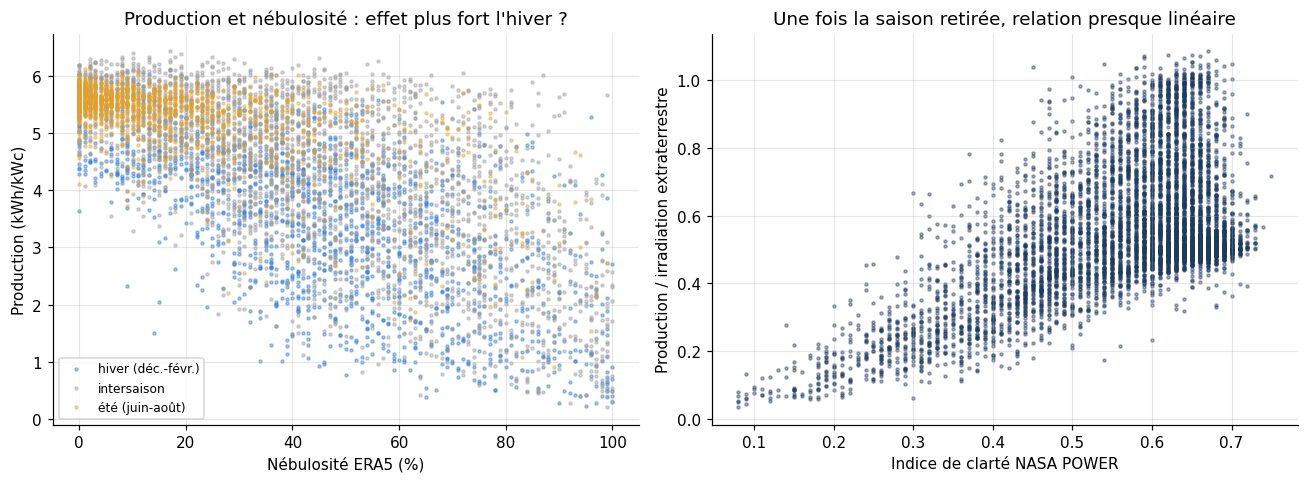

Corrélation production / nébulosité : -0.691 | par saison : {'hiver (déc.-févr.)': np.float64(-0.606), 'intersaison': np.float64(-0.649), 'été (juin-août)': np.float64(-0.67)}
Corrélation production normalisée / indice de clarté : 0.573


In [8]:
# Relation production / nébulosité : la forme du nuage de points guide le choix des variables
# exogènes (linéaires ou non) avant tout modèle multivarié.
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
saison = train.index.month.map(lambda m: "été (juin-août)" if m in (6, 7, 8) else
                               "hiver (déc.-févr.)" if m in (12, 1, 2) else "intersaison")
for s_, c in (("hiver (déc.-févr.)", "#2a78d6"), ("intersaison", "#999999"), ("été (juin-août)", "#e0a030")):
    m = saison == s_
    ax[0].scatter(train.loc[m, "nebulosite_pct"], train.loc[m, CIBLE], s=4, alpha=0.4, color=c, label=s_)
ax[0].set_xlabel("Nébulosité ERA5 (%)"); ax[0].set_ylabel("Production (kWh/kWc)"); ax[0].legend(fontsize=8)
ax[0].set_title("Production et nébulosité : effet plus fort l'hiver ?")
ax[1].scatter(train["indice_clarte"], train[CIBLE] / train["irr_extraterrestre_kwh_m2"], s=4, alpha=0.4, color="#1f3a5f")
ax[1].set_xlabel("Indice de clarté NASA POWER"); ax[1].set_ylabel("Production / irradiation extraterrestre")
ax[1].set_title("Une fois la saison retirée, relation presque linéaire")
montrer(fig, "03_production_nebulosite")
print("Corrélation production / nébulosité :", round(train[CIBLE].corr(train["nebulosite_pct"]), 3),
      "| par saison :", {s_: round(train.loc[saison == s_, CIBLE].corr(train.loc[saison == s_, "nebulosite_pct"]), 3)
                         for s_ in ("hiver (déc.-févr.)", "intersaison", "été (juin-août)")})
print("Corrélation production normalisée / indice de clarté :",
      round((train[CIBLE] / train["irr_extraterrestre_kwh_m2"]).corr(train["indice_clarte"]), 3))

**Lecture.**
- **Saisonnalité annuelle marquée mais modérée :** la production moyenne va de 3,06 kWh/kWc par jour en décembre à 5,43 en juillet, un rapport de 1,8 (environ 3 à Paris, figure 02).
- **Une variance qui baisse quand le niveau monte :** l'écart-type journalier vaut 1,25 à 1,53 kWh/kWc de décembre à avril, et seulement 0,41 en juillet. L'été tunisien est presque toujours clair ; l'hiver et le printemps alternent journées claires et perturbations.
- **Pas de tendance :** la moyenne mobile sur 365 jours reste entre 4,1 et 4,5 kWh/kWc ; la production annuelle varie de 1 508 (2005) à 1 635 kWh/kWc (2017), avec un écart-type d'une année à l'autre de 37 kWh/kWc (2,3 %). La température, elle, monte (section 2.6).
- **Distribution asymétrique à gauche (skewness -0,82) :** la production est bornée par le ciel clair ; les mauvaises journées sont rares mais très basses (2,1 % des jours sous 1 kWh/kWc, minimum 0,21).
- **Neuf villes, deux régimes :** le gradient nord-sud est surtout hivernal. En décembre, Paris produit 1,35 kWh/kWc par jour contre environ 4,1 à Tozeur ; en juillet, les neuf villes sont entre 4,2 et 5,5. La production varie davantage d'une année à l'autre au nord (écart-type de 55 kWh/kWc à Lyon, 49 à Paris) qu'au sud (24 à Sfax).
- **Lien avec la nébulosité :** corrélation de -0,69, de -0,61 en hiver à -0,67 en été. Le nuage de points est large : à nébulosité égale, la production varie beaucoup (nuages fins ou épais, moment de la journée). Divisée par le rayonnement extraterrestre, la production suit l'indice de clarté de NASA POWER (r = 0,57) : la relation avec la transparence de l'atmosphère est presque linéaire.

### 2.2 Choix de la transformation

In [9]:
# Faut-il passer au logarithme ? Un log se justifie si la dispersion croît avec le niveau. On
# compare, mois par mois, le niveau moyen et l'écart-type de la production.
mm = train[CIBLE].resample("MS").agg(["mean", "std"])
pente, ord0, r_lin, p_lin, _ = stats.linregress(mm["mean"], mm["std"])
print(f"Écart-type mensuel ~ moyenne mensuelle : pente = {pente:.3f}, r = {r_lin:.2f}, p = {p_lin:.1e}")
print("Part des jours sous 1 kWh/kWc :", round(100 * (train[CIBLE] < 1).mean(), 2), "% ; minimum :",
      round(train[CIBLE].min(), 3))
log_skew = np.log(train[CIBLE].clip(lower=0.05)).skew()
print(f"Asymétrie : série brute {train[CIBLE].skew():.2f} ; après log {log_skew:.2f}")

Écart-type mensuel ~ moyenne mensuelle : pente = -0.241, r = -0.57, p = 4.1e-19
Part des jours sous 1 kWh/kWc : 2.11 % ; minimum : 0.211
Asymétrie : série brute -0.82 ; après log -1.99


**Lecture.** L'écart-type mensuel diminue quand le niveau augmente (pente -0,24 ; r = -0,57 ; p = 4e-19) : c'est l'inverse de la situation qui justifie un logarithme ou une transformation de Box-Cox. Le logarithme aggraverait d'ailleurs l'asymétrie (de -0,82 à -1,99) en étirant les mauvaises journées. **La série est donc modélisée en niveau**, en kWh/kWc, unité directement interprétable. L'hétéroscédasticité, qui suit les saisons, est traitée par un modèle de variance conditionnelle en section 3.3 plutôt que par une transformation.

### 2.3 ACF et PACF

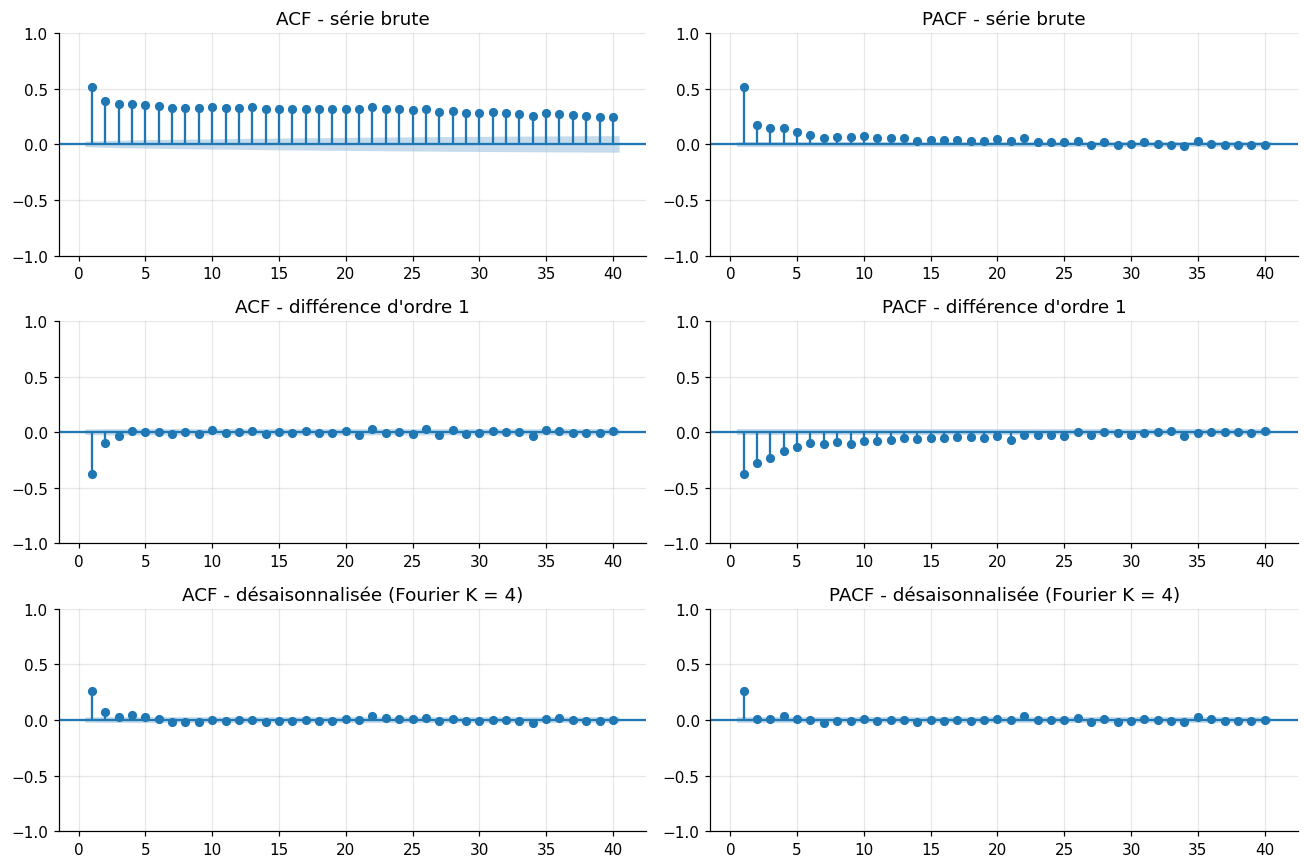

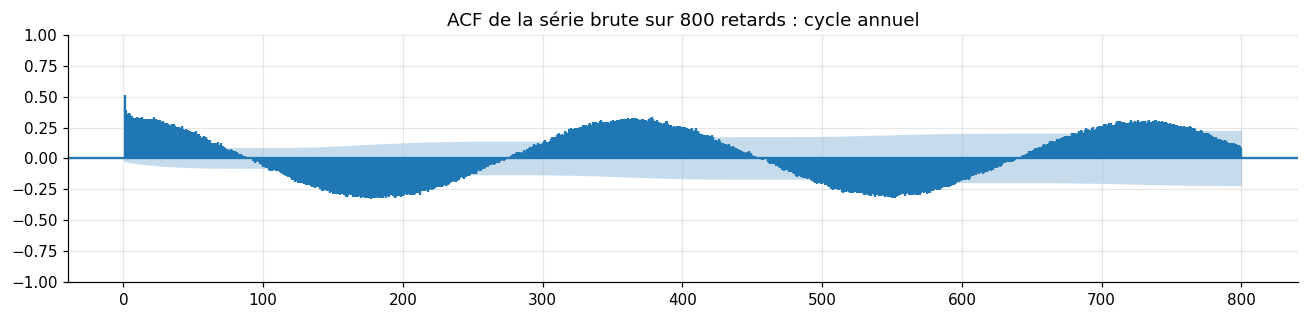

ACF série brute, retards 1, 2, 7, 30, 182, 365 : [ 0.512  0.388  0.325  0.283 -0.311  0.329]
ACF  désaisonnalisée, retards 1 à 7 : [ 0.26   0.073  0.032  0.042  0.03   0.01  -0.019]
PACF désaisonnalisée, retards 1 à 7 : [ 0.26   0.006  0.012  0.033  0.011 -0.003 -0.025]
ACF différence d'ordre 1, retards 1 à 5 : [-0.374 -0.099 -0.034  0.015  0.005]
Part de variance expliquée par les termes de Fourier (K = 4) : 0.341


In [10]:
# Saisonnalité annuelle déterministe : on la représente par des termes de Fourier (K harmoniques de
# la période 365,25 jours). La série « désaisonnalisée » est le résidu de cette régression, estimée
# sur l'apprentissage seulement.
t_jour = np.arange(n)


def fourier(K, t=t_jour):
    return np.column_stack([f(2 * np.pi * k * t / 365.25) for k in range(1, K + 1) for f in (np.sin, np.cos)])


X4 = sm.add_constant(fourier(4))
beta4 = np.linalg.lstsq(X4[:n_train], y_train, rcond=None)[0]
anomalie = pd.Series(y_all - X4 @ beta4, index=df.index)
s = train[CIBLE]
variantes = {"série brute": s, "différence d'ordre 1": s.diff().dropna(),
             "désaisonnalisée (Fourier K = 4)": anomalie.iloc[:n_train]}
fig, ax = plt.subplots(3, 2, figsize=(12, 8))
for i, (nom, v) in enumerate(variantes.items()):
    plot_acf(v, lags=40, ax=ax[i, 0], title=f"ACF - {nom}", zero=False)
    plot_pacf(v, lags=40, ax=ax[i, 1], title=f"PACF - {nom}", zero=False, method="ywm")
montrer(fig, "04_acf_pacf")
fig, ax = plt.subplots(figsize=(12, 3))
plot_acf(s, lags=800, ax=ax, title="ACF de la série brute sur 800 retards : cycle annuel", zero=False, marker=None)
montrer(fig, "05_acf_long")
acf_v = sm.tsa.acf(s, nlags=400)
print("ACF série brute, retards 1, 2, 7, 30, 182, 365 :", np.round(acf_v[[1, 2, 7, 30, 182, 365]], 3))
acf_a = sm.tsa.acf(anomalie.iloc[:n_train], nlags=30)
pacf_a = sm.tsa.pacf(anomalie.iloc[:n_train], nlags=30, method="ywm")
print("ACF  désaisonnalisée, retards 1 à 7 :", np.round(acf_a[1:8], 3))
print("PACF désaisonnalisée, retards 1 à 7 :", np.round(pacf_a[1:8], 3))
acf_d = sm.tsa.acf(s.diff().dropna(), nlags=10)
print("ACF différence d'ordre 1, retards 1 à 5 :", np.round(acf_d[1:6], 3))
print("Part de variance expliquée par les termes de Fourier (K = 4) :",
      round(1 - anomalie.iloc[:n_train].var() / s.var(), 3))

**Lecture.**
- **Série brute :** ACF de 0,51 au retard 1, 0,39 au retard 2, encore 0,28 au retard 30, puis -0,31 à 182 jours et +0,33 à 365 jours. Cette persistance apparente vient du cycle annuel (figure 05), pas de la météo.
- **Différence d'ordre 1 :** ACF de -0,37 au retard 1, signature d'une sur-différenciation : la série n'a pas de racine unitaire, il ne faut pas la différencier.
- **Série désaisonnalisée** (termes de Fourier, 34 % de la variance) : ACF de 0,26 au retard 1, puis 0,07, 0,03 et des valeurs négligeables ; PACF de 0,26 au retard 1, puis nulle. C'est la signature d'un **AR(1)** : la météo d'un jour renseigne faiblement sur celle du lendemain, et presque plus sur celle du surlendemain.
- **Ordres candidats :** d = 0 ; p de 1 à 3 et q de 0 à 2, comparés en section 3.1 ; cycle annuel représenté par K = 2 à 4 harmoniques. Il n'y a pas de saisonnalité hebdomadaire : la météo ignore le calendrier.

### 2.4 Décomposition

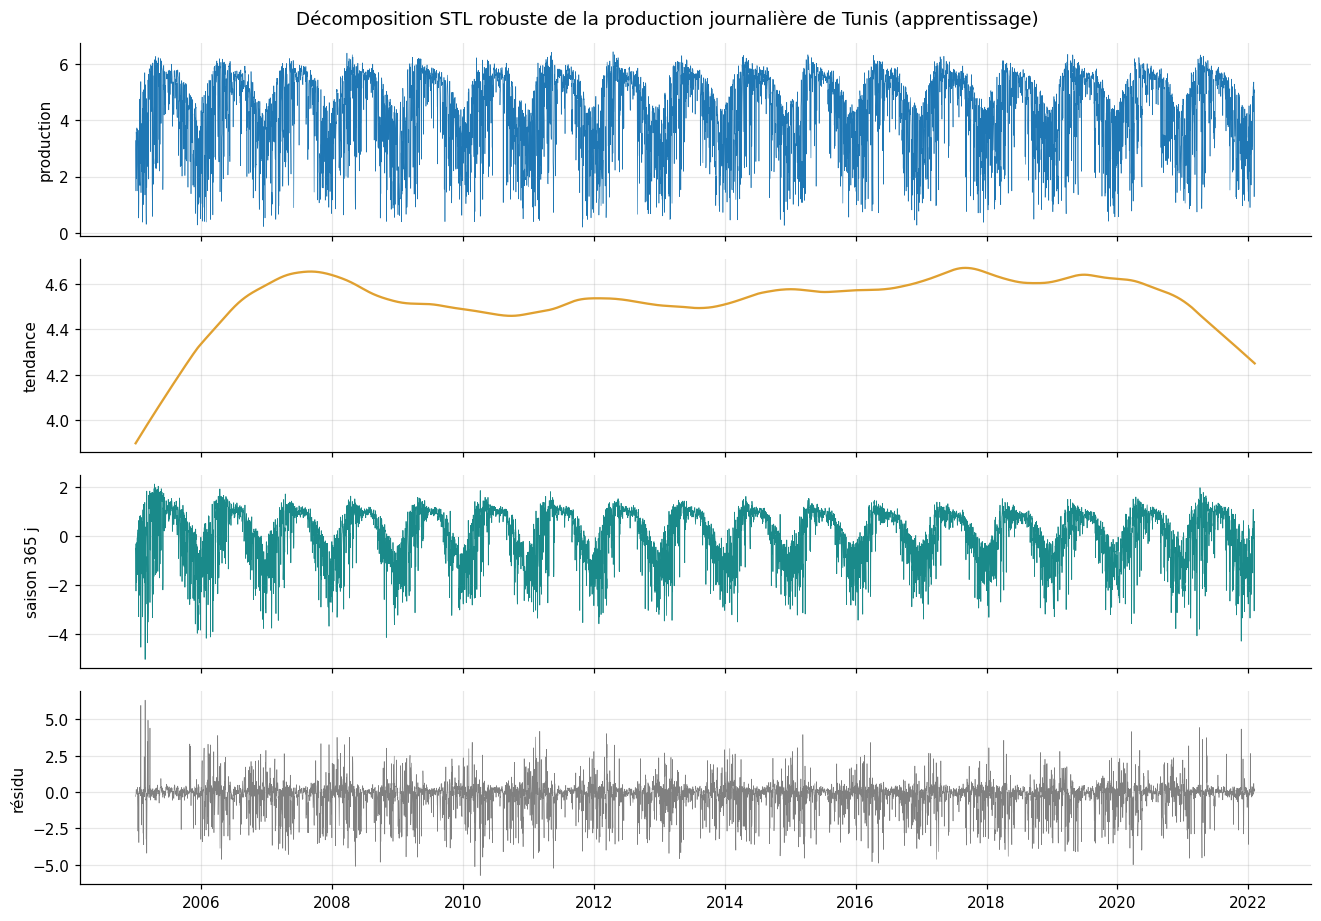

Part de variance : tendance 0.008 | saison 0.646 | résidu 0.597
Tendance : minimum 3.898 le 2005-01-01 | maximum 4.67 le 2017-09-05
Pente linéaire de la tendance : 9.5 Wh/kWc/jour par an
Écart-type du résidu par mois : {1: 1.23, 2: 1.32, 3: 1.4, 4: 1.32, 5: 1.21, 6: 0.77, 7: 0.37, 8: 0.64, 9: 0.97, 10: 1.06, 11: 1.13, 12: 1.07}
Asymétrie du résidu : -0.9 | kurtosis : 3.85


In [11]:
# Décomposition STL (période 365 jours, version robuste aux valeurs extrêmes) : elle sépare la
# tendance lente, le cycle annuel et le résidu météorologique de court terme.
stl = STL(train[CIBLE], period=365, robust=True).fit()
fig, ax = plt.subplots(4, 1, figsize=(12, 8.5), sharex=True)
ax[0].plot(train[CIBLE], lw=0.4); ax[0].set_ylabel("production")
ax[1].plot(stl.trend, color="#e0a030"); ax[1].set_ylabel("tendance")
ax[2].plot(stl.seasonal, lw=0.5, color="#1a8a8a"); ax[2].set_ylabel("saison 365 j")
ax[3].plot(stl.resid, lw=0.4, color="grey"); ax[3].set_ylabel("résidu")
fig.suptitle("Décomposition STL robuste de la production journalière de Tunis (apprentissage)")
montrer(fig, "06_decomposition_stl")
var_tot = train[CIBLE].var()
print("Part de variance : tendance", round(stl.trend.var() / var_tot, 3), "| saison",
      round(stl.seasonal.var() / var_tot, 3), "| résidu", round(stl.resid.var() / var_tot, 3))
print("Tendance : minimum", round(stl.trend.min(), 3), "le", stl.trend.idxmin().date(), "| maximum",
      round(stl.trend.max(), 3), "le", stl.trend.idxmax().date())
pente_tend = np.polyfit(np.arange(len(stl.trend)) / 365.25, stl.trend.to_numpy(), 1)[0]
print(f"Pente linéaire de la tendance : {pente_tend * 1000:.1f} Wh/kWc/jour par an")
res_stl = stl.resid
print("Écart-type du résidu par mois :", res_stl.groupby(res_stl.index.month).std().round(2).to_dict())
print("Asymétrie du résidu :", round(res_stl.skew(), 2), "| kurtosis :", round(res_stl.kurt(), 2))

**Lecture de chaque composante.**
- **Saison annuelle :** 65 % de la variance, d'environ 3,1 à 5,4 kWh/kWc, très régulière d'une année à l'autre.
- **Tendance :** moins de 1 % de la variance. Elle part de 3,90 kWh/kWc (effet de bord du lissage en 2005), culmine à 4,67 en 2017 et croît de 9,5 Wh/kWc par jour et par an, soit environ +3,5 kWh/kWc par an (+0,2 %). C'est faible, et cela peut traduire aussi bien une atmosphère moins chargée en aérosols qu'une dérive de la série satellitaire : on ne l'interprète pas sans mesure au sol.
- **Résidu :** 60 % de la variance (les parts ne s'additionnent pas exactement, les composantes étant corrélées). C'est la météo de court terme. Son écart-type va de 1,40 kWh/kWc en mars à 0,37 en juillet, et il est asymétrique (-0,90) : les jours de perturbation tirent vers le bas.

### 2.5 Valeurs aberrantes

Erreurs de données (trous de la base SARAH3) : 13 jours sur 6939 à Tunis
             PVGIS brut  corrigé  GHI NASA  GHI ERA5  nébulosité (%)
date                                                               
2005-04-18        1.53     5.63      6.74      6.83              38
2008-01-23        0.00     3.41      2.35      2.16              41
2008-03-01        0.01     4.24      3.91      4.12              51
2008-03-06        0.00     4.56      4.40      4.42              56
2008-05-17        0.00     5.31      7.01      6.97              33
2008-05-18        0.00     5.45      7.20      7.09              32
2009-04-18        0.00     4.15      4.74      4.07              93
2009-04-19        0.00     5.07      5.81      5.17              75
2009-08-15        0.00     5.40      6.56      6.04              39
2009-08-16        0.00     5.19      6.23      6.24              20
2014-12-02        0.59     3.93      2.78      2.73              45
2016-10-16        0.00     4.68      4.35 

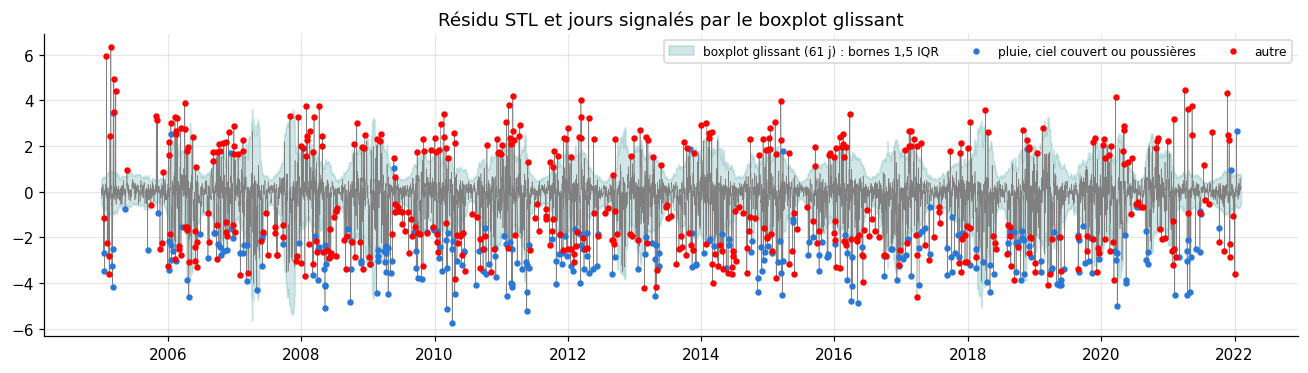

In [12]:
# Deux familles de valeurs aberrantes, à ne pas confondre.
# 1. Erreurs de données : jours où la base satellitaire a des trous, que PVGIS enregistre comme des
#    zéros. La collecte les repère par deux contrôles de cohérence (hauteur du soleil incompatible avec
#    l'astronomie, irradiation PVGIS très inférieure à celle de deux sources indépendantes) et les
#    corrige (`jour_impute_pvgis`). On montre ici la valeur brute et la valeur corrigée.
imputes = df.index[df["jour_impute_pvgis"] == 1]
f_brut = DATA / "brut" / "pvgis" / f"{SITE}_horaire.parquet"
if not f_brut.exists():                 # cache brut absent (archive allégée) : on retélécharge cette seule série
    from collecte_donnees import pvgis_horaire, pvgis_synthese
    f_brut.parent.mkdir(parents=True, exist_ok=True)
    pvgis_horaire(SITE, pvgis_synthese(SITE)["inputs"]["mounting_system"]["fixed"]["slope"]["value"])
brut_h = pd.read_parquet(f_brut)
brut_j = brut_h["P"].groupby(brut_h.index.floor("D")).sum() / 1000
tab_imp = pd.DataFrame({"PVGIS brut": brut_j.reindex(imputes), "corrigé": df.loc[imputes, CIBLE],
                        "GHI NASA": df.loc[imputes, "ghi_nasa_kwh_m2"], "GHI ERA5": df.loc[imputes, "ghi_era5_kwh_m2"],
                        "nébulosité (%)": df.loc[imputes, "nebulosite_pct"]})
print(f"Erreurs de données (trous de la base SARAH3) : {len(imputes)} jours sur {n} à Tunis\n", tab_imp.round(2).to_string())

# 2. Valeurs extrêmes mais vraies : journées très couvertes ou pluvieuses. La dispersion du résidu STL
#    varie du simple au triple entre l'été et l'hiver : une règle de l'IQR globale signalerait presque
#    tous les jours d'hiver. On utilise donc un boxplot glissant (quartiles sur 61 jours centrés).
FEN = 61
q1 = res_stl.rolling(FEN, center=True, min_periods=30).quantile(0.25)
q3 = res_stl.rolling(FEN, center=True, min_periods=30).quantile(0.75)
iqr = q3 - q1
q1g, q3g = res_stl.quantile(0.25), res_stl.quantile(0.75)
ab_global = (res_stl < q1g - 1.5 * (q3g - q1g)) | (res_stl > q3g + 1.5 * (q3g - q1g))
ab15 = (res_stl < q1 - 1.5 * iqr) | (res_stl > q3 + 1.5 * iqr)
ab3 = (res_stl < q1 - 3 * iqr) | (res_stl > q3 + 3 * iqr)
pluie = train["precipitation_mm"] >= 5
couvert = train["nebulosite_pct"] >= 80
poussiere = train["aerosols_aod"] >= 0.8
print(f"\nRègle de l'IQR globale : {int(ab_global.sum())} jours ({100 * ab_global.mean():.1f} %), dont "
      f"{int((ab_global & np.isin(train.index.month, [11, 12, 1, 2, 3])).sum())} de novembre à mars")
print(f"Boxplot glissant, seuil 1,5 IQR : {int(ab15.sum())} jours ({100 * ab15.mean():.1f} %) ; "
      f"{int((ab15 & (res_stl < 0)).sum())} bas, {int((ab15 & (res_stl > 0)).sum())} hauts")
bas = ab15 & (res_stl < 0)
print(f"  parmi les jours bas : pluie >= 5 mm {int((bas & pluie).sum())}, nébulosité >= 80 % {int((bas & couvert).sum())}, "
      f"aérosols >= 0,8 {int((bas & poussiere).sum())}, au moins l'un des trois {int((bas & (pluie | couvert | poussiere)).sum())}")
print(f"Boxplot glissant, seuil 3 IQR : {int(ab3.sum())} jours")
print("Jours corrigés à la collecte parmi les jours signalés :", int(train.loc[ab15, "jour_impute_pvgis"].sum()))
tab_ab = train.loc[ab15, [CIBLE, "nebulosite_pct", "precipitation_mm", "aerosols_aod"]].assign(residu=res_stl[ab15])
print("Les 8 jours les plus bas :\n", tab_ab.sort_values("residu").head(8).round(2).to_string())
print("Mois des jours signalés :", tab_ab.index.month.value_counts().sort_index().to_dict())
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(res_stl, lw=0.4, color="grey")
ax.fill_between(res_stl.index, q1 - 1.5 * iqr, q3 + 1.5 * iqr, color="#1a8a8a", alpha=0.2, label="boxplot glissant (61 j) : bornes 1,5 IQR")
expl = ab15 & (pluie | couvert | poussiere)
ax.scatter(res_stl.index[expl], res_stl[expl], color="#2a78d6", s=10, label="pluie, ciel couvert ou poussières", zorder=3)
ax.scatter(res_stl.index[ab15 & ~expl], res_stl[ab15 & ~expl], color="red", s=10, label="autre", zorder=3)
ax.set_title("Résidu STL et jours signalés par le boxplot glissant"); ax.legend(fontsize=8, ncol=3)
montrer(fig, "07_aberrants")

**Lecture et traitement.**
- **Erreurs de données, corrigées :** 13 jours à Tunis où PVGIS donnait 0 à 1,5 kWh/kWc alors que NASA POWER et ERA5 voyaient une journée ordinaire (2,2 à 7,2 kWh/m²) sous une nébulosité modérée. Ce sont des trous de la base satellitaire SARAH3 (dix journées entièrement à zéro, trois en partie). Les garder aurait créé de faux records de volatilité et biaisé tous les modèles. Ils sont imputés à la collecte (énergie NASA du jour multipliée par le rapport PVGIS/NASA des 31 jours voisins) et signalés par `jour_impute_pvgis`.
- **Règle de l'IQR globale, inadaptée :** elle signale 1 093 jours (17,5 %), dont 616 de novembre à mars, simplement parce que la dispersion est plus forte en hiver.
- **Boxplot glissant (61 jours) :** 803 jours signalés (12,9 %), 595 bas et 208 hauts ; 323 au seuil strict de 3 IQR. La moitié des jours bas (298) s'expliquent par une pluie d'au moins 5 mm (174 jours), un ciel couvert à plus de 80 % (195) ou des poussières (55 jours avec une épaisseur optique d'au moins 0,8). Les 8 jours les plus bas cumulent ciel couvert et pluie ou poussières (le 2 avril 2016 : épaisseur optique de 1,30). L'autre moitié tombe surtout en été, où la dispersion locale est si faible qu'une baisse modeste est déjà signalée, ou correspond à des nuages mal situés par la réanalyse.
- **Décision :** ces valeurs extrêmes sont vraies et conservées, sans variable indicatrice : imprévisibles ex ante, elles doivent élargir les intervalles. Les modèles ex post les expliquent par la météo, et leur concentration en saison humide est modélisée par la variance conditionnelle (section 3.3).

### 2.6 Stationnarité

In [13]:
# ADF (H0 : racine unitaire) et KPSS (H0 : stationnarité) ont des hypothèses nulles opposées :
# on ne conclut que lorsque les deux tests racontent la même histoire.
def tests_stationnarite(v, nom, regression="c"):
    v = pd.Series(v).dropna()
    adf_stat, adf_p, adf_lag, *_ = adfuller(v, autolag="AIC", regression=regression)
    kpss_stat, kpss_p, _, _ = kpss(v, regression=regression, nlags="auto")
    if adf_p < 0.05 and kpss_p >= 0.05:
        concl = "stationnaire"
    elif adf_p >= 0.05 and kpss_p < 0.05:
        concl = "non stationnaire (racine unitaire)"
    elif adf_p < 0.05 and kpss_p < 0.05:
        concl = "désaccord (saisonnalité ou rupture ?)"
    else:
        concl = "non concluant"
    return {"série": nom, "ADF stat": round(adf_stat, 3), "ADF p": round(adf_p, 4), "ADF retards": adf_lag,
            "KPSS stat": round(kpss_stat, 3), "KPSS p": round(kpss_p, 4), "conclusion à 5 %": concl}


lignes = []
for col, lib in ((CIBLE, "production"), ("nebulosite_pct", "nébulosité"), ("t2m_moy_c", "température")):
    v = train[col]
    lignes.append(tests_stationnarite(v, f"{lib}"))
    lignes.append(tests_stationnarite(v.diff(), f"{lib} - diff. ordre 1"))
    Xf = sm.add_constant(fourier(4))[:n_train]
    lignes.append(tests_stationnarite(v.to_numpy() - Xf @ np.linalg.lstsq(Xf, v.to_numpy(), rcond=None)[0],
                                      f"{lib} - désaisonnalisée (Fourier)"))
lignes.append(tests_stationnarite(anomalie.iloc[:n_train], "production désaisonnalisée, avec tendance", "ct"))
Xf = sm.add_constant(fourier(4))[:n_train]
t_des = train["t2m_moy_c"].to_numpy() - Xf @ np.linalg.lstsq(Xf, train["t2m_moy_c"].to_numpy(), rcond=None)[0]
lignes.append(tests_stationnarite(t_des, "température désaisonnalisée, avec tendance", "ct"))
pente_t = np.polyfit(np.arange(n_train) / 365.25, t_des, 1)[0]
print(f"Tendance linéaire de la température désaisonnalisée : {10 * pente_t:+.2f} °C par décennie")
tab_stat = pd.DataFrame(lignes).set_index("série")
tab_stat.to_csv(RES / "py_stationnarite.csv")
print(tab_stat.to_string())
print("\nNote : la p-value du KPSS est bornée entre 0,01 et 0,10 par les tables de statsmodels.")

Tendance linéaire de la température désaisonnalisée : +0.59 °C par décennie
                                            ADF stat  ADF p  ADF retards  KPSS stat  KPSS p                       conclusion à 5 %
série                                                                                                                             
production                                    -5.844    0.0           25      0.027  0.1000                           stationnaire
production - diff. ordre 1                   -24.060    0.0           26      0.013  0.1000                           stationnaire
production - désaisonnalisée (Fourier)       -34.770    0.0            3      0.392  0.0808                           stationnaire
nébulosité                                    -7.406    0.0           25      0.042  0.1000                           stationnaire
nébulosité - diff. ordre 1                   -24.443    0.0           26      0.030  0.1000                           stationnaire
nébulos

**Lecture.**
- **Production, nébulosité et température en niveau :** l'ADF rejette la racine unitaire (p < 0,001) et le KPSS ne rejette pas la stationnarité (p > 0,10). Les deux tests s'accordent : les séries sont stationnaires, le cycle annuel les ramenant chaque année au même niveau.
- **Différence d'ordre 1 :** stationnaire elle aussi, mais sur-différenciée (ACF de -0,37 au retard 1, section 2.3).
- **Température désaisonnalisée :** le KPSS rejette la stationnarité autour d'une constante (statistique 1,93) mais pas autour d'une tendance (0,041). La température de Tunis est stationnaire autour d'une tendance de **+0,59 °C par décennie** sur 2005-2022, ordre de grandeur compatible avec le réchauffement observé autour de la Méditerranée. La production désaisonnalisée est stationnaire avec ou sans tendance.
- **Ordre de différenciation retenu : d = 0 et D = 0.** Le cycle annuel est déterministe et représenté par des termes de Fourier. En R, `tseries::adf.test` (tendance incluse, nombre de retards fixé) aboutit à la même conclusion.

### 2.7 Choix des variables explicatives (plus de 50 candidates)

Les jeux de données contiennent plus de 50 variables. On les classe selon leur pouvoir explicatif
avec trois critères complémentaires, calculés sur l'apprentissage seulement :
- la corrélation de rang de Spearman (lien monotone, insensible aux valeurs extrêmes) ;
- l'information mutuelle (lien quelconque, y compris non linéaire) ;
- l'importance par permutation d'un modèle de gradient boosting, mesurée sur les 15 % les plus
  récents de l'apprentissage (apport propre de la variable une fois les autres connues).

Deux usages sont distingués, car ils n'ont pas le droit aux mêmes informations :
- **prévision ex ante** de la production du lendemain : seulement ce qui est connu la veille
  (retards, météo observée de la veille, astronomie du lendemain) ;
- **estimation ex post** de la production du jour à partir de la météo du jour (cas d'une prévision
  météo parfaite). Les variables d'éclairement issues de PVGIS (dont la production est calculée) en sont
  exclues : elles rendraient le problème trivial.

In [14]:
# Préparation des deux tableaux de candidates. Les variables météo « de la veille » sont décalées
# d'un jour pour ne contenir que de l'information disponible au moment de la prévision.
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.feature_selection import mutual_info_regression
from sklearn.inspection import permutation_importance

METEO = ["nebulosite_pct", "nebulosite_nasa_pct", "ensoleillement_h", "precipitation_mm", "humidite_pct",
         "point_rosee_c", "pression_hpa", "rafales_max_kmh", "et0_mm", "t2m_moy_c", "t2m_max_c", "t2m_min_c",
         "amplitude_thermique_c", "vent_moy_ms", "aerosols_aod", "indice_uv", "albedo", "ghi_era5_kwh_m2",
         "ghi_nasa_kwh_m2", "indice_clarte", "par_kwh_m2", "ghi_ciel_clair_kwh_m2"]
ASTRO = ["irr_extraterrestre_kwh_m2", "duree_jour_astro_h", "hauteur_soleil_midi_deg", "jds_sin", "jds_cos"]
ex_ante = pd.DataFrame({f"{c}_veille": df[c].shift(1) for c in METEO}, index=df.index)
for c in ASTRO:
    ex_ante[c] = df[c]
for c in ("pv_veille", "pv_j7", "pv_moy7_passe", "pv_ecart_type7_passe", "ghi_veille", "ghi_moy7_passe"):
    ex_ante[c] = df[c]
# Exclusion des sources de rayonnement pour l'ex post : ce serait presque la cible elle-même.
EXPOST_COLS = [c for c in METEO if c not in ("ghi_era5_kwh_m2", "ghi_nasa_kwh_m2", "indice_clarte", "par_kwh_m2",
                                              "ensoleillement_h", "et0_mm", "indice_uv")] + ASTRO
ex_post = df[EXPOST_COLS].copy()
ex_post["neb_x_potentiel"] = df["nebulosite_pct"] / 100 * df["irr_extraterrestre_kwh_m2"]   # effet multiplicatif
print("Candidates ex ante :", ex_ante.shape[1], "| candidates ex post :", ex_post.shape[1])


def classer_variables(X, y, nom):
    """Spearman, information mutuelle et importance par permutation, sur l'apprentissage seulement."""
    ok = X.iloc[:n_train].notna().all(axis=1) & y.iloc[:n_train].notna()
    Xa, ya = X.iloc[:n_train][ok], y.iloc[:n_train][ok]
    coupe_ = int(len(Xa) * 0.85)
    spear = Xa.apply(lambda c: stats.spearmanr(c, ya)[0])
    mi = pd.Series(mutual_info_regression(Xa, ya, random_state=SEED), index=X.columns)
    gb = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=SEED).fit(Xa.iloc[:coupe_], ya.iloc[:coupe_])
    perm = permutation_importance(gb, Xa.iloc[coupe_:], ya.iloc[coupe_:], n_repeats=5, random_state=SEED,
                                  scoring="neg_mean_squared_error")
    r2 = gb.score(Xa.iloc[coupe_:], ya.iloc[coupe_:])
    tab_ = pd.DataFrame({"|Spearman|": spear.abs(), "info. mutuelle": mi,
                         "permutation (hausse du MSE)": perm.importances_mean}, index=X.columns)
    tab_["rang moyen"] = tab_.rank(ascending=False).mean(axis=1)
    tab_ = tab_.sort_values("rang moyen")
    print(f"{nom} : R² du gradient boosting sur la validation = {r2:.3f}")
    return tab_


imp_ante = classer_variables(ex_ante, df[CIBLE], "Ex ante (production du lendemain)")
imp_post = classer_variables(ex_post, df[CIBLE], "Ex post (production du jour, météo du jour connue)")
imp_ante.to_csv(RES / "py_importance_variables_ex_ante.csv")
imp_post.to_csv(RES / "py_importance_variables_ex_post.csv")
print("\nEx ante, 12 premières :\n", imp_ante.head(12).round(3).to_string())
print("\nEx post, 12 premières :\n", imp_post.head(12).round(3).to_string())

Candidates ex ante : 33 | candidates ex post : 21


Ex ante (production du lendemain) : R² du gradient boosting sur la validation = 0.396


Ex post (production du jour, météo du jour connue) : R² du gradient boosting sur la validation = 0.785

Ex ante, 12 premières :
                               |Spearman|  info. mutuelle  permutation (hausse du MSE)  rang moyen
ensoleillement_h_veille            0.640           0.311                        0.047       4.000
irr_extraterrestre_kwh_m2          0.626           0.313                        0.080       5.000
ghi_ciel_clair_kwh_m2_veille       0.636           0.311                        0.022       5.667
par_kwh_m2_veille                  0.664           0.305                        0.011       7.000
ghi_era5_kwh_m2_veille             0.660           0.299                        0.012       7.667
indice_uv_veille                   0.639           0.289                        0.011       9.667
jds_cos                            0.621           0.310                        0.010      10.000
ghi_nasa_kwh_m2_veille             0.667           0.313                       -0.003  

VIF des variables météo retenues (avec saisonnalité) : {'nebulosite_pct': 5.35, 'precipitation_mm': 1.42, 'humidite_pct': 1.92, 'amplitude_thermique_c': 1.78, 'aerosols_aod': 1.59, 'nebulosite_nasa_pct': 5.95, 'pression_hpa': 1.43}


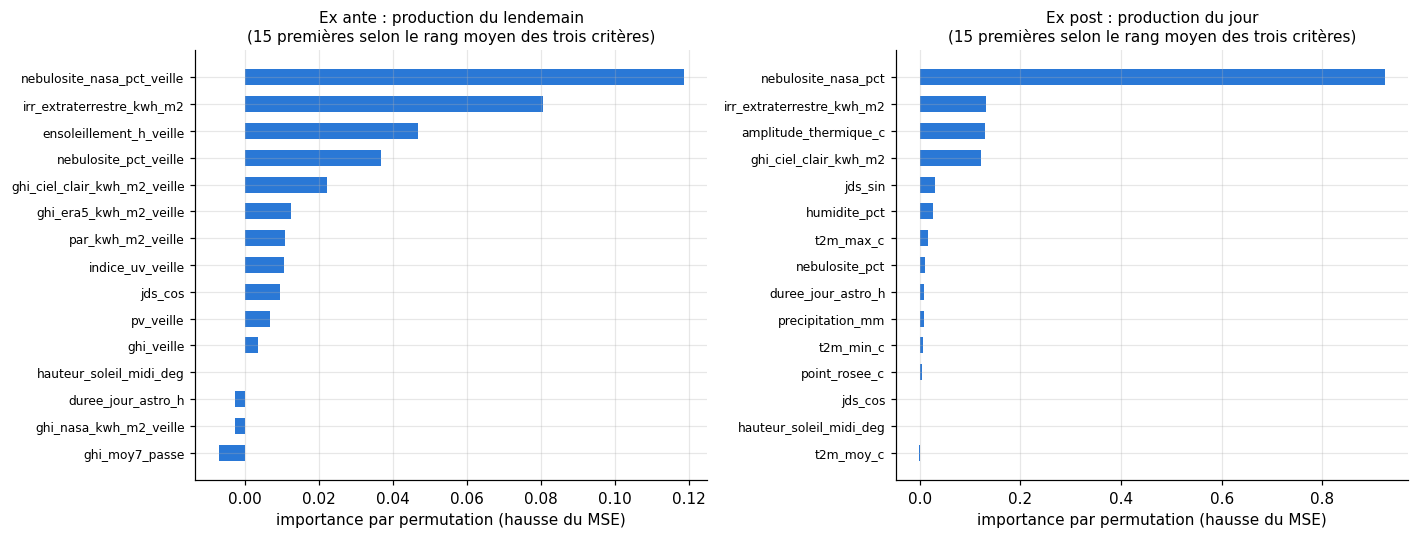

In [15]:
# Redondance : facteur d'inflation de la variance (VIF) des variables retenues. Un VIF élevé
# (> 10) signale une variable presque combinaison linéaire des autres, inutile dans un modèle linéaire.
from statsmodels.stats.outliers_influence import variance_inflation_factor

SEL_POST = ["nebulosite_pct", "precipitation_mm", "humidite_pct", "amplitude_thermique_c", "aerosols_aod",
            "nebulosite_nasa_pct", "pression_hpa"]
Xv_ = sm.add_constant(pd.concat([ex_post[SEL_POST].iloc[:n_train],
                                 pd.DataFrame(fourier(2)[:n_train], index=df.index[:n_train])], axis=1).dropna())
vif = pd.Series([variance_inflation_factor(Xv_.to_numpy(), i) for i in range(1, len(SEL_POST) + 1)], index=SEL_POST)
print("VIF des variables météo retenues (avec saisonnalité) :", vif.round(2).to_dict())
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, (tab_, titre) in zip(ax, ((imp_ante, "Ex ante : production du lendemain"),
                                 (imp_post, "Ex post : production du jour"))):
    top = tab_.head(15).sort_values("permutation (hausse du MSE)")
    a.barh(top.index, top["permutation (hausse du MSE)"], color="#2a78d6", height=0.6)
    a.set_title(f"{titre}\n(15 premières selon le rang moyen des trois critères)", fontsize=10)
    a.set_xlabel("importance par permutation (hausse du MSE)")
    a.tick_params(axis="y", labelsize=8)
montrer(fig, "08_importance_variables")

**Lecture et choix.**
- **Ex ante, la production du lendemain est peu prévisible :** avec 33 variables, le gradient boosting n'explique que 40 % de la variance sur la validation. Les variables utiles sont le rayonnement de la veille (ensoleillement, irradiation ERA5 ou NASA, rayonnement photosynthétique), la position dans l'année (rayonnement extraterrestre, cosinus du jour) et surtout la nébulosité satellite de la veille (plus forte importance par permutation : 0,12).
- **Redondance :** les trois sources d'irradiation ont chacune une corrélation de Spearman d'environ 0,66 avec la cible, mais une importance par permutation presque nulle : elles se remplacent l'une l'autre. Plus de variables n'apporte pas plus d'information.
- **Ex post, la météo du jour explique 79 % de la variance.** La nébulosité satellite de NASA domine (importance 0,92), devant le potentiel solaire du jour (rayonnement extraterrestre et par ciel clair), l'amplitude thermique (un ciel clair donne une forte amplitude), l'humidité et la pluie.
- **Multicolinéarité :** VIF de 5,4 et 6,0 pour les deux nébulosités, inférieurs à 2 pour les autres variables retenues : acceptable (seuil usuel de 10).
- **Choix.** Pour les modèles ex post (SARIMAX météo, réseaux ex post), on garde les variables qu'**une prévision météo fournit** : nébulosité ERA5, pluie, humidité, amplitude thermique et aérosols, plus l'interaction nébulosité x potentiel solaire. La nébulosité NASA est écartée bien qu'elle soit la plus informative : c'est une observation satellite, disponible après coup mais pas en prévision ; elle servirait à l'estimation en temps réel. Les variables de rayonnement sont exclues car quasi tautologiques. Pour les modèles ex ante (XGBoost, réseaux), on garde les retards, la météo de la veille et l'astronomie.

## 3. Modélisation classique
### 3.1 ARIMA et SARIMA

**Pourquoi pas un SARIMA journalier de période 365 ?** La seule saisonnalité de la production est
annuelle (le soleil ne connaît pas les jours de la semaine). Un SARIMA de période 365 demanderait un
état de plus de 365 dimensions, estimé sur 17 cycles seulement. On suit la recommandation classique
(Hyndman et Athanasopoulos, *Forecasting: Principles and Practice*, chap. 10) : régression harmonique
dynamique, c'est-à-dire un ARIMA sur la série dont le cycle annuel est représenté par des termes de
Fourier. Le SARIMA saisonnier au sens strict (P, D, Q, s) est estimé en 3.1 bis sur la série mensuelle,
où la période (s = 12) le permet.

In [16]:
# Recherche manuelle guidée par l'ACF/PACF de la série désaisonnalisée : d = 0 (section 2.6), ordres
# p et q faibles, nombre d'harmoniques K à choisir. Tous les modèles ont la même différenciation :
# leurs AIC/BIC sont comparables.
BRULAGE = 7       # premiers résidus écartés : l'initialisation du filtre les fausse
duree, nb_param = {}, {}


def ajuster_arima(order, K, X_extra=None, y=y_train):
    """ARIMA à erreurs corrélées sur termes de Fourier (+ variables exogènes éventuelles)."""
    X = fourier(K)[:len(y)] if K else None
    if X_extra is not None:
        X = X_extra[:len(y)] if X is None else np.column_stack([X, X_extra[:len(y)]])
    return ARIMA(y, exog=X, order=order, trend="c").fit(method="innovations_mle", gls=True)


t0 = time.time()
grille = []
for K in (2, 3, 4):
    for order in [(1, 0, 0), (2, 0, 0), (3, 0, 0), (1, 0, 1), (2, 0, 1), (1, 0, 2), (2, 0, 2)]:
        m = ajuster_arima(order, K)
        grille.append({"ordre": order, "K": K, "AIC": m.aic, "BIC": m.bic, "sigma": np.sqrt(m.params[-1])})
grille = pd.DataFrame(grille).sort_values("BIC").reset_index(drop=True)
grille.round(3).to_csv(RES / "py_grille_arima.csv", index=False)
print(grille.round(2).head(12).to_string())
ORDRE, K_F = grille.loc[0, "ordre"], int(grille.loc[0, "K"])
print(f"\nModèle manuel retenu (BIC minimal) : ARIMA{ORDRE} + Fourier K = {K_F}  ({time.time() - t0:.0f} s)")

        ordre  K       AIC       BIC  sigma
0   (1, 0, 0)  2  18930.40  18977.58    1.1
1   (1, 0, 0)  3  18925.01  18985.67    1.1
2   (1, 0, 1)  2  18931.94  18985.85    1.1
3   (2, 0, 0)  2  18931.99  18985.91    1.1
4   (1, 0, 2)  2  18929.72  18990.37    1.1
5   (2, 0, 1)  2  18931.00  18991.65    1.1
6   (3, 0, 0)  2  18932.63  18993.29    1.1
7   (1, 0, 1)  3  18926.71  18994.10    1.1
8   (2, 0, 0)  3  18926.74  18994.14    1.1
9   (1, 0, 0)  4  18923.98  18998.12    1.1
10  (2, 0, 2)  2  18931.19  18998.59    1.1
11  (1, 0, 2)  3  18925.29  18999.42    1.1

Modèle manuel retenu (BIC minimal) : ARIMA(1, 0, 0) + Fourier K = 2  (8 s)


In [17]:
# Confirmation par recherche automatique (pmdarima, équivalent Python d'auto.arima) : mêmes termes de
# Fourier en variables exogènes, ordres et différenciation choisis par l'algorithme.
import pmdarima as pm
from pmdarima.arima import ndiffs

print("Différenciation suggérée : d (ADF) =", ndiffs(y_train, test="adf"), "| d (KPSS) =",
      ndiffs(y_train, test="kpss"), "| d (PP) =", ndiffs(y_train, test="pp"))
t0 = time.time()
auto = pm.auto_arima(y_train, X=fourier(K_F)[:n_train], seasonal=False, stepwise=True,
                     information_criterion="aic", max_p=4, max_q=4, maxiter=50,
                     suppress_warnings=True, error_action="ignore")
ORDRE_AUTO = auto.order
print(f"pmdarima.auto_arima : ARIMA{ORDRE_AUTO} + Fourier K = {K_F}, constante = {auto.with_intercept}, "
      f"AIC = {auto.aic():.1f}  ({time.time() - t0:.0f} s)")

Différenciation suggérée : d (ADF) = 0 | d (KPSS) = 0 | d (PP) = 0


pmdarima.auto_arima : ARIMA(1, 0, 0) + Fourier K = 2, constante = True, AIC = 18930.4  (40 s)


In [18]:
# Modèles comparés : ARIMA manuel, ARIMA automatique, et ARIMA manuel enrichi de la météo du jour
# (« ex post » : nébulosité, pluie, humidité, amplitude thermique, aérosols, plus le terme
# d'interaction nébulosité x potentiel solaire, car un ciel couvert coûte plus de kWh en été).
EXO_POST = ["nebulosite_pct", "neb_x_potentiel", "precipitation_mm", "humidite_pct", "amplitude_thermique_c",
            "aerosols_aod"]
X_meteo = ex_post[EXO_POST].ffill().bfill().to_numpy(float)
specs = {"ARIMA-Fourier manuel": (ORDRE, None), "ARIMA-Fourier auto": (ORDRE_AUTO, None),
         "SARIMAX météo": (ORDRE, X_meteo)}
modeles = {}
for nom, (o, Xe) in specs.items():
    t0 = time.time()
    m = auto.arima_res_ if nom == "ARIMA-Fourier auto" else ajuster_arima(o, K_F, Xe)
    modeles[nom] = (m, Xe)
    duree[nom], nb_param[nom] = time.time() - t0, len(m.params)
    print(f"{nom:22s} ARIMA{o} K={K_F}  AIC = {m.aic:9.1f}  BIC = {m.bic:9.1f}  sigma = {np.sqrt(m.params[-1]):.3f} kWh/kWc"
          f"  ({duree[nom]:.1f} s)")
m_man, m_auto, m_meteo = (modeles[k][0] for k in specs)
noms_m = ["const"] + [f"fourier_{i}" for i in range(2 * K_F)] + EXO_POST
coef = pd.DataFrame({"coef": m_meteo.params, "écart-type": m_meteo.bse, "p": m_meteo.pvalues},
                    index=noms_m + list(m_meteo.param_names[len(noms_m):])).round(5)
coef.to_csv(RES / "py_coef_sarimax_meteo.csv")
print("\nCoefficients du SARIMAX météo :\n", coef.to_string())
print("\nParamètres ARMA du modèle manuel :", {k: round(v, 4) for k, v in zip(m_man.param_names, m_man.params)
                                              if k.startswith(("ar.", "ma.", "sigma"))})

ARIMA-Fourier manuel   ARIMA(1, 0, 0) K=2  AIC =   18930.4  BIC =   18977.6  sigma = 1.100 kWh/kWc  (0.2 s)
ARIMA-Fourier auto     ARIMA(1, 0, 0) K=2  AIC =   18930.4  BIC =   18977.6  sigma = 1.100 kWh/kWc  (0.0 s)


SARIMAX météo          ARIMA(1, 0, 0) K=2  AIC =   14428.4  BIC =   14516.1  sigma = 0.767 kWh/kWc  (0.3 s)

Coefficients du SARIMAX météo :
                           coef  écart-type        p
const                  4.51180     0.10592  0.00000
fourier_0              0.25196     0.01834  0.00000
fourier_1             -0.55600     0.03722  0.00000
fourier_2             -0.02820     0.01642  0.08597
fourier_3             -0.32092     0.01775  0.00000
nebulosite_pct        -0.02564     0.00148  0.00000
neb_x_potentiel        0.04712     0.01778  0.00803
precipitation_mm      -0.06347     0.00185  0.00000
humidite_pct           0.00225     0.00131  0.08643
amplitude_thermique_c  0.09304     0.00422  0.00000
aerosols_aod          -0.96438     0.04517  0.00000
ar.L1                  0.10865     0.01133  0.00000
sigma2                 0.58764     0.00968  0.00000

Paramètres ARMA du modèle manuel : {'ar.L1': np.float64(0.2629), 'sigma2': np.float64(1.2107)}


**Lecture.**
- **Recherche manuelle :** le BIC retient ARIMA(1,0,0) avec K = 2 harmoniques (BIC de 18 977,6). L'AIC préférerait K = 4 (18 924,0), mais ce gain ne justifie pas quatre paramètres de plus.
- **Recherche automatique :** avec les mêmes termes de Fourier, `pmdarima.auto_arima` retient exactement le même modèle, comme `auto.arima` en R. Les tests de différenciation (ADF, KPSS, Phillips-Perron) donnent tous d = 0. Les deux approches convergent, ce qui conforte l'identification par l'ACF et la PACF.
- **Coefficients :** AR(1) = 0,263, cohérent avec l'ACF de la série désaisonnalisée (0,26) ; écart-type de l'erreur à un jour de 1,10 kWh/kWc.
- **SARIMAX météo :** l'écart-type de l'erreur tombe à 0,767 kWh/kWc (-30 %) et l'AIC de 18 930 à 14 428. Chaque coefficient a un sens physique : -0,026 kWh/kWc par point de nébulosité (-0,26 pour 10 points), effet un peu atténué en été (interaction positive de 0,047, p = 0,008) ; -0,063 par mm de pluie ; **-0,96 par unité d'épaisseur optique des aérosols** (un épisode de poussières sahariennes à 1,0 coûte environ 1 kWh/kWc, soit 20 % d'une journée moyenne) ; +0,093 par degré d'amplitude thermique. L'humidité n'est pas significative (p = 0,09). Le coefficient AR(1) tombe à 0,11 : la persistance de la production venait surtout de celle de la météo.

                      LB(10) p  LB(30) p  max |ACF| (1-30)  au retard  JB p  skewness  kurtosis  ARCH-LM(7) stat  ARCH-LM(7) p
modèle                                                                                                                        
ARIMA-Fourier manuel    0.0921    0.2509            0.0345         22   0.0   -0.9365    3.7135         234.9850           0.0
ARIMA-Fourier auto      0.0921    0.2510            0.0345         22   0.0   -0.9364    3.7136         234.9812           0.0
SARIMAX météo           0.0621    0.0171            0.0340         22   0.0   -0.5215    3.8330         134.5376           0.0
Seuil de significativité d'une autocorrélation (2 / racine de n) : 0.025
Écart-type des résidus par saison (manuel) : hiver 1.21 | été 0.641


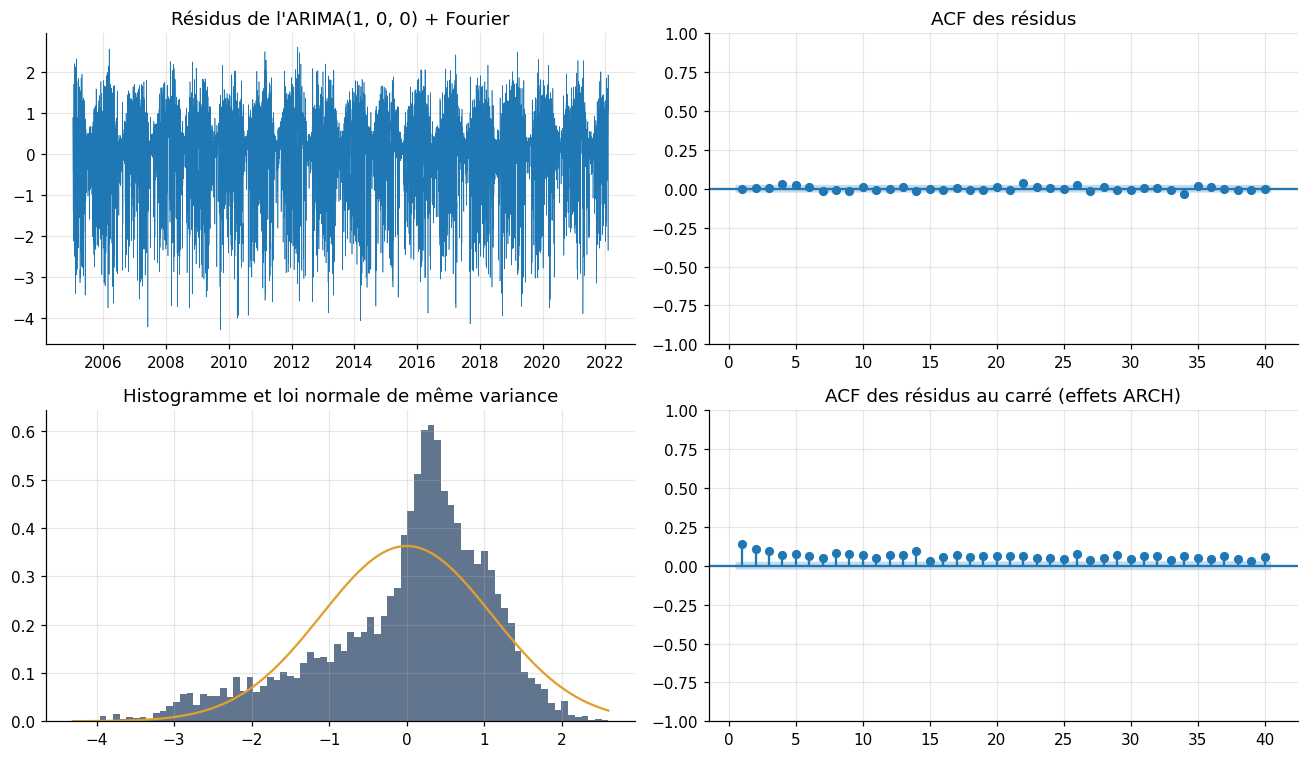

In [19]:
# Diagnostic des résidus : un modèle n'est acceptable que si ses résidus ressemblent à un bruit
# blanc (Ljung-Box), idéalement gaussien (Jarque-Bera) et de variance constante (ARCH-LM).
def diagnostic(resid, nom, n_arma):
    r = np.asarray(resid)[BRULAGE:]
    lb = acorr_ljungbox(r, lags=[10, 30], model_df=n_arma)
    jb_stat, jb_p, skew, kurt = jarque_bera(r)
    lm, lm_p, _, _ = het_arch(r, nlags=7)
    rho = sm.tsa.acf(r, nlags=30)[1:]
    return {"modèle": nom, "LB(10) p": lb["lb_pvalue"].iloc[0], "LB(30) p": lb["lb_pvalue"].iloc[1],
            "max |ACF| (1-30)": np.abs(rho).max(), "au retard": int(np.abs(rho).argmax()) + 1,
            "JB p": jb_p, "skewness": skew, "kurtosis": kurt, "ARCH-LM(7) stat": lm, "ARCH-LM(7) p": lm_p}


diag = []
for nom, (m, _) in modeles.items():
    n_arma = sum(1 for p_ in m.param_names if p_.startswith(("ar.", "ma.")))
    diag.append(diagnostic(m.resid, nom, n_arma))
tab_diag = pd.DataFrame(diag).set_index("modèle")
tab_diag.to_csv(RES / "py_diagnostics_arima.csv")
print(tab_diag.round(4).to_string())
print("Seuil de significativité d'une autocorrélation (2 / racine de n) :", round(2 / np.sqrt(n_train - BRULAGE), 3))
r = np.asarray(m_man.resid)[BRULAGE:]
print("Écart-type des résidus par saison (manuel) : hiver",
      round(r[np.isin(train.index[BRULAGE:].month, [12, 1, 2])].std(), 3), "| été",
      round(r[np.isin(train.index[BRULAGE:].month, [6, 7, 8])].std(), 3))

fig, ax = plt.subplots(2, 2, figsize=(12, 7))
ax[0, 0].plot(train.index[BRULAGE:], r, lw=0.4); ax[0, 0].set_title(f"Résidus de l'ARIMA{ORDRE} + Fourier")
plot_acf(r, lags=40, ax=ax[0, 1], zero=False, title="ACF des résidus")
ax[1, 0].hist(r, bins=80, density=True, color="#1f3a5f", alpha=0.7)
xx = np.linspace(r.min(), r.max(), 200); ax[1, 0].plot(xx, stats.norm.pdf(xx, r.mean(), r.std()), color="#e0a030")
ax[1, 0].set_title("Histogramme et loi normale de même variance")
plot_acf(r ** 2, lags=40, ax=ax[1, 1], zero=False, title="ACF des résidus au carré (effets ARCH)")
montrer(fig, "09_diagnostic_arima")

**Lecture du diagnostic.**
- **Indépendance (Ljung-Box) :** non rejetée pour l'ARIMA-Fourier (p = 0,09 à 10 retards, 0,25 à 30). La plus forte autocorrélation résiduelle vaut 0,035 pour un seuil de 0,025 avec 6 238 observations : négligeable. Le SARIMAX météo laisse une légère autocorrélation à 30 retards (p = 0,017, maximum de 0,034).
- **Normalité (Jarque-Bera) :** rejetée (p < 0,001), avec une asymétrie de -0,94 et une kurtosis de 3,71. Les mauvaises surprises (journée couverte inattendue) sont plus fortes que les bonnes, la production ne pouvant pas dépasser celle du ciel clair. Les intervalles gaussiens sont donc approximatifs ; leur couverture réelle est mesurée en section 6.
- **Homoscédasticité (ARCH-LM) :** massivement rejetée (statistique de 235, p de l'ordre de 1e-47). L'écart-type des résidus vaut 1,21 kWh/kWc en hiver contre 0,64 en été, et l'ACF des carrés décroît lentement : c'est l'objet de la section 3.3.
- **Bilan :** la moyenne conditionnelle est bien spécifiée, la variance ne l'est pas.

### 3.1 bis SARIMA saisonnier sur la série mensuelle (s = 12)

Série mensuelle : 228 mois, apprentissage 205 (2005-01 -> 2022-01), test 23
D suggéré : OCSB = 0 | Canova-Hansen = 0


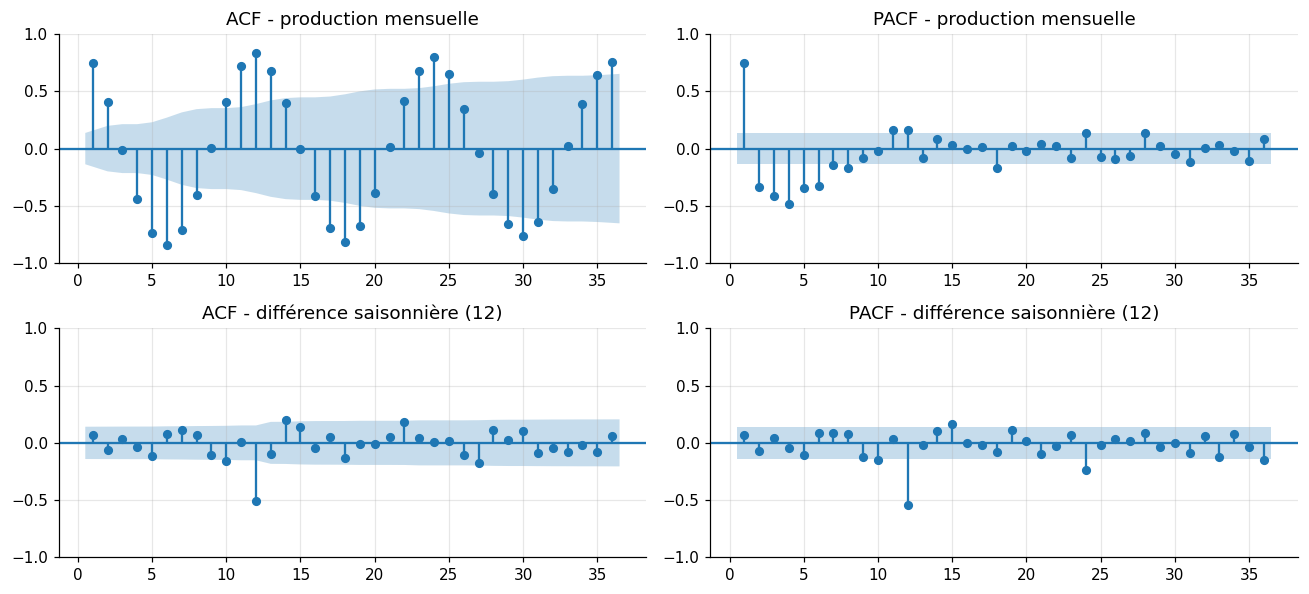

ACF diff. saisonnière, retards 1, 2, 12, 24 : [ 0.065 -0.065 -0.512  0.009]
Stationnarité de la différence saisonnière : {'série': 'diff12', 'ADF stat': -4.552, 'ADF p': 0.0002, 'ADF retards': 14, 'KPSS stat': np.float64(0.055), 'KPSS p': np.float64(0.1), 'conclusion à 5 %': 'stationnaire'}


       ordre saisonnier     AIC     BIC
0  (0, 0, 0)  (0, 1, 1)  1411.7  1418.3
1  (0, 0, 0)  (1, 1, 1)  1411.9  1421.7
2  (0, 0, 1)  (0, 1, 1)  1412.8  1422.6
3  (1, 0, 0)  (0, 1, 1)  1413.0  1422.8
4  (0, 0, 1)  (1, 1, 1)  1413.1  1426.1
5  (1, 0, 0)  (1, 1, 1)  1413.2  1426.3
6  (1, 0, 1)  (0, 1, 1)  1414.1  1427.1
7  (1, 0, 1)  (1, 1, 1)  1414.0  1430.3


Manuel : SARIMA(0, 0, 0)(0, 1, 1)[12] | auto_arima : SARIMA(1, 0, 0)(1, 0, 1)[12], constante = True
Paramètres : {'ma.S.L12': np.float64(-0.889), 'sigma2': np.float64(78.255)}
Diagnostic : LB(12) p = 0.4548 | JB p = 0.2051 | ARCH-LM(4) p = 0.83

Évaluation sur 18 origines, horizon 6 mois (kWh/kWc/mois) :
                                   RMSE    MAE  MAPE (%)
Naïf saisonnier (même mois N-1)  17.70  13.47      9.87
Moyenne mensuelle                12.26   9.69      7.15
SARIMA manuel                    12.36   9.65      7.08
SARIMA auto                      12.68   9.85      7.18


In [20]:
# À la maille mensuelle, la période saisonnière vaut 12 : on peut identifier (p,d,q)(P,D,Q)[12] à la
# lecture de l'ACF/PACF, comme le demande l'énoncé, puis confirmer par auto_arima.
from pmdarima.arima import nsdiffs

ym = df[CIBLE].resample("MS").sum()
nm = len(ym)
nm_train = int(nm * 0.9)
ym_train = ym.iloc[:nm_train]
print(f"Série mensuelle : {nm} mois, apprentissage {nm_train} ({ym.index[0]:%Y-%m} -> {ym.index[nm_train - 1]:%Y-%m}),"
      f" test {nm - nm_train}")
print("D suggéré : OCSB =", nsdiffs(ym_train.to_numpy(), m=12, test="ocsb"), "| Canova-Hansen =",
      nsdiffs(ym_train.to_numpy(), m=12, test="ch"))
fig, ax = plt.subplots(2, 2, figsize=(12, 5.5))
plot_acf(ym_train, lags=36, ax=ax[0, 0], zero=False, title="ACF - production mensuelle")
plot_pacf(ym_train, lags=36, ax=ax[0, 1], zero=False, title="PACF - production mensuelle", method="ywm")
d12 = ym_train.diff(12).dropna()
plot_acf(d12, lags=36, ax=ax[1, 0], zero=False, title="ACF - différence saisonnière (12)")
plot_pacf(d12, lags=36, ax=ax[1, 1], zero=False, title="PACF - différence saisonnière (12)", method="ywm")
montrer(fig, "10_acf_mensuel")
print("ACF diff. saisonnière, retards 1, 2, 12, 24 :", np.round(sm.tsa.acf(d12, nlags=24)[[1, 2, 12, 24]], 3))
print("Stationnarité de la différence saisonnière :", tests_stationnarite(d12, "diff12"))

grille_m = []
for order in [(0, 0, 0), (1, 0, 0), (0, 0, 1), (1, 0, 1)]:
    for seas in [(0, 1, 1), (1, 1, 0), (1, 1, 1), (2, 1, 0)]:
        mm_ = ARIMA(ym_train.to_numpy(), order=order, seasonal_order=seas + (12,), trend="n").fit()
        grille_m.append({"ordre": order, "saisonnier": seas, "AIC": mm_.aic, "BIC": mm_.bic})
grille_m = pd.DataFrame(grille_m).sort_values("BIC").reset_index(drop=True)
grille_m.round(2).to_csv(RES / "py_grille_sarima_mensuel.csv", index=False)
print(grille_m.round(1).head(8).to_string())
ORDRE_M, SAISON_M = grille_m.loc[0, "ordre"], grille_m.loc[0, "saisonnier"]
auto_m = pm.auto_arima(ym_train.to_numpy(), m=12, seasonal=True, stepwise=True, information_criterion="aic",
                       suppress_warnings=True, error_action="ignore")
print(f"Manuel : SARIMA{ORDRE_M}{SAISON_M}[12] | auto_arima : SARIMA{auto_m.order}{auto_m.seasonal_order[:3]}[12]"
      f", constante = {auto_m.with_intercept}")
m_mens = ARIMA(ym_train.to_numpy(), order=ORDRE_M, seasonal_order=SAISON_M + (12,), trend="n").fit()
print("Paramètres :", {k: round(v, 3) for k, v in zip(m_mens.param_names, m_mens.params)})
rm = np.asarray(m_mens.resid)[13:]
print("Diagnostic : LB(12) p =", round(acorr_ljungbox(rm, lags=[12])["lb_pvalue"].iloc[0], 4),
      "| JB p =", round(jarque_bera(rm)[1], 4), "| ARCH-LM(4) p =", round(het_arch(rm, nlags=4)[1], 4))

# Prévision à 6 mois depuis chaque origine du test, comparée au naïf saisonnier (même mois de
# l'année précédente) et à la moyenne mensuelle de l'apprentissage.
HM = 6
orig_m = np.arange(nm_train - 1, nm - HM)
ymv = ym.to_numpy()
clim_m = ym_train.groupby(ym_train.index.month).mean()
complet_m = m_mens.apply(ymv)
complet_auto_m = auto_m.arima_res_.apply(ymv)
pm_ = {"Naïf saisonnier (même mois N-1)": np.stack([ymv[t + 1 - 12:t + 1 + HM - 12] for t in orig_m]),
       "Moyenne mensuelle": np.stack([clim_m.loc[ym.index[t + 1:t + 1 + HM].month].to_numpy() for t in orig_m]),
       "SARIMA manuel": np.stack([complet_m.get_prediction(start=t + 1, end=t + HM, dynamic=0).predicted_mean for t in orig_m]),
       "SARIMA auto": np.stack([complet_auto_m.get_prediction(start=t + 1, end=t + HM, dynamic=0).predicted_mean for t in orig_m])}
Ym = np.stack([ymv[t + 1:t + 1 + HM] for t in orig_m])
tab_m = pd.DataFrame({nom: {"RMSE": np.sqrt(np.mean((Ym - P) ** 2)), "MAE": np.mean(np.abs(Ym - P)),
                            "MAPE (%)": 100 * np.mean(np.abs(Ym - P) / Ym)} for nom, P in pm_.items()}).T
tab_m.to_csv(RES / "py_metriques_mensuel.csv")
print(f"\nÉvaluation sur {len(orig_m)} origines, horizon 6 mois (kWh/kWc/mois) :\n", tab_m.round(2).to_string())

**Lecture.**
- **Identification :** OCSB et Canova-Hansen ne demandent pas de différence saisonnière (D = 0, saisonnalité déterministe). L'ACF de la différence saisonnière présente pourtant le pic négatif au retard 12 (-0,51) typique d'une moyenne mobile saisonnière ; le BIC retient SARIMA(0,0,0)(0,1,1)[12], dont le coefficient saisonnier vaut -0,889. Proche de -1, il annule presque la différence saisonnière : le modèle revient à une moyenne mensuelle lentement mobile, ce qui rejoint le verdict des tests. `auto_arima` retient SARIMA(1,0,0)(1,0,1)[12] avec constante, sans différence.
- **Diagnostic :** résidus blancs (Ljung-Box p = 0,45), gaussiens (Jarque-Bera p = 0,21) et homoscédastiques (ARCH-LM p = 0,83). À la maille mensuelle, les aléas journaliers se compensent : les défauts du modèle journalier disparaissent.
- **Prévision à 6 mois (18 origines) :** le SARIMA (RMSE de 12,36 kWh/kWc par mois) fait jeu égal avec la moyenne mensuelle de l'apprentissage (12,26) et bat nettement le naïf saisonnier (17,70). À cet horizon, seul le cycle annuel est prévisible ; l'année précédente est un mauvais prédicteur car elle porte sa propre météo.

### 3.2 Modèles multivariés : VAR, causalité de Granger et cointégration

In [21]:
# VAR sur (production, nébulosité, température) de Tunis. Les trois séries sont stationnaires autour
# d'un cycle annuel déterministe (section 2.6) : VAR en niveaux, avec les termes de Fourier en
# variables exogènes pour absorber ce cycle.
VARS = [CIBLE, "nebulosite_pct", "t2m_moy_c"]
endog_var = df[VARS].ffill().to_numpy()
Xv = fourier(3)
sel = VAR(endog_var[:n_train], exog=Xv[:n_train]).select_order(14)
print("Ordre choisi par critère :", sel.selected_orders)
crit = pd.DataFrame({"AIC": sel.ics["aic"], "BIC": sel.ics["bic"], "HQIC": sel.ics["hqic"]}).round(4)
crit.index.name = "p"
crit.to_csv(RES / "py_var_criteres.csv")
print(crit.to_string())

Ordre choisi par critère : {'aic': np.int64(3), 'bic': np.int64(3), 'hqic': np.int64(3), 'fpe': np.int64(3)}
       AIC     BIC    HQIC
p                         
0   7.4525  7.4752  7.4604
1   6.3679  6.4004  6.3792
2   6.3309  6.3731  6.3455
3   6.3146  6.3665  6.3325
4   6.3159  6.3775  6.3373
5   6.3161  6.3874  6.3408
6   6.3153  6.3964  6.3434
7   6.3160  6.4068  6.3474
8   6.3177  6.4183  6.3526
9   6.3185  6.4288  6.3568
10  6.3200  6.4401  6.3616
11  6.3219  6.4517  6.3669
12  6.3235  6.4630  6.3718
13  6.3260  6.4752  6.3777
14  6.3275  6.4864  6.3826


In [22]:
# On retient l'ordre du BIC s'il blanchit les résidus, sinon celui de l'AIC : le BIC pénalise
# davantage, mais il ne doit pas laisser d'autocorrélation.
P_VAR = max(sel.selected_orders["bic"], 1)
var_fit = VAR(endog_var[:n_train], exog=Xv[:n_train]).fit(P_VAR)
blanc = var_fit.test_whiteness(nlags=20)
print(f"VAR({P_VAR}) - Portmanteau(20) : stat = {blanc.test_statistic:.1f}, p = {blanc.pvalue:.4f}")
P_AIC = sel.selected_orders["aic"]
if blanc.pvalue < 0.05 and P_AIC > P_VAR:
    var_aic = VAR(endog_var[:n_train], exog=Xv[:n_train]).fit(P_AIC)
    b2 = var_aic.test_whiteness(nlags=max(20, P_AIC + 6))
    print(f"VAR({P_AIC}) - Portmanteau({max(20, P_AIC + 6)}) : stat = {b2.test_statistic:.1f}, p = {b2.pvalue:.4f}")
    P_VAR, var_fit = P_AIC, var_aic
print(f"\nOrdre retenu : VAR({P_VAR})")
norm_v = var_fit.test_normality()
print(f"Normalité multivariée (Jarque-Bera) : stat = {norm_v.test_statistic:.1f}, p = {norm_v.pvalue:.4f}")
rv = var_fit.resid
for j, nom in enumerate(VARS):
    lb = acorr_ljungbox(rv[:, j], lags=[10]); lm_p = het_arch(rv[:, j], nlags=7)[1]
    print(f"  équation {nom:15s} : Ljung-Box(10) p = {lb['lb_pvalue'].iloc[0]:.4f} | ARCH-LM(7) p = {lm_p:.4g}")
print("Stabilité (racines hors du cercle unité) :", var_fit.is_stable())
print("Corrélation des résidus (contemporaine) :\n", pd.DataFrame(np.corrcoef(rv.T), index=VARS, columns=VARS).round(3))

VAR(3) - Portmanteau(20) : stat = 191.8, p = 0.0183

Ordre retenu : VAR(3)
Normalité multivariée (Jarque-Bera) : stat = 1618.2, p = 0.0000
  équation pv_kwh_kwc      : Ljung-Box(10) p = 0.5413 | ARCH-LM(7) p = 8.316e-47
  équation nebulosite_pct  : Ljung-Box(10) p = 0.2600 | ARCH-LM(7) p = 2.771e-17
  équation t2m_moy_c       : Ljung-Box(10) p = 0.0801 | ARCH-LM(7) p = 4.894e-28
Stabilité (racines hors du cercle unité) : True
Corrélation des résidus (contemporaine) :
                 pv_kwh_kwc  nebulosite_pct  t2m_moy_c
pv_kwh_kwc           1.000          -0.617      0.159
nebulosite_pct      -0.617           1.000     -0.060
t2m_moy_c            0.159          -0.060      1.000


         cause          effet       F      p
    pv_kwh_kwc nebulosite_pct 14.2949 0.0000
    pv_kwh_kwc      t2m_moy_c 19.3396 0.0000
nebulosite_pct     pv_kwh_kwc 98.7503 0.0000
nebulosite_pct      t2m_moy_c  6.5244 0.0002
     t2m_moy_c     pv_kwh_kwc  2.8988 0.0336
     t2m_moy_c nebulosite_pct  4.3729 0.0044


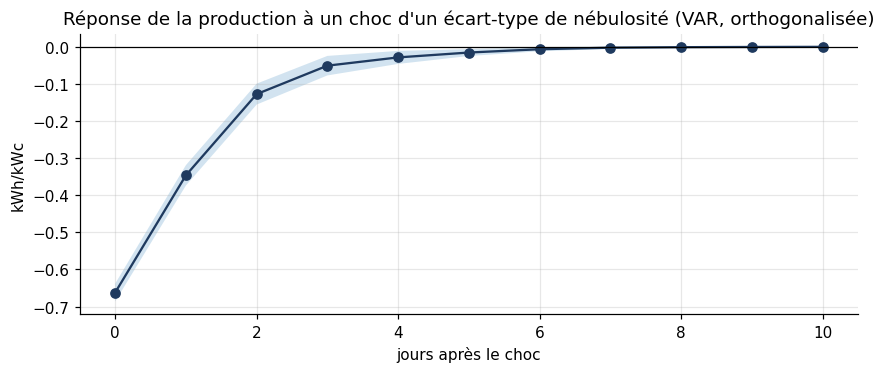

Réponse (kWh/kWc) aux jours 0..6 : [-0.662 -0.346 -0.128 -0.051 -0.029 -0.015 -0.007] | écart-type du choc de nébulosité : 21.7 points
Part de la variance d'erreur de prévision de la production à 7 jours due à la nébulosité : 0.445


In [23]:
# Causalité de Granger dans tous les sens : la physique dit que les nuages réduisent la production,
# mais les deux séries mesurent le même état du ciel ; le test dira si le passé de l'une aide à
# prévoir l'autre au-delà de son propre passé.
lignes_g = []
for i, cause in enumerate(VARS):
    for j, effet in enumerate(VARS):
        if i != j:
            g = var_fit.test_causality(j, [i], kind="f")
            lignes_g.append({"cause": cause, "effet": effet, "F": g.test_statistic, "p": g.pvalue})
granger = pd.DataFrame(lignes_g)
granger.to_csv(RES / "py_granger.csv", index=False)
print(granger.round(4).to_string(index=False))

# L'orthogonalisation (Cholesky) dépend de l'ordre des variables : on place la nébulosité en premier,
# car les nuages agissent sur la production du jour même et non l'inverse. VAR identique, colonnes permutées.
var_irf = VAR(endog_var[:n_train][:, [1, 0, 2]], exog=Xv[:n_train]).fit(P_VAR)
irf = var_irf.irf(10)
rep = irf.orth_irfs[:, 1, 0]          # réponse orthogonalisée de la production à un choc de nébulosité
ic = irf.stderr(orth=True)[:, 1, 0]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(rep, marker="o", color="#1f3a5f")
ax.fill_between(range(len(rep)), rep - 1.96 * ic, rep + 1.96 * ic, alpha=0.2)
ax.axhline(0, color="k", lw=0.8); ax.set_xlabel("jours après le choc"); ax.set_ylabel("kWh/kWc")
ax.set_title("Réponse de la production à un choc d'un écart-type de nébulosité (VAR, orthogonalisée)")
montrer(fig, "11_var_irf")
print("Réponse (kWh/kWc) aux jours 0..6 :", np.round(rep[:7], 3), "| écart-type du choc de nébulosité :",
      round(np.sqrt(var_fit.sigma_u[1, 1]), 1), "points")
print("Part de la variance d'erreur de prévision de la production à 7 jours due à la nébulosité :",
      round(float(var_irf.fevd(7).decomp[1, 6, 0]), 3))

In [24]:
# Extension multi-pays : la météo de l'Espagne aide-t-elle à prévoir la production de Tunis ? Les
# perturbations atlantiques traversent souvent la péninsule Ibérique avant d'atteindre la Tunisie.
# VAR bivariés sur les anomalies (cycle annuel retiré), ordre choisi par le BIC.
def anomalie_site(site, col=CIBLE):
    v = panel[panel["site"] == site].set_index("date")[col].asfreq("D").to_numpy()
    b = np.linalg.lstsq(X4[:n_train], v[:n_train], rcond=None)[0]
    return v - X4 @ b


lignes_x = []
for amont in ("seville", "madrid", "barcelone", "marseille", "tozeur"):
    paire = np.column_stack([anomalie_site(SITE), anomalie_site(amont)])[:n_train]
    p_ = max(VAR(paire).select_order(7).selected_orders["bic"], 1)
    vx = VAR(paire).fit(p_)
    g_a = vx.test_causality(0, [1], kind="f")
    g_b = vx.test_causality(1, [0], kind="f")
    corr0 = np.corrcoef(paire.T)[0, 1]
    corr1 = np.corrcoef(paire[1:, 0], paire[:-1, 1])[0, 1]
    lignes_x.append({"site amont": SITES[amont]["ville"], "ordre VAR": p_, "corr. même jour": corr0,
                     "corr. Tunis(t) / amont(t-1)": corr1, "F (amont -> Tunis)": g_a.test_statistic,
                     "p (amont -> Tunis)": g_a.pvalue, "F (Tunis -> amont)": g_b.test_statistic,
                     "p (Tunis -> amont)": g_b.pvalue})
granger_x = pd.DataFrame(lignes_x)
granger_x.to_csv(RES / "py_granger_multi_sites.csv", index=False)
print(granger_x.round(4).to_string(index=False))

site amont  ordre VAR  corr. même jour  corr. Tunis(t) / amont(t-1)  F (amont -> Tunis)  p (amont -> Tunis)  F (Tunis -> amont)  p (Tunis -> amont)
   Séville          3          -0.0626                       0.0024              9.8209                 0.0              1.4173              0.2356
    Madrid          2          -0.0750                       0.0115             17.6843                 0.0              6.2534              0.0019
 Barcelone          1          -0.0101                       0.1237            108.5236                 0.0              4.8663              0.0274
 Marseille          1          -0.0004                       0.0740             37.0102                 0.0              7.6337              0.0057
    Tozeur          2           0.3485                       0.1924             40.9975                 0.0             21.3605              0.0000


**Lecture.**
- **Ordre :** l'AIC et le BIC choisissent tous deux 3 retards. Le test Portmanteau multivarié rejette de peu la blancheur (p = 0,018), mais chaque équation passe le test de Ljung-Box (p = 0,54 ; 0,26 ; 0,08) et le VAR est stable. Ses résidus ne sont pas gaussiens et présentent un effet ARCH, comme ceux de l'ARIMA.
- **Causalité de Granger :** le passé de la nébulosité aide fortement à prévoir la production (F = 98,8), et le passé de la production aide aussi à prévoir la nébulosité (F = 14,3). La relation est bidirectionnelle parce que les deux séries mesurent, chacune imparfaitement, le même état du ciel. La production de la veille aide à prévoir la température (F = 19,3) : une journée claire réchauffe le sol et l'air, effet physique attendu. La température n'aide que marginalement à prévoir la production (p = 0,034). Rappel : la causalité de Granger mesure la prévisibilité, pas la causalité physique.
- **Réponse impulsionnelle (nébulosité placée en premier) :** un choc d'un écart-type de nébulosité (21,7 points) réduit la production de 0,66 kWh/kWc le jour même, de 0,35 le lendemain et de 0,13 à J+2 ; l'effet disparaît en 4 jours. Les chocs de nébulosité expliquent 44,5 % de la variance d'erreur de prévision de la production à 7 jours.
- **Météo des autres pays :** le même jour, les anomalies de Tunis ne sont pas corrélées à celles de Séville, Madrid, Barcelone ou Marseille (|r| < 0,08). En revanche, l'anomalie de la veille à Barcelone (r = 0,12) et à Marseille (0,07) aide à prévoir Tunis (F = 108,5 et 37,0 ; p < 0,001), alors que l'inverse est beaucoup plus faible ; Séville aide à prévoir Tunis (p < 0,001) sans réciproque (p = 0,24). C'est cohérent avec des perturbations qui traversent le nord-ouest de la Méditerranée avant d'atteindre la Tunisie, mais le test ne prouve pas ce mécanisme et le gain reste modeste (de l'ordre de 1,5 % de variance). Tozeur, à 370 km, est corrélée le jour même (0,35).

In [25]:
# Cointégration : le test n'a de sens que pour des séries intégrées d'ordre 1. On l'applique
# d'abord au VAR de Tunis pour montrer ce qu'il renvoie sur des séries stationnaires.
eg_stat, eg_p, eg_crit = coint(train[CIBLE], train["nebulosite_pct"], trend="c", autolag="AIC")
print(f"Engle-Granger (production, nébulosité) : stat = {eg_stat:.3f}, p = {eg_p:.4f}")
joh = coint_johansen(endog_var[:n_train], det_order=0, k_ar_diff=max(P_VAR - 1, 1))
tab_joh = pd.DataFrame({"H0": [f"r <= {i}" for i in range(len(VARS))], "trace": joh.lr1, "crit. 95 %": joh.cvt[:, 1],
                        "valeur propre max": joh.lr2, "crit. 95 % (vp max)": joh.cvm[:, 1]}).round(3)
print("Johansen (Tunis : production, nébulosité, température) :\n", tab_joh.to_string(index=False))
def rang_johansen(res):
    """Procédure séquentielle de la trace : le rang est le premier r dont l'hypothèse « rang <= r » n'est
    pas rejetée à 5 % (compter les rejets serait faux quand un test intermédiaire rejette)."""
    for r_ in range(len(res.lr1)):
        if res.lr1[r_] <= res.cvt[r_, 1]:
            return r_
    return len(res.lr1)


print("Rang estimé (procédure séquentielle) :", rang_johansen(joh), "sur", len(VARS))

Engle-Granger (production, nébulosité) : stat = -6.278, p = 0.0000
Johansen (Tunis : production, nébulosité, température) :
     H0    trace  crit. 95 %  valeur propre max  crit. 95 % (vp max)
r <= 0 2129.382      29.796           1136.644               21.131
r <= 1  992.738      15.494            930.445               14.264
r <= 2   62.293       3.842             62.293                3.842
Rang estimé (procédure séquentielle) : 3 sur 3


**Un cas réellement non stationnaire : la production solaire nationale mesurée.** Les séries PVGIS
simulent une installation de puissance constante : elles n'ont pas de tendance. La production
nationale mesurée par RTE (France) et REE (Espagne) croît au contraire avec le parc installé. C'est
sur ces deux séries, à la maille mensuelle et en logarithme, que la question de la cointégration se
pose vraiment : les deux parcs partagent-ils une tendance commune de long terme ?

In [26]:
# Séries mensuelles en log, désaisonnalisées par régression sur des indicatrices de mois (la
# saisonnalité est commune et déterministe : elle ne doit pas créer une fausse relation).
rte = pd.read_csv(JEUX / "fr_solaire_national_rte_journalier.csv", index_col="date", parse_dates=True)
ree = pd.read_csv(JEUX / "es_fotovoltaica_ree_journalier.csv", index_col="date", parse_dates=True)
nat = pd.concat({"France": rte["production_gwh"].resample("MS").sum(min_count=25),
                 "Espagne": ree["produccion_gwh"].resample("MS").sum(min_count=25)}, axis=1).dropna()
nat = nat.loc[:"2026-08-01"]
lnat = np.log(nat)
indic = pd.get_dummies(lnat.index.month, drop_first=True).astype(float).to_numpy()
Xd = np.column_stack([np.ones(len(lnat)), indic])
ldes = lnat - Xd[:, 1:] @ np.linalg.lstsq(Xd, lnat.to_numpy(), rcond=None)[0][1:]
print(f"Période commune : {nat.index[0]:%Y-%m} -> {nat.index[-1]:%Y-%m} ({len(nat)} mois)")
lignes_n = []
for c in ldes.columns:
    lignes_n.append(tests_stationnarite(ldes[c], f"log {c} (désaisonnalisé), avec tendance", "ct"))
    lignes_n.append(tests_stationnarite(ldes[c].diff(), f"log {c} - diff. ordre 1"))
tab_stat_nat = pd.DataFrame(lignes_n).set_index("série")
print(tab_stat_nat.to_string())
p_nat = max(VAR(ldes.diff().dropna().to_numpy()).select_order(6).selected_orders["aic"], 1)
eg_n = coint(ldes["France"], ldes["Espagne"], trend="ct", autolag="AIC")
print(f"\nEngle-Granger (avec tendance) : stat = {eg_n[0]:.3f}, p = {eg_n[1]:.4f}")
joh_n = coint_johansen(ldes.to_numpy(), det_order=1, k_ar_diff=p_nat)
tab_joh_n = pd.DataFrame({"H0": ["r = 0", "r <= 1"], "trace": joh_n.lr1, "crit. 95 %": joh_n.cvt[:, 1],
                          "valeur propre max": joh_n.lr2, "crit. 95 % (vp max)": joh_n.cvm[:, 1]}).round(3)
tab_joh_n.to_csv(RES / "py_johansen_national.csv", index=False)
tab_joh.to_csv(RES / "py_johansen.csv", index=False)
RANG_N = rang_johansen(joh_n)
print(f"Johansen (tendance linéaire, {p_nat} retards en différences) :\n", tab_joh_n.to_string(index=False))
print("Rang de cointégration estimé (procédure séquentielle) :", RANG_N)

Période commune : 2014-01 -> 2026-08 (152 mois)
                                             ADF stat   ADF p  ADF retards  KPSS stat  KPSS p                    conclusion à 5 %
série                                                                                                                            
log France (désaisonnalisé), avec tendance     -2.806  0.1948            3      0.296    0.01  non stationnaire (racine unitaire)
log France - diff. ordre 1                    -12.483  0.0000            2      0.143    0.10                        stationnaire
log Espagne (désaisonnalisé), avec tendance    -2.429  0.3642            2      0.331    0.01  non stationnaire (racine unitaire)
log Espagne - diff. ordre 1                   -12.961  0.0000            1      0.243    0.10                        stationnaire

Engle-Granger (avec tendance) : stat = -2.755, p = 0.3818
Johansen (tendance linéaire, 3 retards en différences) :
     H0  trace  crit. 95 %  valeur propre max  crit. 95 

Vecteur de cointégration beta (normalisé sur la France) : [ 1.     -4.6948]
Coefficients d'ajustement alpha [France, Espagne] : [-0.0007 -0.0008] | p-values : [0.0007 0.0014]
Demi-vie de l'écart pour France : 1028.1 mois
Demi-vie de l'écart pour Espagne : 899.8 mois


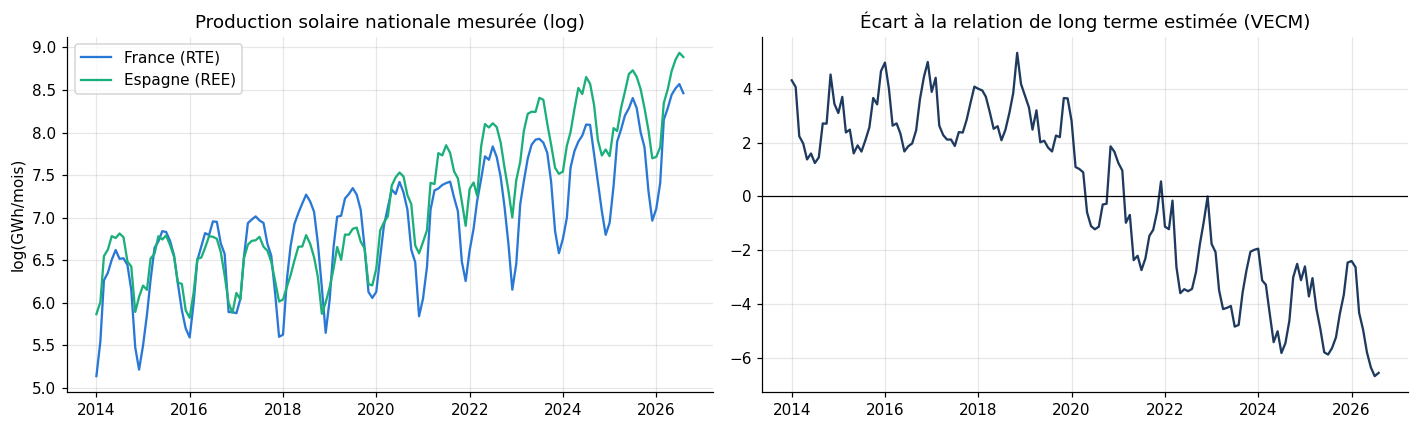

In [27]:
# VECM : estimé si un rang de cointégration est détecté (et, à titre de vérification, avec un rang
# imposé à 1 sinon). Alpha mesure la vitesse de retour vers la relation de long terme.
vecm = VECM(lnat.to_numpy(), k_ar_diff=p_nat, coint_rank=1, deterministic="li", seasons=12).fit()
beta = vecm.beta.ravel()
print("Vecteur de cointégration beta (normalisé sur la France) :", np.round(beta / beta[0], 4))
print("Coefficients d'ajustement alpha [France, Espagne] :", np.round(vecm.alpha.ravel(), 4),
      "| p-values :", np.round(vecm.pvalues_alpha.ravel(), 4))
for k, pays_ in enumerate(("France", "Espagne")):
    a_ = vecm.alpha[k, 0]
    if -2 < a_ < 0:
        print(f"Demi-vie de l'écart pour {pays_} : {np.log(0.5) / np.log(1 + a_):.1f} mois")
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(lnat.index, lnat["France"], label="France (RTE)", color=COULEUR_PAYS["France"])
ax[0].plot(lnat.index, lnat["Espagne"], label="Espagne (REE)", color=COULEUR_PAYS["Espagne"])
ax[0].set_ylabel("log(GWh/mois)"); ax[0].legend(); ax[0].set_title("Production solaire nationale mesurée (log)")
ect = lnat.to_numpy() @ beta
ax[1].plot(lnat.index, ect - ect.mean(), color="#1f3a5f")
ax[1].axhline(0, color="k", lw=0.8); ax[1].set_title("Écart à la relation de long terme estimée (VECM)")
montrer(fig, "12_cointegration_national")

**Lecture : où la cointégration s'applique, et où elle ne s'applique pas.**
- **Tunis : non applicable.** Les trois séries sont stationnaires (section 2.6). Le test de Johansen rejette toutes les hypothèses (trace de 2 129, 993 et 62 pour des seuils de 29,8 ; 15,5 et 3,8) : le rang est plein, ce qui signifie que le système est stationnaire en niveaux. Le test d'Engle-Granger « rejette l'absence de cointégration » (statistique de -6,28), mais c'est trompeur : une combinaison de séries stationnaires est toujours stationnaire. La bonne représentation est le VAR en niveaux.
- **Productions nationales mesurées : séries I(1), non cointégrées.** Sur 2014-2026 (152 mois), le log de la production désaisonnalisée n'est stationnaire ni en France ni en Espagne (ADF avec tendance : p = 0,19 et 0,36 ; le KPSS rejette), alors que ses différences le sont. Les deux séries sont intégrées d'ordre 1 : la question de la cointégration se pose vraiment, et la réponse est non. Engle-Granger donne p = 0,38 ; le test de la trace ne rejette pas « rang = 0 » (15,1 contre 18,4). Le rejet isolé de « rang <= 1 » (5,1 contre 3,8) signale une tendance propre à l'une des séries, pas une relation commune. R conclut de même (trace de 15,3 contre 25,3, avec indicatrices saisonnières).
- **VECM de vérification (rang imposé à 1) :** coefficients d'ajustement de -0,0007 et -0,0008, soit des demi-vies de 900 à 1 000 mois : aucune force de rappel. Les deux parcs suivent des politiques nationales distinctes : la production espagnole a été multipliée par 6,7 entre 2018 et 2025 (de 7,4 à 49,3 TWh), la française par 3,1 (de 10,6 à 32,5 TWh). Un VAR en différences, et non un VECM, serait la représentation adaptée.

### 3.3 Volatilité conditionnelle : ARCH et GARCH

In [28]:
# Le test ARCH-LM de la section 3.1 rejette l'homoscédasticité des résidus : leur variance dépend du
# passé (et de la saison). On la modélise par un GARCH estimé sur les écarts à la tendance et au
# cycle annuel, c'est-à-dire les erreurs de prévision à un jour de l'ARIMA-Fourier manuel.
from arch import arch_model

# Le filtre de l'ARIMA est prolongé sur toute la période, paramètres figés : sur le test, les
# résidus sont de vraies erreurs de prévision à un jour, hors échantillon.
X_man = fourier(K_F)
complet_man = m_man.apply(y_all, exog=X_man)
e_tout = np.asarray(complet_man.resid)
e_train = e_tout[BRULAGE:n_train]
idx_e = df.index[BRULAGE:n_train]
lm, lm_p, _, _ = het_arch(e_train, nlags=7)
print(f"ARCH-LM(7) sur les résidus de l'ARIMA-Fourier : LM = {lm:.1f}, p = {lm_p:.2e}")
print("ACF des résidus au carré, retards 1 à 7 :", np.round(sm.tsa.acf(e_train ** 2, nlags=7)[1:], 3))

candidats = {"ARCH(1) normale": dict(p=1, q=0, dist="normal"), "GARCH(1,1) normale": dict(p=1, q=1, dist="normal"),
             "GARCH(1,1) Student": dict(p=1, q=1, dist="t"), "GARCH(1,1) Student asym.": dict(p=1, q=1, dist="skewt"),
             "GARCH(2,1) Student asym.": dict(p=2, q=1, dist="skewt"),
             "GJR-GARCH(1,1) Student asym.": dict(p=1, o=1, q=1, dist="skewt"),
             "EGARCH(1,1) Student asym.": dict(p=1, o=1, q=1, vol="EGARCH", dist="skewt")}


def ajuster_garch(e, kw):
    kw = dict(kw)
    vol = kw.pop("vol", "GARCH")
    return arch_model(e, mean="Zero", vol=vol, **kw).fit(disp="off")


ajust_g = {nom: ajuster_garch(e_train, kw) for nom, kw in candidats.items()}

# Variante « saisonnière » : la variance des erreurs suit d'abord le calendrier (hiver pluvieux,
# été sec). On la retire par une régression de log(e²) sur des termes de Fourier, puis on estime un
# GARCH sur les résidus réduits. La vraisemblance est ramenée à l'échelle de e (jacobien) pour que
# l'AIC soit comparable à celui des autres modèles.
Xs = sm.add_constant(fourier(2))
b_s = np.linalg.lstsq(Xs[BRULAGE:n_train], np.log(e_train ** 2 + 1e-4), rcond=None)[0]
# exp(ajusté / 2) sous-estime l'écart-type (E[log chi²(1)] < 0) : on renormalise pour que les résidus
# réduits aient une variance unité sur l'apprentissage.
sig_saison_tout = np.exp(0.5 * (Xs @ b_s))
sig_saison_tout *= np.sqrt(np.mean((e_train / sig_saison_tout[BRULAGE:n_train]) ** 2))
z_saison = e_train / sig_saison_tout[BRULAGE:n_train]
g_sais = ajuster_garch(z_saison, dict(p=1, q=1, dist="skewt"))
ll_sais = g_sais.loglikelihood - np.sum(np.log(sig_saison_tout[BRULAGE:n_train]))
k_sais = len(g_sais.params) + len(b_s)


def ligne_g(g, ll=None, k=None, z=None):
    ll = g.loglikelihood if ll is None else ll
    k = len(g.params) if k is None else k
    z = np.asarray(g.std_resid) if z is None else z
    return {"log-vraisemblance": ll, "AIC": -2 * ll + 2 * k, "BIC": -2 * ll + k * np.log(len(z)), "nb paramètres": k,
            "LB(10) sur z² p": acorr_ljungbox(z ** 2, lags=[10])["lb_pvalue"].iloc[0],
            "ARCH-LM(7) sur z p": het_arch(z, nlags=7)[1], "kurtosis de z": stats.kurtosis(z, fisher=False)}


tab_g = pd.DataFrame({nom: ligne_g(g) for nom, g in ajust_g.items()}).T
tab_g.loc["Variance saisonnière + GARCH(1,1) Student asym."] = ligne_g(
    g_sais, ll_sais, k_sais, np.asarray(g_sais.std_resid))
tab_g.to_csv(RES / "py_garch_comparaison.csv")
print(tab_g.round(4).to_string())

ARCH-LM(7) sur les résidus de l'ARIMA-Fourier : LM = 235.0, p = 4.33e-47
ACF des résidus au carré, retards 1 à 7 : [0.141 0.106 0.094 0.071 0.074 0.064 0.048]


                                                 log-vraisemblance         AIC         BIC  nb paramètres  LB(10) sur z² p  ARCH-LM(7) sur z p  kurtosis de z
ARCH(1) normale                                         -9377.5567  18759.1134  18772.5903            2.0           0.0000              0.0000         3.8711
GARCH(1,1) normale                                      -9084.8480  18175.6961  18195.9113            3.0           0.0702              0.0316         5.0401
GARCH(1,1) Student                                      -8922.2168  17852.4337  17879.3873            4.0           0.0192              0.0119         6.1925
GARCH(1,1) Student asym.                                -8212.6173  16435.2347  16468.9267            5.0           0.0115              0.0066         6.3502
GARCH(2,1) Student asym.                                -8212.6173  16437.2347  16477.6652            6.0           0.0115              0.0066         6.3502
GJR-GARCH(1,1) Student asym.                        

In [29]:
# Diagnostic : si la volatilité est bien modélisée, les résidus standardisés (résidu / écart-type
# conditionnel) ne doivent plus présenter d'effet ARCH. On examine le GARCH(1,1) de référence, puis on
# retient le modèle de plus petit BIC parmi ceux qui passent le test ARCH-LM à 5 %.
g11 = ajust_g["GARCH(1,1) Student asym."]
print(g11.summary().tables[1], "\n", g11.summary().tables[2])
persist = g11.params["alpha[1]"] + g11.params["beta[1]"]
print(f"GARCH(1,1) : persistance alpha + beta = {persist:.3f} ; demi-vie d'un choc de volatilité = "
      f"{np.log(0.5) / np.log(persist):.1f} jours")
valides = tab_g[tab_g["ARCH-LM(7) sur z p"] > 0.05]
NOM_G = (valides if len(valides) else tab_g)["BIC"].idxmin()
print(f"\nModèles qui passent le test ARCH-LM à 5 % : {list(valides.index)}")
print(f"Modèle de volatilité retenu : {NOM_G}")
SAISONNIER = NOM_G.startswith("Variance saisonnière")
g_ret = g_sais if SAISONNIER else ajust_g[NOM_G]
if SAISONNIER:
    print(g_sais.summary().tables[1])
    print("Coefficients de la variance saisonnière (log e² ~ Fourier K = 2) :", np.round(b_s, 3))
z = np.asarray(g_ret.std_resid)
z11 = np.asarray(g11.std_resid)


def diag_vol(v):
    return [acorr_ljungbox(v, lags=[10])["lb_pvalue"].iloc[0], acorr_ljungbox(v ** 2, lags=[10])["lb_pvalue"].iloc[0],
            het_arch(v, nlags=7)[1], stats.skew(v), stats.kurtosis(v, fisher=False)]


diag_g = pd.DataFrame({"résidus bruts": diag_vol(e_train), "standardisés GARCH(1,1)": diag_vol(z11),
                       f"standardisés {NOM_G}": diag_vol(z)},
                      index=["Ljung-Box(10) p", "Ljung-Box(10) sur les carrés p", "ARCH-LM(7) p", "skewness", "kurtosis"])
diag_g.to_csv(RES / "py_garch_diagnostic.csv")
print(diag_g.round(4).to_string())

                              Volatility Model                              
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
omega      9.0864e-03  1.806e-03      5.032  4.848e-07 [5.547e-03,1.263e-02]
alpha[1]       0.1370  9.108e-03     15.040  4.037e-51     [  0.119,  0.155]
beta[1]        0.8630  8.994e-03     95.958      0.000     [  0.845,  0.881]
                               Distribution                              
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
eta            7.6599      0.641     11.955  6.093e-33 [  6.404,  8.916]
lambda        -0.5882  1.167e-02    -50.426      0.000 [ -0.611, -0.565]
GARCH(1,1) : persistance alpha + beta = 1.000 ; demi-vie d'un choc de volatilité = 3900340953.5 jours

Modèles qui passent le test ARCH-LM à 5 % : ['Variance saisonnière + 

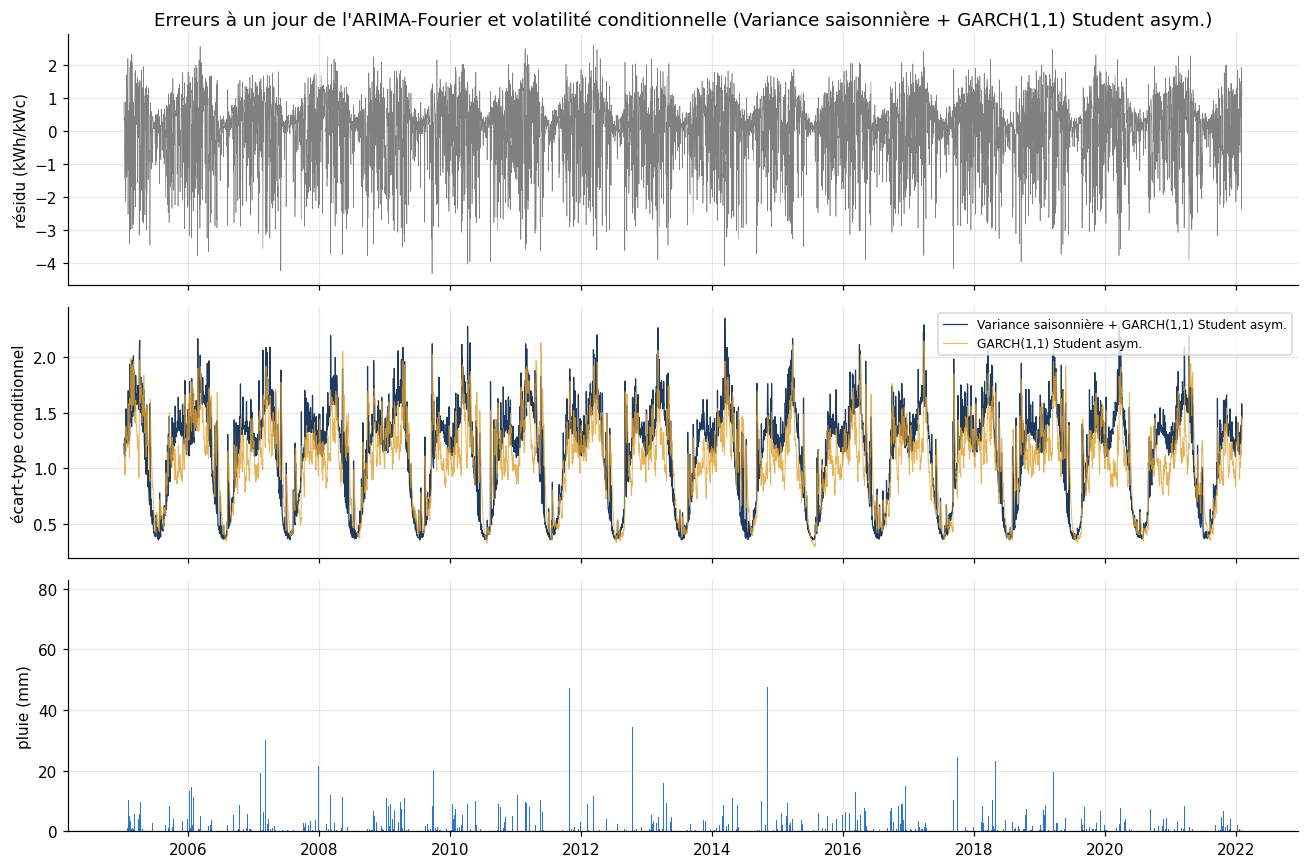

Volatilité moyenne par mois : {1: 1.266, 2: 1.448, 3: 1.684, 4: 1.538, 5: 1.045, 6: 0.617, 7: 0.416, 8: 0.544, 9: 0.937, 10: 1.291, 11: 1.416, 12: 1.294}
Les 10 jours de plus forte volatilité conditionnelle et la météo de la veille :
             volatilité  pluie (mm) J-1  nébulosité J-1 (%)  erreur J-1
date                                                                  
2014-03-14       2.349            14.1                87.0       -4.08
2017-03-29       2.290             0.0                69.0       -3.76
2010-04-09       2.275             5.7                75.0       -4.01
2020-03-22       2.272             4.0                93.0       -3.76
2013-03-06       2.264             1.3               100.0       -3.89
2017-03-26       2.223             0.0                74.0       -3.66
2012-03-31       2.200             1.0                95.0       -3.59
2008-03-06       2.193            11.9                97.0       -3.72
2021-04-16       2.189             9.9                9

In [30]:
# Volatilité conditionnelle dans le temps, mise en relation avec la saison et avec les épisodes de
# pluie identifiés dans les données (et non avec des événements supposés).
vol = pd.Series(np.asarray(g_ret.conditional_volatility) * (sig_saison_tout[BRULAGE:n_train] if SAISONNIER else 1),
                index=idx_e)
vol11 = pd.Series(np.asarray(g11.conditional_volatility), index=idx_e)
fig, ax = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
ax[0].plot(idx_e, e_train, lw=0.4, color="grey"); ax[0].set_ylabel("résidu (kWh/kWc)")
ax[0].set_title(f"Erreurs à un jour de l'ARIMA-Fourier et volatilité conditionnelle ({NOM_G})")
ax[1].plot(vol, color="#1f3a5f", lw=0.8, label=NOM_G)
ax[1].plot(vol11, color="#e0a030", lw=0.6, alpha=0.8, label="GARCH(1,1) Student asym.")
ax[1].set_ylabel("écart-type conditionnel"); ax[1].legend(fontsize=8)
ax[2].bar(idx_e, train["precipitation_mm"].iloc[BRULAGE:], width=1, color="#2a78d6")
ax[2].set_ylabel("pluie (mm)")
montrer(fig, "13_garch_volatilite")
print("Volatilité moyenne par mois :", vol.groupby(vol.index.month).mean().round(3).to_dict())
top = vol.sort_values(ascending=False).head(10)
evts = pd.DataFrame({"volatilité": top.round(3), "pluie (mm) J-1": train["precipitation_mm"].shift(1).reindex(top.index).round(1),
                     "nébulosité J-1 (%)": train["nebulosite_pct"].shift(1).reindex(top.index).round(0),
                     "erreur J-1": pd.Series(e_tout, index=df.index).shift(1).reindex(top.index).round(2)})
print("Les 10 jours de plus forte volatilité conditionnelle et la météo de la veille :\n", evts.to_string())
pluie_v = train["precipitation_mm"].shift(1).iloc[BRULAGE:] >= 5
print("Volatilité moyenne : lendemain de pluie (>= 5 mm) =", round(vol[pluie_v.to_numpy()].mean(), 3),
      "| autres jours =", round(vol[~pluie_v.to_numpy()].mean(), 3))

In [31]:
# Utilité pratique : le GARCH ne change pas la prévision ponctuelle mais adapte la largeur de
# l'intervalle. On compare sur le test, par saison, le taux de couverture d'un intervalle à 95 % à un
# jour : variance constante, GARCH(1,1) et modèle retenu.
a_tout = e_tout[BRULAGE:]
n0 = n_train - BRULAGE


def sigma_un_jour(nom):
    """Écart-type prévu à un jour pour chaque jour du test, paramètres estimés sur l'apprentissage."""
    if nom.startswith("Variance saisonnière"):
        zz = a_tout / sig_saison_tout[BRULAGE:]
        g_ = arch_model(zz, mean="Zero", vol="GARCH", p=1, q=1, dist="skewt").fit(last_obs=n0, disp="off")
        v_ = g_.forecast(horizon=1, start=n0 - 1, reindex=False).variance.to_numpy().ravel()[:-1]
        return np.sqrt(v_) * sig_saison_tout[n_train:], g_
    kw = dict(candidats[nom]); vol_ = kw.pop("vol", "GARCH")
    g_ = arch_model(a_tout, mean="Zero", vol=vol_, **kw).fit(last_obs=n0, disp="off")
    v_ = g_.forecast(horizon=1, start=n0 - 1, reindex=False).variance.to_numpy().ravel()[:-1]
    return np.sqrt(v_), g_


e_test = e_tout[n_train:]
mois_test = test.index.month
sais_test = np.where(np.isin(mois_test, [11, 12, 1, 2, 3]), "novembre-mars", "avril-octobre")
lignes_ic = []
for nom in ("variance constante", "GARCH(1,1) Student asym.", NOM_G):
    if nom == "variance constante":
        sig, q_bas, q_haut = np.full(len(e_test), e_train.std()), -1.96, 1.96
    else:
        sig, g_ = sigma_un_jour(nom)
        k_d = g_.model.distribution.num_params           # paramètres de forme de la loi (0, 1 ou 2)
        q_bas, q_haut = g_.model.distribution.ppf([0.025, 0.975], g_.params[-k_d:] if k_d else None)
    dedans = (e_test >= q_bas * sig) & (e_test <= q_haut * sig)
    ligne = {"modèle": nom, "couverture IC 95 % (%)": 100 * dedans.mean(),
             "demi-largeur moyenne": float(np.mean((q_haut - q_bas) / 2 * sig))}
    for s_ in ("novembre-mars", "avril-octobre"):
        ligne[f"couverture {s_} (%)"] = 100 * dedans[sais_test == s_].mean()
    lignes_ic.append(ligne)
ic_garch = pd.DataFrame(lignes_ic).drop_duplicates("modèle").set_index("modèle")
ic_garch.to_csv(RES / "py_garch_intervalles.csv")
print(ic_garch.round(2).to_string())

                                                 couverture IC 95 % (%)  demi-largeur moyenne  couverture novembre-mars (%)  couverture avril-octobre (%)
modèle                                                                                                                                                   
variance constante                                                95.10                  2.16                         92.86                         96.50
GARCH(1,1) Student asym.                                          94.38                  1.88                         92.48                         95.56
Variance saisonnière + GARCH(1,1) Student asym.                   96.97                  2.03                         97.37                         96.73


**Lecture.**
- **Effet ARCH confirmé :** LM = 235 (p de l'ordre de 1e-47) ; l'ACF des résidus au carré décroît lentement (0,14 ; 0,11 ; 0,09...).
- **Loi des erreurs :** la loi de Student asymétrique est très nettement préférée à la loi normale (BIC de 16 469 contre 18 196 pour le GARCH(1,1)) ; son paramètre d'asymétrie (-0,59) confirme que les erreurs négatives sont les plus fortes.
- **Le GARCH(1,1) ne suffit pas, et sa persistance est un artefact.** Il estime alpha + beta = 1,000 : un GARCH intégré, comme si chaque choc de volatilité durait indéfiniment. En réalité, la variance suit les saisons, et le GARCH prend un changement déterministe pour des chocs persistants. Ses résidus standardisés échouent encore au test ARCH-LM (p = 0,007), comme ceux des ordres voisins, du GJR-GARCH et de l'EGARCH (p ≤ 0,03), malgré de meilleurs AIC pour ces deux derniers.
- **Modèle retenu : variance saisonnière + GARCH(1,1) Student asymétrique.** On retire d'abord la composante saisonnière de la variance (régression de log e² sur deux harmoniques), puis on modélise le reste par un GARCH(1,1). C'est le seul candidat qui passe le diagnostic (ARCH-LM p = 0,39 ; Ljung-Box sur les carrés p = 0,12), et il a le meilleur AIC et le meilleur BIC (15 632, vraisemblance ramenée à l'échelle des résidus). Sa persistance tombe à alpha + beta = 0,53 : une fois la saison retirée, un choc de volatilité s'éteint en un à deux jours. Ses résidus standardisés gardent des queues épaisses (kurtosis de 7,7), que la loi de Student prend en charge.
- **Lien avec les événements :** la volatilité est quatre fois plus forte en mars (1,68 kWh/kWc) qu'en juillet (0,42). Les dix jours de plus forte volatilité tombent tous en mars ou en avril, au lendemain d'une erreur de -3,6 à -4,1 kWh/kWc sous un ciel couvert (69 à 100 %), souvent pluvieux (14 mm la veille du 14 mars 2014). La volatilité moyenne vaut 1,49 au lendemain d'une pluie d'au moins 5 mm, contre 1,09 les autres jours.
- **Utilité pratique :** à variance constante, l'intervalle à 95 % à un jour couvre 95,1 % des jours du test, mais seulement 92,9 % de novembre à mars et 96,5 % d'avril à octobre : trop étroit l'hiver, trop large l'été. Le modèle retenu couvre 97,4 % et 96,7 % : la couverture devient homogène entre les saisons, avec un intervalle en moyenne plus étroit (demi-largeur de 2,03 contre 2,16 kWh/kWc), au prix d'un léger excès de prudence. Le GARCH(1,1) seul ne corrige pas le défaut hivernal (92,5 %).

## 4. Modélisation avancée
### 4.1 Réseaux de neurones récurrents : LSTM et GRU

**Mise en forme.** Chaque exemple est une fenêtre glissante de `L` jours passés (production, nébulosité,
température, humidité, pluie, aérosols, position dans l'année), à partir de laquelle le réseau prévoit
les 7 jours suivants en une passe (prévision directe multi-horizon). Les variables sont centrées-réduites
avec les statistiques **de l'apprentissage seulement**.

**Cible.** La production est d'abord ramenée à son écart à la normale saisonnière : z = (y - normale du
jour) / écart-type du jour, normales calculées sur l'apprentissage et lissées sur 31 jours. Le réseau
prévoit z ; la prévision vaut normale + z x écart-type. Il part donc de la climatologie et n'apprend
que l'écart, ce qui convient à une série dont la saison explique l'essentiel de la variance.

**Deux jeux d'information**, pour une comparaison équitable avec les modèles classiques :
- *ex ante* : du futur, le réseau ne connaît que la date (comme l'ARIMA-Fourier et le VAR) ;
- *ex post* : il reçoit aussi la météo observée des 7 jours à prévoir (comme le SARIMAX météo).

In [32]:
# Préparation des tenseurs. La graine et les algorithmes déterministes de PyTorch rendent
# l'entraînement reproductible sur une même machine.
import torch
import torch.nn as nn
from sklearn.model_selection import TimeSeriesSplit

torch.manual_seed(SEED)
torch.set_num_threads(4)
torch.use_deterministic_algorithms(True)


def normales(v, index, fin):
    """Moyenne et écart-type par jour de l'année, calculés sur [0, fin) et lissés sur 31 jours."""
    base = pd.Series(np.asarray(v[:fin], dtype=float), index=index[:fin])
    jour = np.minimum(base.index.dayofyear, 365)
    m = base.groupby(jour).mean().reindex(range(1, 366)).interpolate(limit_direction="both").to_numpy()
    s = base.groupby(jour).std().reindex(range(1, 366)).interpolate(limit_direction="both").to_numpy()
    lisser = lambda a: pd.Series(np.tile(a, 3)).rolling(31, center=True).mean().to_numpy()[365:730]
    j_all = np.minimum(index.dayofyear, 365) - 1
    return lisser(m)[j_all], lisser(s)[j_all]


def normer(v, fin=n_train):
    v = np.asarray(v, dtype=float)
    return (v - np.nanmean(v[:fin])) / np.nanstd(v[:fin])


CLIM_M, CLIM_S = normales(y_all, df.index, n_train)
z_all = (y_all - CLIM_M) / CLIM_S
doy = np.column_stack([df["jds_sin"].to_numpy(), df["jds_cos"].to_numpy()])
meteo_rnn = np.column_stack([normer(df["nebulosite_pct"].ffill()), normer(df["t2m_moy_c"]),
                             normer(df["humidite_pct"].ffill()), normer(np.log1p(df["precipitation_mm"].ffill())),
                             normer(df["aerosols_aod"].ffill()), normer(df["amplitude_thermique_c"])])
SEQ = np.column_stack([z_all, meteo_rnn, doy])        # ce que le réseau voit du passé
FUT = {"ex ante": doy, "ex post": np.column_stack([doy, meteo_rnn])}   # ce qu'il sait du futur


def fenetres(origines_, L, info, seq=SEQ, cible=None, fut=FUT, z=z_all):
    """Construit (passé, futur connu, cible) pour une liste de jours d'origine."""
    xs = np.stack([seq[t - L + 1:t + 1] for t in origines_])
    xf = np.stack([fut[info][t + 1:t + 1 + H].ravel() for t in origines_])
    yd = np.stack([z[t + 1:t + 1 + H] for t in origines_]) if cible is None else np.stack([cible[t] for t in origines_])
    return [torch.tensor(a, dtype=torch.float32) for a in (xs, xf, yd)]


class Reseau(nn.Module):
    """Cellule récurrente (LSTM ou GRU) suivie d'une tête dense qui reçoit aussi le futur connu."""

    def __init__(self, cellule, n_seq, n_fut, cache=32, couches=1, dropout=0.1):
        super().__init__()
        rnn = {"LSTM": nn.LSTM, "GRU": nn.GRU}[cellule]
        self.rnn = rnn(n_seq, cache, num_layers=couches, batch_first=True, dropout=dropout if couches > 1 else 0.0)
        self.tete = nn.Sequential(nn.Dropout(dropout), nn.Linear(cache + n_fut, 64), nn.ReLU(), nn.Linear(64, H))

    def forward(self, xs, xf):
        sortie, _ = self.rnn(xs)
        return self.tete(torch.cat([sortie[:, -1], xf], dim=1))


def entrainer(cellule, donnees_app, donnees_val, cache=32, couches=1, dropout=0.1, graine=SEED,
              epoques=80, patience=10, lr=2e-3, lot=128):
    """Entraîne avec arrêt anticipé sur la validation ; renvoie le meilleur modèle et l'historique."""
    torch.manual_seed(graine)
    xs, xf, yd = donnees_app
    vxs, vxf, vyd = donnees_val
    net = Reseau(cellule, xs.shape[2], xf.shape[1], cache, couches, dropout)
    opt = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=1e-5)
    perte = nn.MSELoss()
    gen = torch.Generator().manual_seed(graine)
    histo, meilleur, etat, attente = [], np.inf, None, 0
    for ep in range(epoques):
        net.train()
        perm = torch.randperm(len(xs), generator=gen)
        tot = 0.0
        for i in range(0, len(xs), lot):
            idx = perm[i:i + lot]
            opt.zero_grad()
            l = perte(net(xs[idx], xf[idx]), yd[idx])
            l.backward()
            nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step()
            tot += l.item() * len(idx)
        net.eval()
        with torch.no_grad():
            lv = perte(net(vxs, vxf), vyd).item()
        histo.append((tot / len(xs), lv))
        if lv < meilleur - 1e-5:
            meilleur, attente = lv, 0
            etat = {k: v.clone() for k, v in net.state_dict().items()}
        else:
            attente += 1
            if attente >= patience:
                break
    net.load_state_dict(etat)
    net.eval()
    return net, np.array(histo)


def prevoir_kwh(net, donnees, origines_, clim_m=CLIM_M, clim_s=CLIM_S):
    """Prévision en kWh/kWc : normale saisonnière + écart prévu x écart-type saisonnier (bornée à 0)."""
    xs, xf, _ = donnees
    with torch.no_grad():
        zc = net(xs, xf).numpy()
    m = np.stack([clim_m[t + 1:t + 1 + H] for t in origines_])
    s_ = np.stack([clim_s[t + 1:t + 1 + H] for t in origines_])
    return np.clip(m + zc * s_, 0, None)


def rmse_kwh(P, origines_):
    vrai = np.stack([y_all[t + 1:t + 1 + H] for t in origines_])
    return float(np.sqrt(np.mean((vrai - P) ** 2)))

In [33]:
# Validation croisée temporelle (walk-forward, fenêtre d'apprentissage croissante) pour choisir la
# taille de fenêtre et la taille de l'état caché. Jamais de k-fold classique : chaque pli s'entraîne sur
# le passé et se valide sur le futur immédiat, avec un écart de H jours entre les deux.
L_MAX = 28
orig_app = np.arange(L_MAX - 1, n_train - H)        # origines dont les 7 cibles restent dans l'apprentissage
GRILLE = [(L, c) for L in (14, 28) for c in (32, 64)]
t0 = time.time()
lignes_cv = []
for cellule in ("LSTM", "GRU"):
    for L, cache in GRILLE:
        scores = []
        for pli, (i_app, i_val) in enumerate(TimeSeriesSplit(n_splits=3, gap=H).split(orig_app)):
            o_app, o_val = orig_app[i_app], orig_app[i_val]
            coupe = int(len(o_app) * 0.9)             # 10 % les plus récents pour l'arrêt anticipé
            net, _ = entrainer(cellule, fenetres(o_app[:coupe - H], L, "ex ante"),
                               fenetres(o_app[coupe:], L, "ex ante"), cache=cache)
            scores.append(rmse_kwh(prevoir_kwh(net, fenetres(o_val, L, "ex ante"), o_val), o_val))
        lignes_cv.append({"cellule": cellule, "fenêtre L": L, "état caché": cache, "RMSE pli 1": scores[0],
                          "RMSE pli 2": scores[1], "RMSE pli 3": scores[2], "RMSE moyen": np.mean(scores),
                          "écart-type": np.std(scores)})
tab_cv = pd.DataFrame(lignes_cv)
tab_cv.to_csv(RES / "py_validation_croisee_rnn.csv", index=False)
print(tab_cv.round(3).to_string(index=False))
print(f"Durée de la validation croisée : {time.time() - t0:.0f} s")
# Références sur les mêmes plis : climatologie (normale du jour) et persistance (valeur de la veille).
plis = list(TimeSeriesSplit(n_splits=3, gap=H).split(orig_app))
clim_cv = [rmse_kwh(np.stack([CLIM_M[t + 1:t + 1 + H] for t in orig_app[i_val]]), orig_app[i_val]) for _, i_val in plis]
pers_cv = [rmse_kwh(np.stack([np.repeat(y_all[t], H) for t in orig_app[i_val]]), orig_app[i_val]) for _, i_val in plis]
print("RMSE de la climatologie sur les 3 plis :", np.round(clim_cv, 3), "| de la persistance :", np.round(pers_cv, 3))
CONFIG = {c: tuple(int(v) for v in tab_cv[tab_cv["cellule"] == c].sort_values("RMSE moyen")
                   .iloc[0][["fenêtre L", "état caché"]]) for c in ("LSTM", "GRU")}
print("Configuration retenue (fenêtre, état caché) :", CONFIG)

cellule  fenêtre L  état caché  RMSE pli 1  RMSE pli 2  RMSE pli 3  RMSE moyen  écart-type
   LSTM         14          32       1.126       1.083       1.119       1.110       0.019
   LSTM         14          64       1.126       1.081       1.120       1.109       0.020
   LSTM         28          32       1.127       1.083       1.119       1.110       0.019
   LSTM         28          64       1.126       1.081       1.120       1.109       0.020
    GRU         14          32       1.122       1.082       1.121       1.109       0.018
    GRU         14          64       1.121       1.081       1.118       1.107       0.018
    GRU         28          32       1.122       1.083       1.120       1.108       0.018
    GRU         28          64       1.121       1.081       1.119       1.107       0.018
Durée de la validation croisée : 59 s
RMSE de la climatologie sur les 3 plis : [1.129 1.087 1.13 ] | de la persistance : [1.556 1.507 1.532]
Configuration retenue (fenêtre, état cac

**Lecture de la validation croisée et justification des hyperparamètres.**
- **Les réseaux apprennent peu :** sur les trois plis, leur RMSE (1,081 à 1,127 kWh/kWc) est à peine inférieur à celui de la climatologie (1,087 à 1,130) et très inférieur à celui de la persistance (1,51 à 1,56). Sans connaître la météo à venir, il n'y a presque rien à apprendre au-delà du cycle annuel.
- **Hyperparamètres non identifiables :** les huit configurations sont à moins de 0,003 kWh/kWc les unes des autres, alors que la dispersion entre plis atteint 0,02. On retient la plus petite erreur moyenne (fenêtre de 14 jours, 64 unités) sans prétendre qu'elle soit meilleure.
- **Choix justifiés par la série :** une fenêtre de 14 jours suffit, la météo ne persistant qu'un ou deux jours (AR(1) de 0,26) ; une seule couche et un dropout de 0,1, car avec environ 5 600 fenêtres un réseau profond aurait bien plus de paramètres que d'exemples ; l'arrêt anticipé (patience de 10 époques) est la principale régularisation.

RMSE sur le test (kWh/kWc) selon la graine :
 graine              42      43      44  moyenne  écart-type
modèle                                                     
GRU (ex ante)   1.0820  1.0838  1.0817   1.0825      0.0012
GRU (ex post)   0.7135  0.6918  0.6880   0.6978      0.0137
LSTM (ex ante)  1.0823  1.0834  1.0839   1.0832      0.0008
LSTM (ex post)  0.6990  0.6952  0.6889   0.6944      0.0051
Époques parcourues / époque retenue (graine 42) : {'LSTM (ex ante)': '13 / 3', 'LSTM (ex post)': '23 / 13', 'GRU (ex ante)': '17 / 7', 'GRU (ex post)': '29 / 19'}


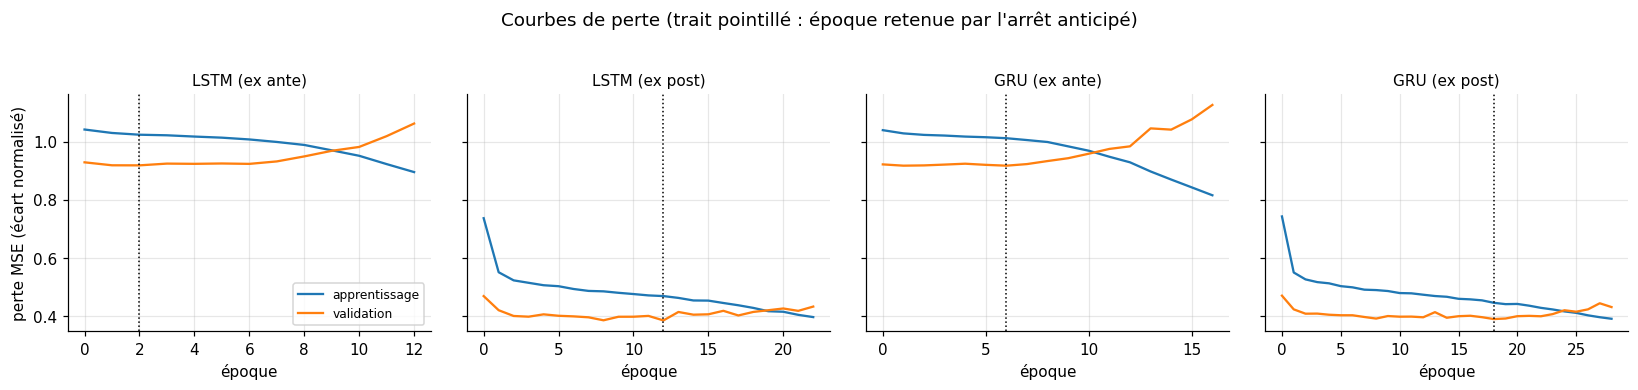

In [34]:
# Entraînement final sur tout l'apprentissage (les 10 % les plus récents servent à l'arrêt anticipé),
# pour les deux cellules et les deux jeux d'information. Trois graines par modèle : on mesure la
# sensibilité à l'initialisation au lieu de la cacher.
origines = np.arange(n_train - 1, n - H)             # origines du test (une par jour)
coupe = int(len(orig_app) * 0.9)
reseaux, histos, prev_rnn, sens = {}, {}, {}, []
for cellule in ("LSTM", "GRU"):
    L, cache = CONFIG[cellule]
    for info in ("ex ante", "ex post"):
        nom = f"{cellule} ({info})"
        t0 = time.time()
        for graine in (SEED, SEED + 1, SEED + 2):
            net, histo = entrainer(cellule, fenetres(orig_app[:coupe - H], L, info),
                                   fenetres(orig_app[coupe:], L, info), cache=cache, graine=graine)
            P = prevoir_kwh(net, fenetres(origines, L, info), origines)
            sens.append({"modèle": nom, "graine": graine, "époques": len(histo),
                         "époque retenue": int(np.argmin(histo[:, 1])) + 1, "RMSE test": rmse_kwh(P, origines)})
            if graine == SEED:                        # le modèle de référence est celui de la graine 42
                reseaux[nom], histos[nom], prev_rnn[nom] = net, histo, P
                duree[nom] = time.time() - t0
        nb_param[nom] = sum(p.numel() for p in net.parameters())
tab_sens = pd.DataFrame(sens).pivot(index="modèle", columns="graine", values="RMSE test")
tab_sens["moyenne"], tab_sens["écart-type"] = tab_sens.mean(axis=1), tab_sens.iloc[:, :3].std(axis=1)
tab_sens.to_csv(RES / "py_rnn_sensibilite_graine.csv")
print("RMSE sur le test (kWh/kWc) selon la graine :\n", tab_sens.round(4).to_string())
print("Époques parcourues / époque retenue (graine 42) :",
      {s["modèle"]: f"{s['époques']} / {s['époque retenue']}" for s in sens if s["graine"] == SEED})

fig, ax = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
for a, (nom, h) in zip(ax, histos.items()):
    a.plot(h[:, 0], label="apprentissage"); a.plot(h[:, 1], label="validation")
    a.axvline(int(np.argmin(h[:, 1])), color="k", ls=":", lw=1)
    a.set_title(nom, fontsize=10); a.set_xlabel("époque")
ax[0].set_ylabel("perte MSE (écart normalisé)"); ax[0].legend(fontsize=8)
fig.suptitle("Courbes de perte (trait pointillé : époque retenue par l'arrêt anticipé)", y=1.03)
montrer(fig, "14_courbes_perte")

**Lecture.**
- **Courbes de perte, ex ante :** la perte de validation reste plate (environ 0,92 en écart normalisé) dès les premières époques, puis remonte pendant que la perte d'apprentissage baisse : le réseau ne trouve pas de signal généralisable et se met à mémoriser l'apprentissage. L'arrêt anticipé retient une époque très précoce (la 3e pour le LSTM, la 7e pour le GRU) : le réseau prévoit alors presque la normale saisonnière, corrigée à un ou deux jours.
- **Courbes de perte, ex post :** les deux courbes baissent ensemble jusqu'à environ 0,40, deux fois plus bas : avec la météo des jours à prévoir, il y a de l'information à apprendre (époque retenue : la 13e pour le LSTM, la 19e pour le GRU).
- **Sensibilité à la graine :** l'écart-type du RMSE entre trois initialisations vaut 0,001 kWh/kWc ex ante et 0,005 à 0,014 ex post. C'est l'étalon pour juger les écarts entre réseaux.
- **LSTM ou GRU :** équivalents (1,0832 contre 1,0825 ex ante, 0,694 contre 0,698 ex post, en moyenne sur trois graines) ; le GRU a 20 % de paramètres en moins.

### 4.2 Approche hybride : ARIMA-Fourier + LSTM sur les erreurs

In [35]:
# Principe : l'ARIMA-Fourier capte la structure linéaire (cycle annuel, persistance de la météo). Un
# LSTM apprend ensuite à prévoir ses erreurs à 7 jours à partir du passé récent, notamment des
# variables météo que l'ARIMA ignore (nébulosité, humidité, aérosols). Tout reste ex ante.
#
# Les prévisions de l'ARIMA depuis chaque origine sont calculées en une fois à partir des états filtrés
# du filtre de Kalman : prévoir h pas depuis t revient à appliquer h fois la matrice de transition à
# l'état filtré en t. C'est exactement ce que fait `get_prediction`, en beaucoup plus rapide (vérifié).
def prev_arima_toutes(res_complet, h_max=H):
    """Matrice (n, h_max) : prévision à 1..h_max pas depuis chaque origine t (NaN au-delà des données)."""
    fr = res_complet.filter_results
    a = fr.filtered_state.copy()                       # états filtrés a(t|t)
    T, Z = fr.transition[:, :, 0], fr.design[:, :, 0]
    c = fr.state_intercept[:, :1]                      # constante d'état (nulle sauf tendance logée dans l'état)
    d = np.broadcast_to(fr.obs_intercept, (1, a.shape[1]))[0]
    out = np.full((a.shape[1], h_max), np.nan)
    for h in range(1, h_max + 1):
        a = T @ a + c                                   # a(t+h|t) = T a(t+h-1|t) + c
        moy = (Z @ a).ravel()                           # composante ARMA prévue à t + h
        out[:-h, h - 1] = moy[:-h] + d[h:]              # + partie déterministe (Fourier, constante) en t + h
    return out


t0 = time.time()
PREV_MAN = prev_arima_toutes(complet_man)
t_c = origines[100]
verif = complet_man.get_prediction(start=t_c + 1, end=t_c + H, dynamic=0).predicted_mean
assert np.allclose(PREV_MAN[t_c], verif, atol=1e-8), "prévision par états filtrés différente de get_prediction"
ERR = np.stack([y_all[t + 1:t + 1 + H] if t + H < n else np.full(H, np.nan) for t in range(n)]) - PREV_MAN
SD_E = np.nanstd(ERR[BRULAGE:n_train - H])
res1 = e_tout.copy()
res1[:BRULAGE] = 0.0
SEQ_H = np.column_stack([res1 / res1[BRULAGE:n_train].std(), meteo_rnn, doy])
L_H, CACHE_H = CONFIG["LSTM"]
cible_h = ERR / SD_E
net_h, histo_h = entrainer("LSTM", fenetres(orig_app[:coupe - H], L_H, "ex ante", SEQ_H, cible_h),
                           fenetres(orig_app[coupe:], L_H, "ex ante", SEQ_H, cible_h), cache=CACHE_H)
xs_, xf_, _ = fenetres(origines, L_H, "ex ante", SEQ_H, cible_h)
with torch.no_grad():
    corr = net_h(xs_, xf_).numpy() * SD_E
P_HYBRIDE = np.clip(PREV_MAN[origines] + corr, 0, None)
duree["Hybride ARIMA + LSTM (ex ante)"] = duree["ARIMA-Fourier manuel"] + time.time() - t0
nb_param["Hybride ARIMA + LSTM (ex ante)"] = nb_param["ARIMA-Fourier manuel"] + sum(p.numel() for p in net_h.parameters())
print(f"Hybride entraîné en {time.time() - t0:.0f} s, {len(histo_h)} époques ; part de la variance des erreurs "
      f"ARIMA expliquée sur le test : {1 - np.mean((ERR[origines] - corr) ** 2) / np.mean(ERR[origines] ** 2):.2%}")

Hybride entraîné en 3 s, 15 époques ; part de la variance des erreurs ARIMA expliquée sur le test : 0.83%


**Lecture.** Le LSTM entraîné sur les erreurs de l'ARIMA-Fourier n'en explique que 0,8 % sur le test. Il améliore un peu la prévision à un jour (RMSE de 0,994 contre 1,030) mais pas au-delà (1,104 contre 1,099 à 7 jours) : une fois la structure linéaire retirée, il ne reste presque rien de non linéaire à exploiter sans information nouvelle sur la météo à venir. Ce résultat négatif est informatif : la limite vient de l'information disponible, pas de la classe de modèles.

### 4.3 Modèles additionnels : Prophet, XGBoost et LSTM global multi-sites

In [36]:
# Prophet décompose la série en tendance + saisonnalité annuelle. Il est ajusté une fois sur
# l'apprentissage ; il n'utilise pas les dernières observations pour corriger sa prévision.
import logging
logging.getLogger("cmdstanpy").setLevel(logging.ERROR)
logging.getLogger("prophet").setLevel(logging.ERROR)
from prophet import Prophet

t0 = time.time()
proph = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False, interval_width=0.95)
proph.fit(pd.DataFrame({"ds": train.index, "y": train[CIBLE].to_numpy()}))
pp = proph.predict(pd.DataFrame({"ds": df.index}))
duree["Prophet (ex ante)"] = time.time() - t0
nb_param["Prophet (ex ante)"] = int(sum(np.size(v) for k, v in proph.params.items() if k in ("k", "m", "delta", "beta", "sigma_obs")))
yh, yl, yu = (pp[c].to_numpy() for c in ("yhat", "yhat_lower", "yhat_upper"))
print(f"Prophet ajusté en {duree['Prophet (ex ante)']:.0f} s")

Importing plotly failed. Interactive plots will not work.


20:01:50 - cmdstanpy - INFO - Chain [1] start processing


20:01:51 - cmdstanpy - INFO - Chain [1] done processing


Prophet ajusté en 2 s


In [37]:
# XGBoost en prévision directe : un modèle par horizon h, nourri des variables retenues en 2.7
# (retards, météo de la veille, astronomie du jour visé, normale saisonnière). Il exploite les plus de
# 20 variables candidates et fournit une importance des variables cohérente avec la section 2.7.
from xgboost import XGBRegressor

COLS_XGB = ["pv_veille", "pv_j7", "pv_moy7_passe", "pv_ecart_type7_passe", "ghi_veille", "ghi_moy7_passe",
            "nebulosite_pct", "nebulosite_nasa_pct", "humidite_pct", "precipitation_mm", "point_rosee_c",
            "pression_hpa", "rafales_max_kmh", "t2m_moy_c", "amplitude_thermique_c", "aerosols_aod",
            "indice_clarte", "albedo", "et0_mm", "vent_moy_ms"]
base_x = df[COLS_XGB].copy()
base_x["pv_jour"] = df[CIBLE]                        # la valeur du jour d'origine est connue
base_x["pression_tendance"] = df["pression_hpa"].diff()
Xb = base_x.to_numpy(float)
t0 = time.time()
P_XGB = np.zeros((len(origines), H))
imp_xgb = []
o_tr = orig_app[orig_app >= 8]
for h in range(1, H + 1):
    def X_h(oo):
        return np.column_stack([Xb[oo], df["irr_extraterrestre_kwh_m2"].to_numpy()[oo + h], doy[oo + h], CLIM_M[oo + h]])
    cut = int(len(o_tr) * 0.9)
    xgb = XGBRegressor(n_estimators=600, max_depth=4, learning_rate=0.03, subsample=0.8, colsample_bytree=0.8,
                       random_state=SEED, n_jobs=4, early_stopping_rounds=40)
    xgb.fit(X_h(o_tr[:cut]), y_all[o_tr[:cut] + h], eval_set=[(X_h(o_tr[cut:]), y_all[o_tr[cut:] + h])], verbose=False)
    P_XGB[:, h - 1] = np.clip(xgb.predict(X_h(origines)), 0, None)
    imp_xgb.append(xgb.feature_importances_)
noms_xgb = list(base_x.columns) + ["irr_extraterrestre (t+h)", "jds_sin (t+h)", "jds_cos (t+h)", "normale (t+h)"]
imp_xgb = pd.DataFrame(imp_xgb, columns=noms_xgb, index=[f"h={h}" for h in range(1, H + 1)]).T
imp_xgb.to_csv(RES / "py_xgboost_importance.csv")
duree["XGBoost direct (ex ante)"] = time.time() - t0
nb_param["XGBoost direct (ex ante)"] = int(H * 600)
print(f"XGBoost : 7 modèles entraînés en {duree['XGBoost direct (ex ante)']:.0f} s")
print("Importance (gain) à h = 1 et h = 7, 8 premières :\n",
      imp_xgb[["h=1", "h=7"]].sort_values("h=1", ascending=False).head(8).round(3).to_string())

XGBoost : 7 modèles entraînés en 1 s
Importance (gain) à h = 1 et h = 7, 8 premières :
                             h=1    h=7
normale (t+h)             0.229  0.233
jds_cos (t+h)             0.211  0.237
irr_extraterrestre (t+h)  0.143  0.179
nebulosite_nasa_pct       0.064  0.015
nebulosite_pct            0.044  0.015
pv_jour                   0.030  0.019
et0_mm                    0.021  0.015
pression_tendance         0.019  0.015


In [38]:
# LSTM global : un seul réseau entraîné sur les 9 villes (France, Tunisie, Espagne), chaque ville étant
# ramenée à ses propres normales saisonnières. Question : les autres jeux de données aident-ils à
# prévoir Tunis, alors qu'ils décrivent d'autres climats ? Même découpage temporel pour toutes les villes.
t0 = time.time()
L_G, CACHE_G = CONFIG["LSTM"]
paquets_app, paquets_val, par_site = [], [], {}
for site in SITES:
    d_s = panel[panel["site"] == site].set_index("date").asfreq("D")
    y_s = d_s[CIBLE].to_numpy()
    m_s, s_s = normales(y_s, d_s.index, n_train)
    z_s = (y_s - m_s) / s_s
    met_s = np.column_stack([normer(d_s["nebulosite_pct"].ffill()), normer(d_s["t2m_moy_c"]),
                             normer(d_s["humidite_pct"].ffill()), normer(np.log1p(d_s["precipitation_mm"].ffill())),
                             normer(d_s["aerosols_aod"].ffill()), normer(d_s["amplitude_thermique_c"])])
    seq_s = np.column_stack([z_s, met_s, doy])
    fut_s = {"ex ante": doy}
    par_site[site] = (seq_s, fut_s, z_s, m_s, s_s)
    paquets_app.append(fenetres(orig_app[:coupe - H], L_G, "ex ante", seq_s, None, fut_s, z_s))
    paquets_val.append(fenetres(orig_app[coupe:], L_G, "ex ante", seq_s, None, fut_s, z_s))
app_g = [torch.cat([p[i] for p in paquets_app]) for i in range(3)]
val_g = [torch.cat([p[i] for p in paquets_val]) for i in range(3)]
net_g, histo_g = entrainer("LSTM", app_g, val_g, cache=CACHE_G)
seq_t, fut_t, z_t, m_t, s_t = par_site[SITE]
P_GLOBAL = prevoir_kwh(net_g, fenetres(origines, L_G, "ex ante", seq_t, None, fut_t, z_t), origines, m_t, s_t)
duree["LSTM global 9 villes (ex ante)"] = time.time() - t0
nb_param["LSTM global 9 villes (ex ante)"] = sum(p.numel() for p in net_g.parameters())
print(f"LSTM global : {len(app_g[0])} fenêtres d'apprentissage (9 villes), {len(histo_g)} époques, "
      f"{duree['LSTM global 9 villes (ex ante)']:.0f} s ; RMSE test Tunis = {rmse_kwh(P_GLOBAL, origines):.4f} "
      f"contre {tab_sens.loc['LSTM (ex ante)', SEED]:.4f} pour le LSTM local")
# Le même réseau prévoit aussi les 8 autres villes : on mesure son erreur relative partout.
glob_sites = {}
for site in SITES:
    seq_s, fut_s, z_s, m_s, s_s = par_site[site]
    y_s = panel[panel["site"] == site].set_index("date").asfreq("D")[CIBLE].to_numpy()
    P_s = prevoir_kwh(net_g, fenetres(origines, L_G, "ex ante", seq_s, None, fut_s, z_s), origines, m_s, s_s)
    Y_s = np.stack([y_s[t + 1:t + 1 + H] for t in origines])
    C_s = np.stack([m_s[t + 1:t + 1 + H] for t in origines])
    glob_sites[SITES[site]["ville"]] = {"RMSE LSTM global": np.sqrt(np.mean((Y_s - P_s) ** 2)),
                                        "RMSE climatologie": np.sqrt(np.mean((Y_s - C_s) ** 2)),
                                        "production moyenne test": Y_s.mean()}
glob_sites = pd.DataFrame(glob_sites).T
glob_sites["gain sur la climatologie (%)"] = 100 * (1 - glob_sites["RMSE LSTM global"] / glob_sites["RMSE climatologie"])
glob_sites.to_csv(RES / "py_lstm_global_par_ville.csv")
print(glob_sites.round(3).to_string())
torch.save({"etat": net_g.state_dict(), "L": L_G, "cache": CACHE_G}, RES / "lstm_global_pv.pt")

LSTM global : 50238 fenêtres d'apprentissage (9 villes), 11 époques, 22 s ; RMSE test Tunis = 1.0778 contre 1.0823 pour le LSTM local
           RMSE LSTM global  RMSE climatologie  production moyenne test  gain sur la climatologie (%)
Paris                 1.408              1.446                    3.314                         2.609
Lyon                  1.372              1.412                    3.739                         2.823
Marseille             1.221              1.240                    4.553                         1.545
Tunis                 1.078              1.100                    4.482                         2.039
Sfax                  0.970              0.987                    4.729                         1.723
Tozeur                0.750              0.759                    5.005                         1.199
Madrid                1.267              1.317                    4.429                         3.786
Séville               1.066              1.097    

**Lecture.**
- **Prophet** (RMSE de 1,097) n'est qu'une climatologie lissée : il n'utilise pas les dernières observations, et son erreur est la même à tous les horizons (de 1,098 à 1,094).
- **XGBoost** (1,083) est le meilleur modèle ex ante à un jour (0,985), grâce à la météo du jour d'origine. Son importance des variables confirme la section 2.7 : la normale du jour visé (0,23), le cosinus du jour (0,21) et le rayonnement extraterrestre (0,14) dominent ; la nébulosité du jour d'origine (NASA 0,06, ERA5 0,04) et la production du jour (0,03) ne comptent qu'à un jour et perdent leur poids à 7 jours (0,015).
- **LSTM global sur 9 villes** (50 238 fenêtres) : sur Tunis, il fait un peu mieux que le LSTM local (1,078 contre 1,082), différence non significative à un jour mais significative à 7 jours (section 6) : les autres climats servent de régularisation. Le même réseau bat la climatologie dans les 9 villes, de 1,2 % à Tozeur, où le ciel est le plus stable, à 3,8 % à Madrid, où les perturbations persistent davantage.

## 6. Prévision et évaluation

**Protocole.** Pour chacune des origines du test (une par jour), chaque modèle prévoit les 7 jours
suivants. Les paramètres restent ceux estimés sur l'apprentissage ; seules les observations disponibles
à la date d'origine sont utilisées. On obtient ainsi près de 690 erreurs par horizon, ce qui permet un
test de Diebold-Mariano (une seule prévision de 7 jours n'y suffirait pas).

**Deux références naïves**, car aucune ne domine à tous les horizons pour une série solaire :
- *persistance* : demain comme aujourd'hui (difficile à battre à un jour, la météo étant persistante) ;
- *climatologie* : la normale saisonnière du jour (difficile à battre à une semaine).

**Deux jeux d'information** distingués dans tous les tableaux : *ex ante* (seule la date du futur est
connue) et *ex post* (la météo observée des 7 jours est fournie : borne optimiste, une vraie prévision
météo étant elle-même entachée d'erreur).

In [39]:
# Prévisions à origine glissante. Pour les ARIMA, moyenne et variance de prévision sont calculées à partir
# des états filtrés (même résultat que get_prediction, vérifié ci-dessous sur une origine).
Y = np.stack([y_all[t + 1:t + 1 + H] for t in origines])
Z975 = stats.norm.ppf(0.975)


def var_prev_arima(res_complet, origines_):
    """Variance de prévision à 1..H pas : P(t+h|t) = T P T' + RQR', var = Z P Z' + H."""
    fr = res_complet.filter_results
    T, Z = fr.transition[:, :, 0], fr.design[:, :, 0]
    RQR = fr.selection[:, :, 0] @ fr.state_cov[:, :, 0] @ fr.selection[:, :, 0].T
    h_obs = fr.obs_cov[0, 0, 0]
    v = np.zeros((len(origines_), H))
    for i, t in enumerate(origines_):
        P = fr.filtered_state_cov[:, :, t]
        for h in range(H):
            P = T @ P @ T.T + RQR
            v[i, h] = (Z @ P @ Z.T)[0, 0] + h_obs
    return v


def prev_arima(res, X):
    complet = res.apply(y_all, exog=X)
    moy = prev_arima_toutes(complet)[origines]
    sd = np.sqrt(var_prev_arima(complet, origines))
    i_c = 50
    p_ = complet.get_prediction(start=origines[i_c] + 1, end=origines[i_c] + H, dynamic=0)
    assert np.allclose(p_.predicted_mean, moy[i_c], atol=1e-6) and np.allclose(p_.se_mean, sd[i_c], atol=1e-6)
    return moy, moy - Z975 * sd, moy + Z975 * sd


def prev_var():
    # Paramètres du VAR estimés sur l'apprentissage, prévision depuis chaque origine avec son intervalle.
    moy, bas, haut = (np.empty((len(origines), H)) for _ in range(3))
    for i, t in enumerate(origines):
        m_, b_, h_ = var_fit.forecast_interval(endog_var[t + 1 - P_VAR:t + 1], H, alpha=0.05,
                                               exog_future=Xv[t + 1:t + 1 + H])
        moy[i], bas[i], haut[i] = m_[:, 0], b_[:, 0], h_[:, 0]
    return moy, bas, haut


prev = {}
prev["Persistance (J)"] = (np.stack([np.repeat(y_all[t], H) for t in origines]), None, None)
prev["Climatologie"] = (np.stack([CLIM_M[t + 1:t + 1 + H] for t in origines]), None, None)
for k in ("Persistance (J)", "Climatologie"):
    duree[k], nb_param[k] = 0.0, 0 if k.startswith("Pers") else 2 * 365
prev["ARIMA-Fourier manuel"] = prev_arima(m_man, fourier(K_F))
prev["ARIMA-Fourier auto"] = prev_arima(m_auto, fourier(K_F))
t0 = time.time()
prev["VAR"] = prev_var()
duree["VAR"], nb_param["VAR"] = time.time() - t0, int(var_fit.params.size)
prev["Prophet (ex ante)"] = tuple(np.stack([v[t + 1:t + 1 + H] for t in origines]) for v in (yh, yl, yu))
for nom in ("LSTM (ex ante)", "GRU (ex ante)"):
    prev[nom] = (prev_rnn[nom], None, None)
prev["Hybride ARIMA + LSTM (ex ante)"] = (P_HYBRIDE, None, None)
prev["XGBoost direct (ex ante)"] = (P_XGB, None, None)
prev["LSTM global 9 villes (ex ante)"] = (P_GLOBAL, None, None)
prev["SARIMAX météo (ex post)"] = prev_arima(m_meteo, np.column_stack([fourier(K_F), X_meteo]))
duree["SARIMAX météo (ex post)"], nb_param["SARIMAX météo (ex post)"] = duree["SARIMAX météo"], nb_param["SARIMAX météo"]
for nom in ("LSTM (ex post)", "GRU (ex post)"):
    prev[nom] = (prev_rnn[nom], None, None)
EX_POST = [k for k in prev if "ex post" in k]
EX_ANTE = [k for k in prev if k not in EX_POST]
print(f"{len(prev)} modèles évalués sur {len(origines)} origines x {H} horizons")

14 modèles évalués sur 688 origines x 7 horizons


In [40]:
# Tableau récapitulatif unique : métriques d'erreur (tous horizons confondus), RMSE aux horizons 1 et 7,
# couverture des intervalles à 95 %, coût de calcul, complexité et interprétabilité.
FAMILLE = {"Persistance (J)": "référence", "Climatologie": "référence", "ARIMA-Fourier manuel": "classique",
           "ARIMA-Fourier auto": "classique", "VAR": "classique", "Prophet (ex ante)": "additionnel",
           "LSTM (ex ante)": "neuronal", "GRU (ex ante)": "neuronal", "Hybride ARIMA + LSTM (ex ante)": "hybride",
           "XGBoost direct (ex ante)": "additionnel", "LSTM global 9 villes (ex ante)": "neuronal",
           "SARIMAX météo (ex post)": "classique", "LSTM (ex post)": "neuronal", "GRU (ex post)": "neuronal"}
LISIBLE = {"référence": "totale", "classique": "élevée (coefficients testables)", "additionnel": "moyenne",
           "neuronal": "faible (boîte noire)", "hybride": "moyenne"}
lignes = []
for nom, (P, bas, haut) in prev.items():
    e = Y - P
    lignes.append({"modèle": nom, "information": "ex post" if nom in EX_POST else "ex ante", "famille": FAMILLE[nom],
                   "MSE": np.mean(e ** 2), "RMSE": np.sqrt(np.mean(e ** 2)), "MAE": np.mean(np.abs(e)),
                   "MAPE (%)": 100 * np.mean(np.abs(e) / Y), "WAPE (%)": 100 * np.sum(np.abs(e)) / np.sum(Y),
                   "RMSE h=1": np.sqrt(np.mean(e[:, 0] ** 2)), "RMSE h=7": np.sqrt(np.mean(e[:, 6] ** 2)),
                   "couverture IC 95 % (%)": np.nan if bas is None else 100 * np.mean((Y >= bas) & (Y <= haut)),
                   "durée d'ajustement (s)": duree[nom], "nb paramètres": nb_param[nom],
                   "interprétabilité": LISIBLE[FAMILLE[nom]]})
tab = pd.DataFrame(lignes).set_index("modèle")
tab.to_csv(RES / "py_metriques.csv")
rmse_h = pd.DataFrame({nom: np.sqrt(np.mean((Y - P) ** 2, axis=0)) for nom, (P, _, _) in prev.items()},
                      index=[f"h={h}" for h in range(1, H + 1)]).T
rmse_h.to_csv(RES / "py_rmse_par_horizon.csv")
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
print(tab.drop(columns=["famille", "interprétabilité"]).to_string())
print("\nComplexité et interprétabilité :\n", tab[["famille", "nb paramètres", "durée d'ajustement (s)", "interprétabilité"]].to_string())
print("\nRMSE (kWh/kWc) par horizon :\n", rmse_h.round(3).to_string())
pd.reset_option("display.float_format")
print("\nMoyenne de la production sur le test :", round(Y.mean(), 3), "kWh/kWc/jour ; minimum :", round(Y.min(), 3))
for ref in ("Persistance (J)", "Climatologie"):
    print(f"Gain de RMSE par rapport à {ref} (%) :", (100 * (1 - tab["RMSE"] / tab.loc[ref, "RMSE"])).round(1).to_dict())
# Couverture des intervalles par saison : la variance des erreurs n'est pas la même l'hiver et l'été.
mois_o = df.index[origines + 1].month
hiver = np.isin(mois_o, [11, 12, 1, 2, 3])
for nom in ("ARIMA-Fourier manuel", "SARIMAX météo (ex post)", "VAR"):
    P, bas, haut = prev[nom]
    dedans = (Y >= bas) & (Y <= haut)
    print(f"Couverture IC 95 % {nom} : novembre-mars {100 * dedans[hiver].mean():.1f} % ; avril-octobre "
          f"{100 * dedans[~hiver].mean():.1f} %")

                               information    MSE   RMSE    MAE  MAPE (%)  WAPE (%)  RMSE h=1  RMSE h=7  couverture IC 95 % (%)  durée d'ajustement (s)  nb paramètres
modèle                                                                                                                                                                
Persistance (J)                    ex ante 2.0550 1.4335 0.9841   33.4743   21.9582    1.2357    1.4656                     NaN                  0.0000              0
Climatologie                       ex ante 1.2105 1.1002 0.8558   30.1908   19.0956    1.1016    1.0972                     NaN                  0.0000            730
ARIMA-Fourier manuel               ex ante 1.1863 1.0892 0.8405   29.7321   18.7543    1.0305    1.0986                 94.9751                  0.2065              7
ARIMA-Fourier auto                 ex ante 1.1863 1.0892 0.8405   29.7319   18.7542    1.0305    1.0986                 94.9751                  0.0000              

**Lecture du tableau.**
- **Les références :** la persistance se trompe beaucoup (RMSE de 1,434 kWh/kWc, et déjà 1,24 à un jour) : la météo change trop vite. La climatologie (1,100) est la référence difficile à battre.
- **Ex ante, tous les modèles se tiennent dans un mouchoir :** le LSTM global (1,078) est le meilleur, devant le VAR (1,081), les réseaux locaux (1,082), XGBoost (1,083), l'hybride (1,085), l'ARIMA-Fourier (1,089) et Prophet (1,097). Le gain sur la climatologie va de 0,3 à 2,0 %. Il est concentré sur les deux premiers jours (RMSE de 0,985 à 1,03 à un jour, 7 à 10 % de mieux que la climatologie) ; dès le troisième jour, tous les modèles rejoignent la normale (figure 15). C'est la conséquence directe de l'AR(1) de coefficient 0,26 identifié en section 2.
- **Ce que vaut la météo :** avec la météo observée des jours à prévoir, l'erreur baisse d'un tiers (SARIMAX météo 0,725 ; LSTM ex post 0,699 ; GRU ex post 0,714) et reste stable à tous les horizons, chaque jour recevant sa propre météo. C'est la réponse à la question posée, avec la réserve habituelle : c'est une borne optimiste, une vraie prévision météo étant elle-même imparfaite.
- **MAPE et WAPE :** le MAPE (30 % pour la climatologie) est gonflé par les journées très couvertes, où une petite erreur absolue devient une grosse erreur relative ; le WAPE (19 %) en donne une image plus juste.
- **Intervalles :** ceux de l'ARIMA (95,0 %), du VAR (95,2 %), de Prophet (94,6 %) et du SARIMAX (95,2 %) sont bien calibrés en moyenne, mais pas par saison : 93,5 % de novembre à mars contre 95,9 % d'avril à octobre pour l'ARIMA (92,6 % et 96,8 % pour le SARIMAX). C'est le défaut de variance constante identifié en section 3.3.
- **Coût :** les modèles classiques ont 7 à 48 paramètres et s'ajustent en moins d'une seconde ; les réseaux en ont 20 000 à 27 000, demandent 7 à 51 secondes et ne fournissent pas d'intervalle.

In [41]:
# Test de Diebold-Mariano (correction de Harvey, Leybourne et Newbold, perte quadratique et absolue) :
# une différence de RMSE peut être due au hasard ; le test dit si elle est significative.
# Statistique positive = le second modèle est meilleur que la référence.
def diebold_mariano(e_ref, e_mod, h, puissance=2):
    d = np.abs(e_ref) ** puissance - np.abs(e_mod) ** puissance
    T_ = len(d)
    dc = d - d.mean()
    gamma = [np.sum(dc[k:] * dc[:T_ - k]) / T_ for k in range(h)]     # autocovariances jusqu'à h - 1
    var_ = (gamma[0] + 2 * sum(gamma[1:])) / T_
    if var_ <= 0:                                                     # estimateur non défini positif : repli
        var_ = gamma[0] / T_
    stat = d.mean() / np.sqrt(var_) * np.sqrt((T_ + 1 - 2 * h + h * (h - 1) / T_) / T_)
    return stat, 2 * stats.t.sf(abs(stat), T_ - 1)


def comparer(ref, candidats_):
    out = []
    for nom in candidats_:
        ligne = {"référence": ref, "modèle": nom}
        for h in (1, 7):
            e1, e2 = Y[:, h - 1] - prev[ref][0][:, h - 1], Y[:, h - 1] - prev[nom][0][:, h - 1]
            ligne[f"DM h={h}"], ligne[f"p h={h}"] = diebold_mariano(e1, e2, h, 2)
            ligne[f"DM abs h={h}"], ligne[f"p abs h={h}"] = diebold_mariano(e1, e2, h, 1)
        out.append(ligne)
    return pd.DataFrame(out)


meilleur_ante = tab.loc[[k for k in EX_ANTE if FAMILLE[k] != "référence"], "RMSE"].idxmin()
meilleur_post = tab.loc[EX_POST, "RMSE"].idxmin()
dm = pd.concat([
    comparer("Persistance (J)", [k for k in prev if k != "Persistance (J)"]),
    comparer("Climatologie", [k for k in prev if k not in ("Climatologie", "Persistance (J)")]),
    comparer(meilleur_ante, [k for k in EX_ANTE if k != meilleur_ante and FAMILLE[k] != "référence"]),
    comparer(meilleur_post, [k for k in EX_POST if k != meilleur_post]),
    comparer(meilleur_ante, [meilleur_post])], ignore_index=True)
dm.to_csv(RES / "py_diebold_mariano.csv", index=False)
print("Meilleur modèle ex ante :", meilleur_ante, "| meilleur modèle ex post :", meilleur_post)
print(dm.round(4).to_string(index=False))

Meilleur modèle ex ante : LSTM global 9 villes (ex ante) | meilleur modèle ex post : LSTM (ex post)
                     référence                         modèle  DM h=1  p h=1  DM abs h=1  p abs h=1  DM h=7  p h=7  DM abs h=7  p abs h=7
               Persistance (J)                   Climatologie  2.8658 0.0043     -1.1448     0.2527  6.1578 0.0000      3.7774     0.0002
               Persistance (J)           ARIMA-Fourier manuel  5.3999 0.0000      1.1627     0.2454  6.1229 0.0000      3.8293     0.0001
               Persistance (J)             ARIMA-Fourier auto  5.4005 0.0000      1.1633     0.2451  6.1229 0.0000      3.8293     0.0001
               Persistance (J)                            VAR  5.7808 0.0000      2.0270     0.0430  6.2013 0.0000      3.8378     0.0001
               Persistance (J)              Prophet (ex ante)  2.9133 0.0037     -0.6225     0.5338  6.1510 0.0000      4.2448     0.0000
               Persistance (J)                 LSTM (ex ante)  6.2344 0.

**Lecture des tests de Diebold-Mariano et conclusion.**
- **Contre la persistance :** tous les modèles font significativement mieux à 7 jours (p < 0,001). À un jour, en perte absolue, l'ARIMA-Fourier (p = 0,25), Prophet et la climatologie ne la battent pas : la plupart des jours ressemblent à la veille, mais la persistance commet de très grosses erreurs quand le temps tourne, d'où sa défaite en perte quadratique.
- **Contre la climatologie :** à un jour, tous les modèles sauf Prophet font significativement mieux (p < 0,001). **À sept jours, aucun modèle ex ante ne fait significativement mieux** ; le LSTM local fait même significativement moins bien (statistique de -2,82 ; p = 0,005), comme XGBoost en perte absolue (p = 0,025). Les modèles ex post battent la climatologie à tous les horizons (p < 0,001).
- **Meilleur modèle ex ante (LSTM global) :** significativement meilleur que l'ARIMA-Fourier (p < 0,001) et le VAR (p = 0,011) à un jour, mais pas à sept jours (p = 0,40 et 0,64). Il fait mieux que le LSTM local à sept jours (p = 0,008) mais pas à un jour : les données des autres villes rendent la prévision plus robuste aux horizons longs.
- **Ex post :** le LSTM n'est pas significativement meilleur que le SARIMAX météo en perte quadratique (p = 0,32 à un jour, 0,074 à sept jours) ; il l'est en perte absolue (p = 0,045 et 0,0001).

**Conclusion sur le meilleur modèle selon le cas d'usage.**
- **Sans prévision météo :** au-delà de deux jours, rien ne bat la normale saisonnière, et il faut le dire. À un ou deux jours, le **VAR** est recommandé : un peu moins précis que le LSTM global (RMSE de 1,009 contre 0,989 à un jour, écart significatif mais de 2 %), il est interprétable (causalité de Granger, réponse impulsionnelle), fournit un intervalle calibré et s'ajuste en une demi-seconde. Le LSTM global est le plus précis, mais son avantage est faible et il n'apporte ni intervalle ni explication.
- **Avec une prévision météo :** le **SARIMAX météo** pour un exploitant qui doit justifier ses décisions (effet chiffré des nuages, de la pluie et des poussières, intervalle calibré) ; le LSTM ex post si seule compte la précision (RMSE inférieur de 3,6 %). Le gain réel dépendra de la qualité de la prévision météo utilisée.

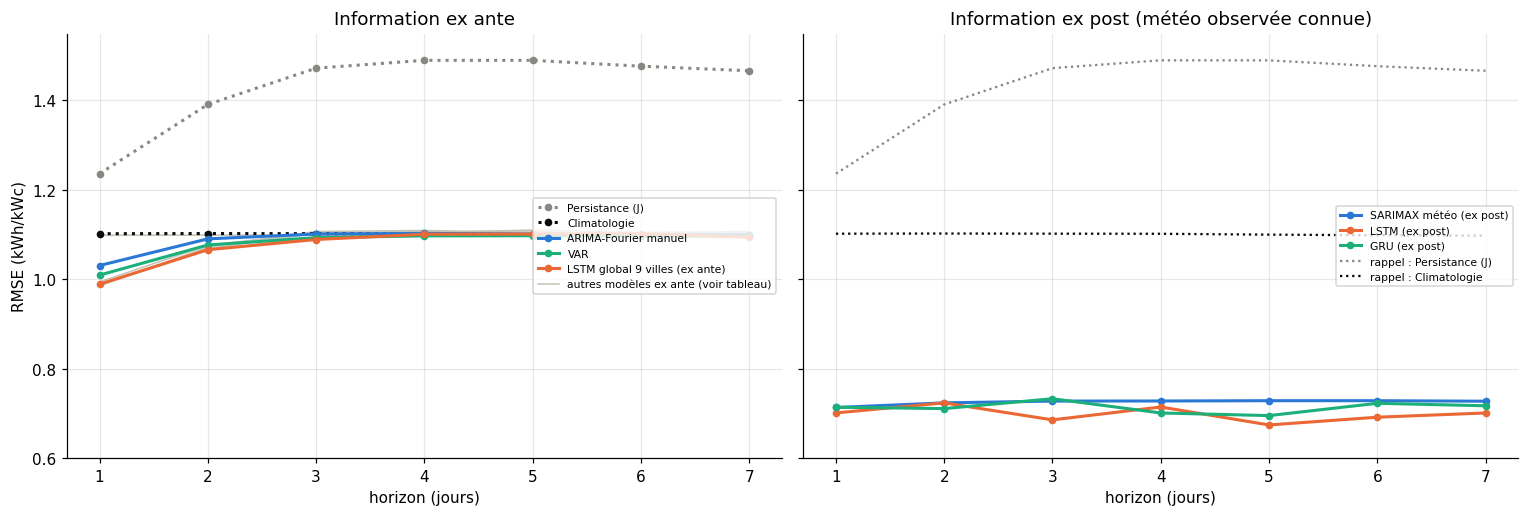

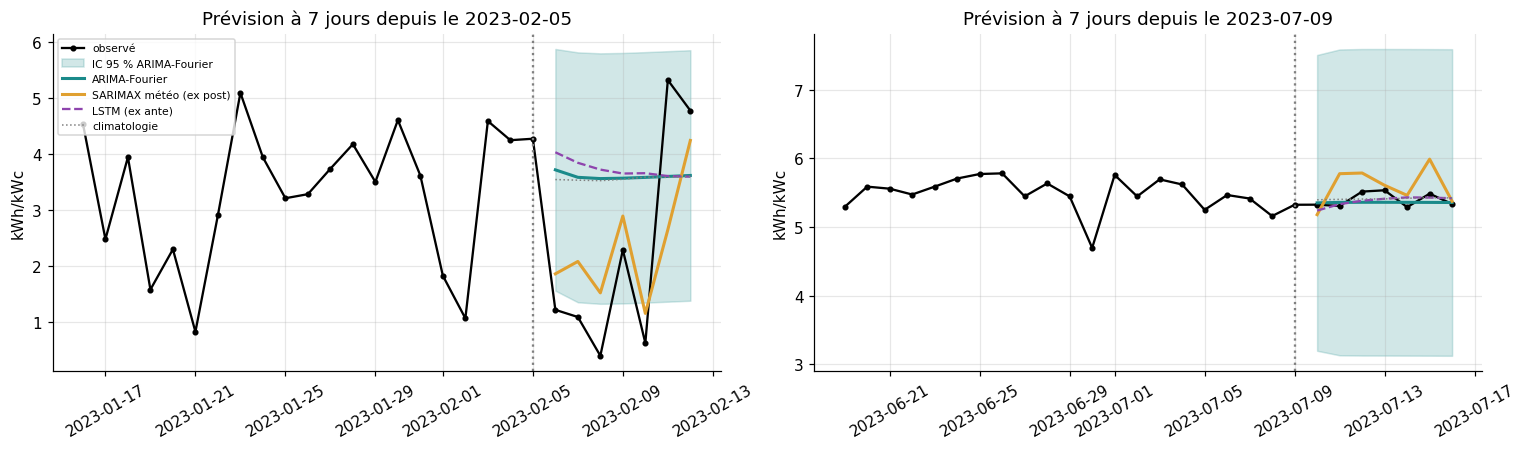

In [42]:
# Graphiques de synthèse : RMSE par horizon, puis deux exemples de prévision à 7 jours (un épisode
# nuageux d'hiver, une semaine d'été) avec l'intervalle à 95 % de l'ARIMA-Fourier.
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
# Onze modèles ex ante ne se lisent pas en couleurs distinctes : on met en évidence les références et les
# meilleurs modèles de chaque famille, les autres restent en gris fin (étiquetés dans le tableau).
EVIDENCE = {"Persistance (J)": ("#898781", ":"), "Climatologie": ("#0b0b0b", ":"),
            "ARIMA-Fourier manuel": ("#2a78d6", "-"), "VAR": ("#1baf7a", "-"),
            "LSTM global 9 villes (ex ante)": ("#eb6834", "-"), "SARIMAX météo (ex post)": ("#2a78d6", "-"),
            "LSTM (ex post)": ("#eb6834", "-"), "GRU (ex post)": ("#1baf7a", "-")}
for nom in prev:
    a = ax[0] if nom in EX_ANTE else ax[1]
    if nom in EVIDENCE:
        c, ls = EVIDENCE[nom]
        a.plot(range(1, H + 1), rmse_h.loc[nom], ls=ls, color=c, lw=2, marker="o", ms=4, label=nom, zorder=3)
    else:
        a.plot(range(1, H + 1), rmse_h.loc[nom], color="#c3c2b7", lw=1, zorder=1)
ax[0].plot([], [], color="#c3c2b7", lw=1, label="autres modèles ex ante (voir tableau)")
for ref in ("Persistance (J)", "Climatologie"):
    c, ls = EVIDENCE[ref]
    ax[1].plot(range(1, H + 1), rmse_h.loc[ref], ls=ls, color=c, lw=1.5, label=f"rappel : {ref}")
for a, titre in zip(ax, ("Information ex ante", "Information ex post (météo observée connue)")):
    a.set_title(titre); a.set_xlabel("horizon (jours)"); a.legend(fontsize=7, loc="center right")
ax[0].set_ylabel("RMSE (kWh/kWc)")
ax[0].set_ylim(0.6, rmse_h.to_numpy().max() * 1.04)
montrer(fig, "15_rmse_par_horizon")

i_hiver = int(np.argmax([np.std(y_all[t + 1:t + 1 + H]) if df.index[t].month in (12, 1, 2) else 0 for t in origines]))
i_ete = int(np.argmin([abs(df.index[t].dayofyear - 190) + 1000 * (df.index[t].year != 2023) for t in origines]))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for a, i in zip(ax, (i_hiver, i_ete)):
    t = origines[i]
    jp = df.index[t + 1:t + 1 + H]
    a.plot(df.index[t - 20:t + 1 + H], y_all[t - 20:t + 1 + H], color="k", marker="o", ms=3, label="observé")
    P, bas, haut = prev["ARIMA-Fourier manuel"]
    a.fill_between(jp, bas[i], haut[i], color="#1a8a8a", alpha=0.2, label="IC 95 % ARIMA-Fourier")
    a.plot(jp, P[i], color="#1a8a8a", lw=2, label="ARIMA-Fourier")
    a.plot(jp, prev["SARIMAX météo (ex post)"][0][i], color="#e0a030", lw=2, label="SARIMAX météo (ex post)")
    a.plot(jp, prev["LSTM (ex ante)"][0][i], color="#8e44ad", lw=1.5, ls="--", label="LSTM (ex ante)")
    a.plot(jp, prev["Climatologie"][0][i], color="grey", lw=1, ls=":", label="climatologie")
    a.axvline(df.index[t], color="grey", ls=":")
    a.set_title(f"Prévision à 7 jours depuis le {df.index[t].date()}"); a.set_ylabel("kWh/kWc")
    a.tick_params(axis="x", labelrotation=30)
ax[0].legend(fontsize=7)
montrer(fig, "16_exemples_prevision")

In [43]:
# Vérification croisée avec R : si le notebook R a été exécuté, on met côte à côte les RMSE des modèles
# communs. Des écarts faibles confirment que les deux implémentations estiment le même modèle.
f_r = RES / "R_metriques.csv"
if f_r.exists():
    r_tab = pd.read_csv(f_r, index_col=0)
    commun = [k for k in r_tab.index if k in tab.index]
    croise = pd.DataFrame({"RMSE Python": tab.loc[commun, "RMSE"], "RMSE R": r_tab.loc[commun, "RMSE"],
                           "MAE Python": tab.loc[commun, "MAE"], "MAE R": r_tab.loc[commun, "MAE"]})
    croise["écart RMSE (%)"] = 100 * (croise["RMSE R"] / croise["RMSE Python"] - 1)
    croise.to_csv(RES / "comparaison_R_python.csv")
    print(croise.round(4).to_string())
else:
    print("Fichier resultats/R_metriques.csv absent : compiler d'abord mini_projet_R.Rmd.")

                         RMSE Python  RMSE R  MAE Python   MAE R  écart RMSE (%)
Persistance (J)               1.4335  1.4335      0.9841  0.9841         -0.0000
Climatologie                  1.1002  1.1002      0.8558  0.8558         -0.0000
ARIMA-Fourier manuel          1.0892  1.0892      0.8405  0.8406          0.0016
ARIMA-Fourier auto            1.0892  1.0892      0.8405  0.8406          0.0017
VAR                           1.0811  1.0811      0.8344  0.8344          0.0000
SARIMAX météo (ex post)       0.7252  0.7242      0.5500  0.5493         -0.1500


**Lecture.** Les deux langages donnent les mêmes résultats : RMSE identiques pour la persistance, la climatologie et le VAR, écart de 0,002 % pour l'ARIMA-Fourier et de 0,15 % pour le SARIMAX météo. Ces petits écarts viennent des algorithmes d'estimation (maximum de vraisemblance exact en R, algorithme des innovations avec moindres carrés généralisés en Python) et du filtre, appliqué en R aux 500 jours qui précèdent chaque origine. Les deux grilles et les deux recherches automatiques retiennent le même ARIMA(1,0,0) à deux harmoniques.

## 7. Extensions
### 7.1 Corrélation dynamique entre pays

Une corrélation statique unique cache des variations dans le temps. On mesure, sur une fenêtre glissante
de 90 jours, la corrélation entre les anomalies de production de Tunis et celles de trois autres villes.

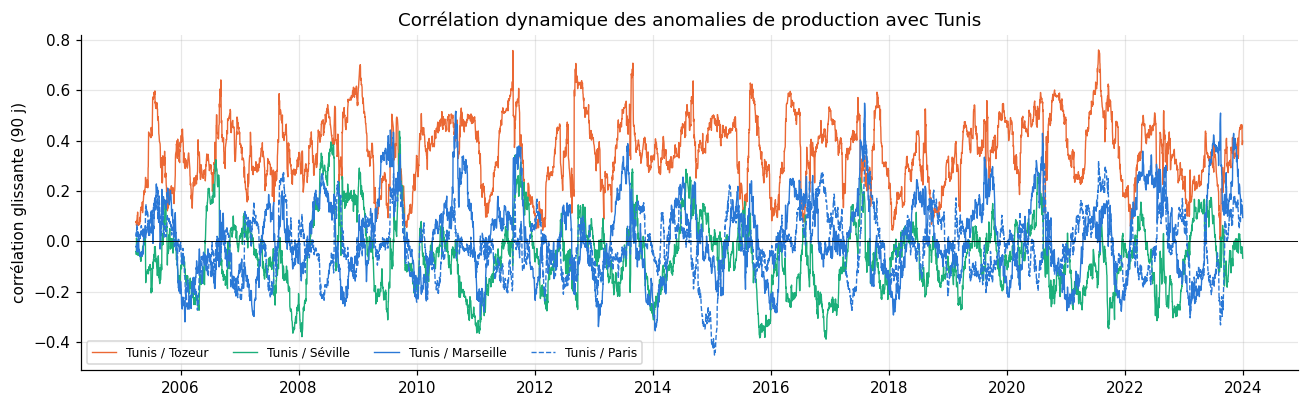

Corrélation des anomalies avec Tunis, par saison :
                  Tozeur  Séville  Marseille  Paris
hiver (DJF)       0.277   -0.067     -0.113 -0.028
printemps (MAM)   0.390   -0.024      0.135 -0.052
été (JJA)         0.402   -0.021      0.116  0.043
automne (SON)     0.366   -0.104     -0.060 -0.033
Distance approximative à Tunis (km) : {'Tozeur': 370, 'Séville': 1433, 'Marseille': 829, 'Paris': 1482}


In [44]:
# Anomalies = écart au cycle annuel (Fourier, estimé sur l'apprentissage) ; corrélation glissante 90 jours.
anoms = pd.DataFrame({SITES[s]["ville"]: anomalie_site(s) for s in ("tunis", "tozeur", "seville", "marseille", "paris")},
                     index=df.index)
glis = {v: anoms["Tunis"].rolling(90).corr(anoms[v]) for v in ("Tozeur", "Séville", "Marseille", "Paris")}
fig, ax = plt.subplots(figsize=(12, 3.8))
# Couleur du pays de la ville comparée (Tunisie, Espagne, France) ; Paris en tirets pour la distinguer de Marseille.
for v, c, ls in zip(glis, (COULEUR_PAYS["Tunisie"], COULEUR_PAYS["Espagne"], COULEUR_PAYS["France"], COULEUR_PAYS["France"]),
                    ("-", "-", "-", "--")):
    ax.plot(glis[v], lw=0.9, ls=ls, label=f"Tunis / {v}", color=c)
ax.axhline(0, color="k", lw=0.6); ax.set_ylabel("corrélation glissante (90 j)"); ax.legend(fontsize=8, ncol=4)
ax.set_title("Corrélation dynamique des anomalies de production avec Tunis")
montrer(fig, "17_correlation_dynamique")
corr_saison = pd.DataFrame({v: {s_: anoms.loc[np.isin(anoms.index.month, m_), "Tunis"].corr(anoms.loc[np.isin(anoms.index.month, m_), v])
                                for s_, m_ in (("hiver (DJF)", [12, 1, 2]), ("printemps (MAM)", [3, 4, 5]),
                                               ("été (JJA)", [6, 7, 8]), ("automne (SON)", [9, 10, 11]))}
                            for v in ("Tozeur", "Séville", "Marseille", "Paris")})
corr_saison.to_csv(RES / "py_correlation_saisonniere.csv")
print("Corrélation des anomalies avec Tunis, par saison :\n", corr_saison.round(3).to_string())
print("Distance approximative à Tunis (km) :", {v: int(6371 * np.arccos(
    np.sin(np.radians(SITES["tunis"]["lat"])) * np.sin(np.radians(SITES[s]["lat"])) +
    np.cos(np.radians(SITES["tunis"]["lat"])) * np.cos(np.radians(SITES[s]["lat"])) *
    np.cos(np.radians(SITES[s]["lon"] - SITES["tunis"]["lon"])))) for v, s in
    (("Tozeur", "tozeur"), ("Séville", "seville"), ("Marseille", "marseille"), ("Paris", "paris"))})

**Lecture.** Le même jour, Tunis et Tozeur (370 km) partagent une partie de leur météo : corrélation de 0,28 en hiver à 0,40 en été, avec des pointes à 0,7 lors de certains épisodes. Avec Séville, Marseille et Paris, la corrélation fluctue autour de zéro (|r| ≤ 0,14 par saison) : les anomalies des trois pays sont presque indépendantes le même jour. Conséquence pratique : un portefeuille d'installations réparties entre la France, l'Espagne et la Tunisie lisserait fortement la production journalière. La corrélation glissante varie beaucoup (de -0,4 à +0,5 pour Paris) : les épisodes météorologiques communs sont ponctuels, ce qu'une corrélation statique unique masquerait.

### 7.2 Validation externe : la simulation PVGIS face à la production nationale mesurée

Les séries PVGIS sont simulées à partir d'images satellite. Sont-elles réalistes ? On les confronte aux
productions mesurées sur les réseaux français (RTE) et espagnol (REE). La production nationale croît
avec le parc installé : on divise chaque série par sa moyenne glissante centrée sur 365 jours, ce qui
retire la croissance du parc et garde les variations météorologiques jour après jour.

Corrélation journalière (2016-2023, tendance retirée) : France r = 0.911 ; Espagne r = 0.874
Corrélation par année :
       France  Espagne
date                 
2016   0.907    0.895
2017   0.905    0.876
2018   0.926    0.888
2019   0.919    0.891
2020   0.917    0.879
2021   0.898    0.867
2022   0.914    0.896
2023   0.892    0.724


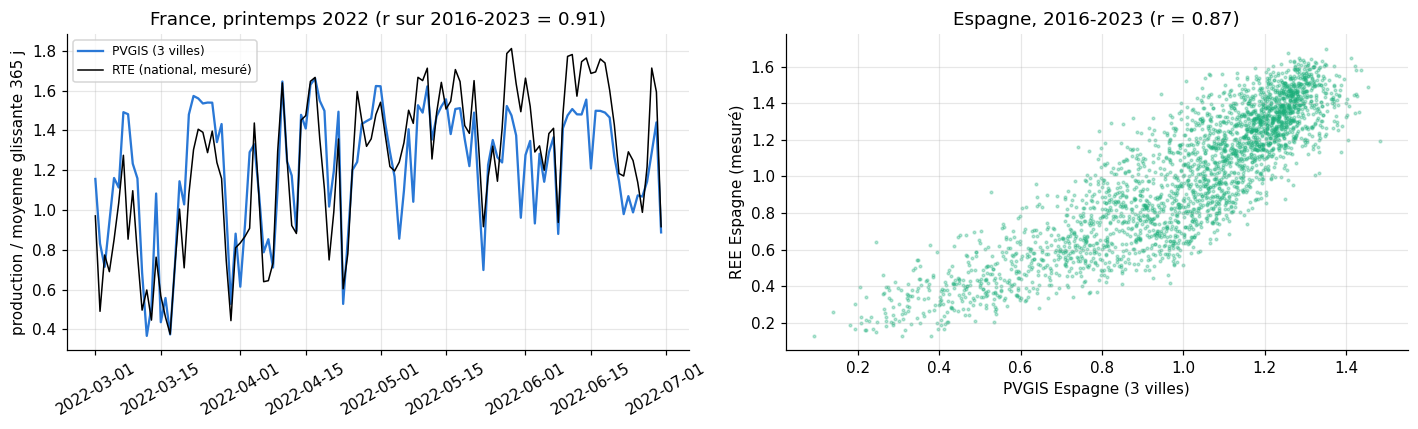

In [45]:
# Division par la moyenne glissante sur un an : retire la croissance du parc installé (absente de PVGIS, simulé à
# puissance constante) pour ne comparer que les variations météorologiques journalières.
def normaliser_tendance(s_):
    return s_ / s_.rolling(365, center=True, min_periods=300).mean()


pv_fr = panel[panel["code_pays"] == "FR"].groupby("date")[CIBLE].mean()
pv_es = panel[panel["code_pays"] == "ES"].groupby("date")[CIBLE].mean()
val = pd.DataFrame({"PVGIS France (moyenne 3 villes)": normaliser_tendance(pv_fr),
                    "RTE France (mesuré)": normaliser_tendance(rte["production_gwh"]),
                    "PVGIS Espagne (moyenne 3 villes)": normaliser_tendance(pv_es),
                    "REE Espagne (mesuré)": normaliser_tendance(ree["produccion_gwh"])}).loc["2016":"2023"]
r_fr = val["PVGIS France (moyenne 3 villes)"].corr(val["RTE France (mesuré)"])
r_es = val["PVGIS Espagne (moyenne 3 villes)"].corr(val["REE Espagne (mesuré)"])
d_fr = (val["PVGIS France (moyenne 3 villes)"] - 1).corr(val["RTE France (mesuré)"] - 1, method="spearman")
print(f"Corrélation journalière (2016-2023, tendance retirée) : France r = {r_fr:.3f} ; Espagne r = {r_es:.3f}")
an_corr = pd.DataFrame({"France": val.groupby(val.index.year).apply(
    lambda g: g["PVGIS France (moyenne 3 villes)"].corr(g["RTE France (mesuré)"])),
    "Espagne": val.groupby(val.index.year).apply(lambda g: g["PVGIS Espagne (moyenne 3 villes)"].corr(g["REE Espagne (mesuré)"]))})
an_corr.to_csv(RES / "py_validation_externe.csv")
print("Corrélation par année :\n", an_corr.round(3).to_string())
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
seg = val.loc["2022-03-01":"2022-06-30"]
ax[0].plot(seg.index, seg["PVGIS France (moyenne 3 villes)"], label="PVGIS (3 villes)", color=COULEUR_PAYS["France"])
ax[0].plot(seg.index, seg["RTE France (mesuré)"], label="RTE (national, mesuré)", color="k", lw=1)
ax[0].set_title(f"France, printemps 2022 (r sur 2016-2023 = {r_fr:.2f})"); ax[0].legend(fontsize=8)
ax[0].set_ylabel("production / moyenne glissante 365 j"); ax[0].tick_params(axis="x", labelrotation=30)
ax[1].scatter(val["PVGIS Espagne (moyenne 3 villes)"], val["REE Espagne (mesuré)"], s=3, alpha=0.3, color=COULEUR_PAYS["Espagne"])
ax[1].set_xlabel("PVGIS Espagne (3 villes)"); ax[1].set_ylabel("REE Espagne (mesuré)")
ax[1].set_title(f"Espagne, 2016-2023 (r = {r_es:.2f})")
montrer(fig, "18_validation_externe")

**Lecture.** Une fois retirée la croissance du parc, la moyenne des trois villes PVGIS suit de très près la production nationale mesurée : corrélation journalière de 0,91 pour la France (83 % de la variance) et de 0,87 pour l'Espagne sur 2016-2023, stable d'une année à l'autre (0,89 à 0,93 en France). Les données satellitaires utilisées dans tout le projet décrivent donc bien la réalité du terrain. L'écart résiduel a des causes connues : trois villes ne représentent pas tout un parc national, et beaucoup de centrales espagnoles suivent le soleil au lieu d'être fixes. La baisse observée en Espagne en 2023 (0,72) reste à expliquer ; deux hypothèses, que nos données ne permettent pas de trancher, sont la croissance très rapide du parc cette année-là (mal corrigée par la moyenne glissante) et l'écrêtement de la production aux heures de prix bas.

## 5. IA générative : construction des prompts

Les prompts sont construits à partir des sorties de ce notebook, pour que le LLM raisonne sur les vrais
chiffres et que chaque affirmation de sa réponse puisse être vérifiée. Les réponses sont obtenues par le
script `llm/interroger_llm.py` et conservées intégralement dans `llm/` ; notre interprétation, rédigée
avant de solliciter le LLM, est dans `llm/interpretation_experte.md`, et l'analyse critique dans le rapport.

In [46]:
# Prompt 1 : statistiques descriptives et tests de stationnarité seulement (aucun résultat de modèle),
# pour que le LLM propose des hypothèses de modèles « à l'aveugle ».
LLM = RACINE / "llm"
LLM.mkdir(exist_ok=True)
prompt1 = f"""Tu es un statisticien spécialiste des séries temporelles. Voici les statistiques descriptives d'une série journalière, sans autre information sur les modèles déjà essayés.

Série : production photovoltaïque journalière simulée par PVGIS pour 1 kWc installé à Tunis (kWh/kWc), du {train.index[0].date()} au {train.index[-1].date()} ({len(train)} observations). Séries associées : éclairement horizontal, nébulosité, température, pluie, aérosols.

Statistiques descriptives :
{stats_desc.to_string()}

Production moyenne par mois (kWh/kWc/jour) : {mois_moy['mean'].round(2).tolist()}
Écart-type par mois : {mois_moy['std'].round(2).tolist()}
Autocorrélation de la production aux retards 1, 2, 7, 30, 182, 365 : {np.round(acf_v[[1, 2, 7, 30, 182, 365]], 3).tolist()}
Autocorrélation de la série désaisonnalisée aux retards 1 à 7 : {np.round(acf_a[1:8], 3).tolist()}

Tests de stationnarité (ADF : H0 = racine unitaire ; KPSS : H0 = stationnarité) :
{tab_stat[['ADF stat', 'ADF p', 'KPSS stat', 'KPSS p']].to_string()}

Questions :
1. Quelles hypothèses de modèles proposes-tu de tester (au moins quatre), et pourquoi ?
2. Quels ordres de différenciation (d et D) recommandes-tu, et comment traiter la saisonnalité annuelle ?
3. Faut-il transformer la série ?
4. Quels pièges vois-tu ?
Réponds en français, de façon concise et structurée."""

# Prompt 2 : les résultats, pour une explication vulgarisée destinée à un décideur.
res_txt = tab[["information", "RMSE", "MAE", "MAPE (%)", "RMSE h=1", "RMSE h=7"]].round(3).to_string()
g_neb = granger[(granger["cause"] == "nebulosite_pct") & (granger["effet"] == CIBLE)].iloc[0]
prompt2 = f"""Voici les résultats d'une étude de prévision de la production photovoltaïque journalière d'une installation de 1 kWc à Tunis, à 7 jours. Les modèles ont été estimés sur {len(train)} jours ({train.index[0].date()} au {train.index[-1].date()}) et évalués sur {len(test)} jours ({test.index[0].date()} au {test.index[-1].date()}), avec {len(origines)} prévisions glissantes de 7 jours.

« ex ante » : le modèle ne connaît du futur que la date. « ex post » : il reçoit en plus la météo réellement observée sur les 7 jours (nébulosité, pluie, humidité, aérosols).

Erreurs de prévision (kWh/kWc/jour ; production moyenne sur le test : {Y.mean():.2f} kWh/kWc/jour) :
{res_txt}

Autres résultats :
- Causalité de Granger : le passé de la nébulosité aide à prévoir la production (F = {g_neb['F']:.1f}, p = {g_neb['p']:.1e}).
- Dans le SARIMAX météo, 10 points de nébulosité supplémentaires changent la production de {10 * coef.loc['nebulosite_pct', 'coef']:+.3f} kWh/kWc, plus {10 * coef.loc['neb_x_potentiel', 'coef'] / 100:+.4f} kWh/kWc par kWh/m² de rayonnement extraterrestre (effet plus fort l'été).
- Les erreurs ont une variance non constante (test ARCH-LM, p = {lm_p:.1e}), plus forte l'hiver, modélisée par : {NOM_G}.

Explique ces résultats à un décideur non statisticien (gestionnaire d'un parc de toitures solaires à Tunis), en 250 mots au maximum, sans jargon. Dis quel modèle tu recommandes et pourquoi."""

# Prompt 3 : recommandations de gestion à partir des prévisions, avec limites formulées par le LLM.
prompt3 = f"""À partir des résultats ci-dessous, propose des recommandations de gestion pour l'exploitant d'installations photovoltaïques en toiture à Tunis (planification de la maintenance et du nettoyage des modules, pilotage d'une batterie, engagement de production auprès du réseau, information des usagers).

Résultats :
- Meilleur modèle sans prévision météo (ex ante) : {meilleur_ante}, erreur absolue moyenne {tab.loc[meilleur_ante, 'MAE']:.2f} kWh/kWc/jour (MAPE {tab.loc[meilleur_ante, 'MAPE (%)']:.1f} %), RMSE à 1 jour {tab.loc[meilleur_ante, 'RMSE h=1']:.2f} et à 7 jours {tab.loc[meilleur_ante, 'RMSE h=7']:.2f}.
- Meilleur modèle avec météo observée (ex post) : {meilleur_post}, erreur absolue moyenne {tab.loc[meilleur_post, 'MAE']:.2f} kWh/kWc/jour (MAPE {tab.loc[meilleur_post, 'MAPE (%)']:.1f} %).
- Références : persistance (demain = aujourd'hui) MAE {tab.loc['Persistance (J)', 'MAE']:.2f} ; normale saisonnière MAE {tab.loc['Climatologie', 'MAE']:.2f}.
- Production annuelle d'1 kWc à Tunis : {synth.loc['tunis', 'productible_kwh_kwc_an']:.0f} kWh ; production moyenne en janvier {mois_moy['mean'].iloc[0]:.2f} et en juillet {mois_moy['mean'].iloc[6]:.2f} kWh/kWc/jour.
- L'incertitude des prévisions est plus forte de novembre à mars (variance conditionnelle, modèle {NOM_G}).
- Les données sont simulées par PVGIS à partir d'images satellite (2005-2023), pas mesurées sur une installation réelle.

Donne 4 recommandations concrètes. Pour chacune, formule toi-même ses limites et ses risques. Termine par une liste de ce que ces résultats ne permettent PAS de conclure. Réponds en français, 350 mots au maximum."""

for k, txt in enumerate((prompt1, prompt2, prompt3), start=1):
    (LLM / f"prompt_{k}.txt").write_text(txt, encoding="utf-8")
print(prompt1[:1500], "\n[...]")

Tu es un statisticien spécialiste des séries temporelles. Voici les statistiques descriptives d'une série journalière, sans autre information sur les modèles déjà essayés.

Série : production photovoltaïque journalière simulée par PVGIS pour 1 kWc installé à Tunis (kWh/kWc), du 2005-01-01 au 2022-02-05 (6245 observations). Séries associées : éclairement horizontal, nébulosité, température, pluie, aérosols.

Statistiques descriptives :
                  moyenne  écart-type  variance    min      max  skewness  kurtosis (excès)
pv_kwh_kwc          4.295       1.402     1.965  0.211    6.427    -0.815            -0.277
ghi_kwh_m2          4.947       2.258     5.098  0.419    8.970     0.068            -1.322
nebulosite_pct     38.295      27.333   747.107  0.000  100.000     0.356            -0.887
t2m_moy_c          18.712       6.062    36.743  4.908   36.027     0.158            -1.103
precipitation_mm    1.159       3.556    12.648  0.000   78.900     6.815            78.351
aerosols_

In [47]:
# Affichage des réponses du LLM si elles ont déjà été générées (voir llm/interroger_llm.py).
for k in (1, 2, 3):
    f = LLM / f"reponse_{k}.md"
    print(f"\n{'=' * 30} Réponse au prompt {k} {'=' * 30}")
    print(f.read_text(encoding="utf-8") if f.exists() else "(pas encore générée)")


============================== Réponse au prompt 1 ==============================
<!-- modèle : qwen3-vl:8b-instruct (Ollama, local) | options : {'temperature': 0, 'seed': 42, 'num_ctx': 8192} | date : 2026-10-10 -->

**1. Hypothèses de modèles à tester :**  
- **Modèle ARIMA saisonnier (SARIMA)** : la série présente une forte autocorrélation à court terme (lag 1 : 0.512) et une saisonnalité annuelle (lag 365 : 0.329), avec une tendance visible.  
- **Modèle avec décomposition saisonnière (Fourier)** : la désaisonnalisée est stationnaire (ADF p=0.0, KPSS p=0.10) mais avec une tendance, suggérant un modèle avec tendance et composante saisonnière.  
- **Modèle GARCH pour la variance** : l’écart-type mensuel varie (ex. : 0.41 en juillet vs 1.25 en janvier), et la série présente une asymétrie (skewness = -0.815), indiquant une volatilité hétéroscédastique.  
- **Modèle à variables exogènes (SARIMAX)** : les séries météorologiques (nébulosité, température, aérosols) sont fortement corrélée

In [48]:
# Versions des bibliothèques, pour la reproductibilité.
import arch, sklearn, statsmodels, prophet, xgboost
print("python", sys.version.split()[0])
for mod in (np, pd, matplotlib, statsmodels, pm, arch, sklearn, xgboost, torch, prophet):
    print(f"{mod.__name__:12s} {mod.__version__}")

python 3.14.2
numpy        2.3.5
pandas       2.3.3
matplotlib   3.10.8
statsmodels  0.15.0
pmdarima     2.1.1
arch         8.0.0
sklearn      1.8.0
xgboost      3.1.3
torch        2.12.1+cpu
prophet      1.5.0
